In [3]:
import os
os.environ["PATH_TO_POSYDON"] = "/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages"
print(os.getenv("PATH_TO_POSYDON"))
print(os.getenv("PATH_TO_POSYDON_DATA"))

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages
/srv/astro/projects/posydon/data_sync_staging/POSYDON_datasets/latest_stable/


In [1]:

import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.optimize import newton

import posydon
import posydon.utils.constants as const
from posydon.popsyn.synthetic_population import Population
from posydon.utils.common_functions import roche_lobe_radius, orbital_separation_from_period
from posydon.utils.posydonwarning import Pwarn


import sys
sys.path.append('/home/users/a/aguetar1/Posydon_Data')
import XRB_functions as xrb

print("Posydon version:", posydon.__version__)

Posydon version: 2.2.2


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
class color:
    # Reset
    END = '\033[0m'

    # Styles
    BOLD = '\033[1m'
    DIM = '\033[2m'
    ITALIC = '\033[3m'
    UNDERLINE = '\033[4m'
    REVERSE = '\033[7m'
    STRIKE = '\033[9m'

    # Standard colors
    BLACK = '\033[30m'
    RED = '\033[31m'
    GREEN = '\033[32m'
    YELLOW = '\033[33m'
    BLUE = '\033[34m'
    PURPLE = '\033[35m'
    CYAN = '\033[36m'
    WHITE = '\033[37m'

    # Bright colors
    BRIGHT_BLACK = '\033[90m'
    BRIGHT_RED = '\033[91m'
    BRIGHT_GREEN = '\033[92m'
    BRIGHT_YELLOW = '\033[93m'
    BRIGHT_BLUE = '\033[94m'
    BRIGHT_PURPLE = '\033[95m'
    BRIGHT_CYAN = '\033[96m'
    BRIGHT_WHITE = '\033[97m'

    # Background colors
    BG_RED = '\033[41m'
    BG_GREEN = '\033[42m'
    BG_YELLOW = '\033[43m'
    BG_BLUE = '\033[44m'


### 1. Definiton of functions

- Efficiencies

In [ ]:
"""
def BH_efficiency(mass, spin, dimensional_spin = False): 
    '''
    Compute the radiative efficiency of a Kerr black hole (or Schwarzchild BH if spin = 0)
    as a function of the spin parameter a and the mass according to Novikov-Thorne radiative efficiency [[1]_].
            
    
    Parameters
    ---------- 
    mass : float
        Mass of the central black hole in Msun
    spin : float
        Spin of the black hole. Can be given as dimensionless spin "*a**" or dimensional spin "*a*".
        Its value can be given either positively (prograde accretion) or negatively (retrograde accretion) 
        (spin  ∈ [-0.998, 0.998] with ± 0.998 being the Thorne limit).
    dimensional_spin : bool, optional 
        If True, convert dimensional spin "*a [J/M]*" to dimensionless spin "*a**".

    Returns
    -------
    tuple
        A tuple with three floats: (E_ISCO, r_tilde, eta).
        - E_ISCO (float): Specific energy at the ISCO, in units of mc^2.
        - r_tilde (float): Radius of the ISCO in units of GM / c^2.
        - eta (float): Radiative efficiency (1 - E_ISCO), dimensionless.

    References
    ----------
    .. [1] Bambi, C., Malafarina, D., & Tsukamoto, N. (2014).
            "Note on the radiation emitted by a thin accretion disk around a rotating compact object."
            *Phys. Rev. D*, 89(12), 127302. https://arxiv.org/abs/1406.2181
    '''
   
    if  mass < 0 : 
        raise ValueError("Mass must be positive")

    M = mass * const.Msun # [gr]

    # Conversion to dimensionless spin if needed
    if dimensional_spin:
        a_star = const.clight * spin /(const.standard_cgrav * M)
    else: 
        a_star = float(spin)
    
    # To control that the spin is in the range that gives the maximal efficiency
    a_star = float(np.clip(a_star, -0.998, 0.998))

    #=== Compute efficiency [1]=== 
    
    # Use sign = +1 for spin ≥ 0 (prograde) and -1 otherwise (retrograde)
    sign = 1 if a_star >= 0 else -1

    Z1 = 1 + (1 - a_star**2)**(1/3) * ((1 + a_star)**(1/3) + (1 - a_star)**(1/3))
    Z2 = np.sqrt(3 * a_star**2 + Z1**2)

    # Radius at the innermost stable circular orbit (ISCO)
    r_tilde = 3 + Z2 - sign * np.sqrt((3 - Z1)*(3 + Z1 + 2 * Z2)) # Dimensionless

    # Energy at ISCO in units of mc^2 (i.e E_ISCO < 1, E = 1 means particle energy at infinity)
    E_ISCO = (r_tilde**(3/2) - 2 * r_tilde**(1/2) + a_star)/(r_tilde**(3/4) * np.sqrt(r_tilde**(3/2) - 3 * r_tilde**(1/2) + 2 * a_star))
    
    # Radiative efficiency
    eta = 1 - E_ISCO
    return E_ISCO, r_tilde, eta


def NS_efficiency(mass,log_radius, **kwargs):
    '''
    Compute the radiative efficiency of a neutron star as a function of its mass and radius. 
    
    If there is a magnetic field, it will compare the magnetospheric radius with the radius of the neutron star to compute the accretion radius accordingly to [[1]_]. 
    The strength of the magntic field affects the magnetospheric radius of the NS. and therefore if the magnetospheric radius is larger than the NS radius, 
    the efficiency is lowered because the accretion disk is truncated and accretion happens along the magnetic lines up to the poles on smaller surface area.

    Parameters
    ----------
    mass : float
        Mass of the neutron star in [M⊙]
    log_radius : float
        Log10(Radius of the neutron star) in [R⊙]
    **kwargs : dict, optional
        - B_surf (float) : Surface magnetic field of the neutron star in [Gauss]. If provided, the magnetosphere radius will be computed.
        - accretor_logMdot (float) : Log10(Mass accretion rate onto the neutron star) in [M⊙/yr]. Required if B_surf is provided to compute the magnetosphere radius.

    Returns
    -------
    eta : float
        Radiative efficiency of the neutron star, dimensionless.
    R : float
        Accretion radius used for the efficiency computation in [cm]. It is either the NS radius or the magnetosphere radius if B_surf is provided and R_mag > R_NS.

    References
    ----------
    .. [1] Misra et al. (2024), Astronomy & Astrophysics, 682, A69,
           **Exploring the nature of Ultra-luminous X-ray sources across stellar population ages using detailed binary evolution calculations**
           https://doi.org/10.1051/0004-6361/202347880


    '''
    #===== Optional parameters =====
    B_surf = kwargs.pop('B_surf', None)  # [Gauss]
    accretor_logMdot = kwargs.pop('accretor_logMdot', None)  # [M⊙/yr]

    #===== Mass =====
    if mass is None or not np.isfinite(mass) or mass <= 0.0:
            mass = 1.45 # Default mass of a NS in [M⊙]
    
    M = float(mass) * const.Msun # [gr]

    #===== Radius =====
    if log_radius is None or not np.isfinite(log_radius):
            # fallback radius ~12.5 km -> 1.25e6 cm
            R_Ns_cm = 1.25e6
            
    else:
            R_Ns_sun = 10.0**float(log_radius) # [R⊙]
            R_Ns_cm = R_Ns_sun * const.Rsun # [cm]
            

    # If there is a magnetic field, compute the magnetosphere radius R_mag (POSYDON do not provide B field for now)
    R_mag = 0.0
    if B_surf is not None and accretor_logMdot is not None:
        mu = B_surf * R_Ns_cm**3 # Magnetic dipole moment
        Mdot_NS = 10**accretor_logMdot * const.Msun / const.secyer  # [g/s]
        R_mag = (mu**4 / (2 * const.standard_cgrav * M * Mdot_NS**2))**(1/7)  # [cm]

    if R_mag > R_Ns_cm:
        R = R_mag # Magnetic field truncates the accretion disk
    else:
        R = R_Ns_cm # R_mag inside R_NS, accretion disk reaches the NS surface
  
    #===== Efficiency computation =====
    eta = const.standard_cgrav * M /(R * const.clight**2) # dimensionless ~0.1-0.3
    
    return eta, R 

"""

- Other functions

In [ ]:
"""
def Orbital_sep_and_velo_from_period(Mass1, Mass2, period_days):
    '''
    Calculate the orbital separation "a" given the period of the system from the 3rd Kepler's law. 
    And calculate also the orbital velocity of the companion/donor star.

    Parameters 
    ---------
    Mass1 : float 
        Mass of the central body/accretor where Mass1 > Mass2 in [M⊙]
    Mass2 : float
        Mass of the orbiting object/donor where Mass2 < Mass1 in [M⊙]
    period_days : float 
        Period of the orbiting companion in [days]
    
    Returns
    -------
    a_cm : float
        Orbital separation of the binary system in [cm]
    V_orb : float
        Orbital velocity of the companion/donor star in [cm/s]
    '''
    #===== Control parameters =====
    if Mass1 < 0.0 or Mass2 < 0.0:
        raise ValueError("Mass1 and Mass2 must be non-negative values.")
    if period_days <= 0.0:
        raise ValueError("Orbital period must be a positive value.") 

    #===== Calculation =====
    period_seconds = period_days * const.day2sec
    M1_gr = Mass1 * const.Msun
    M2_gr = Mass2 * const.Msun
    a_cm = (const.standard_cgrav * (M1_gr + M2_gr) * period_seconds**2 /(4 * np.pi**2))**(1/3) # [cm]

    V_orb = 2 * np.pi * a_cm / (float(period_seconds)) # [cm/s]

    return a_cm, V_orb


def BHL_mdot_acc(Macc_Msun, donor_mass_Msun, accretor_type, 
                 Mdot_w_Msun_per_yr, a_cm, ecc, V_wind, **kwargs):
    '''
    Calculate the Bondi-Hoyle Littleton accretion rate through winds in gram per second.\n 
    User can choose if the winds, in presence of a black hole, must form a disk before being accreted. 

    Parameters
    ----------
    Macc_Msun : float 
        Mass of the accretor in [M⊙]
    donor_mass_Msun : float
        Mass of the donor in [M⊙]
    accretor_type : str
        Type of the accretor. Can be either 'NS' or 'BH'.
    r_ISCO : float
        Radius of the innermost stable circular orbit (ISCO) in [cm] of BH accretor. Only used if wind_disk_formation = True.
    eta : float
        Radiative efficiency of the accretor (dimensionless). Only used if wind_disk_formation = True.
    Mdot_w_Msun_per_yr : float
        Accretion rate from winds in [M⊙/yr] (Usually represents the difference between total mass loss 
        rate from the donor and the mass transfer rate through RLO)
    a_cm : float
        Orbital separation of the binary system in [cm]
    ecc : float
        Orbital eccentricity of the donor star
    V_wind : float
        Wind velocity from the donor to the accretor [cm/s]
    **kwargs : dict, optional
        Additional keyword arguments:
        - alpha_BHL (float, default = 1.5) : Alpha parameter of Bondi-Hoyle Littleton (alpha_BHL ∈ [1, 2]).
        - wind_disk_formation (bool, default = False) : Whether to check for disk formation criteria around BH accretor.
        - r_ISCO (float) : Radius of the innermost stable circular orbit (ISCO) in [cm] of BH accretor. Only used if wind_disk_formation = True.
        - eta (float) : Radiative efficiency of the accretor (dimensionless). Only used if wind_disk_formation = True.
        Any unknown keys will raise a TypeError.
            
    Returns
    -------
    Mdot_BHL: float 
        Accretion rate of Bondi-Hoyle Littleton through winds in [gr/s]  

    References
    ----------
    .. [1] Bondi, H., & Hoyle, F. 1944, MNRAS, 104, 273
    .. [2] Sen, K. ,Xu, X. -T., Langer, N., El Mellah, I. , Schurmann, C., Quast, M., 2021, A&A,
           Equation 10
    .. [3] Frank, J., King, A., & Raine, D. (2002). "Accretion Power in Astrophysics: Third Edition" Chapter 4.9 pages 73-74.
           *Cambridge University Press*. https://doi.org/10.1017/CBO9781139164417
    .. [4] Bambi, C., Malafarina, D., & Tsukamoto, N. (2014).
            "Note on the radiation emitted by a thin accretion disk around a rotating compact object."
            *Phys. Rev. D*, 89(12), 127302. https://arxiv.org/abs/1406.2181
    '''
    #===== Optional parameters =====
    alpha_BHL = kwargs.pop('alpha_BHL', 1.5) # Alpha parameter of Bondi-Hoyle Littleton
    if not (1.0 <= alpha_BHL <= 2.0):
        raise ValueError("alpha_BHL must be in the range [1.0, 2.0]")
    
    wind_disk_formation = kwargs.pop('wind_disk_formation', False)
    r_ISCO = kwargs.pop('r_ISCO', None)
    eta = kwargs.pop('eta', None)

    if wind_disk_formation and accretor_type == 'BH':
        if r_ISCO is None or eta is None:
            raise ValueError("r_ISCO and eta must be provided when wind_disk_formation is True.")
        
    if kwargs:
        raise TypeError(f"BHL_mdot_acc: unknown parameter {list(kwargs.keys())}")
    
    #===== Control parameters =====
    if a_cm is None or not np.isfinite(a_cm) or a_cm <= 0.0:
        return 0.0
    if V_wind is None or not np.isfinite(V_wind) or V_wind < 0.0:
        return 0.0
    
    #===== Masses =====
    Macc = float(Macc_Msun) * const.Msun # [gr]
    Mdon = float(donor_mass_Msun) * const.Msun # [gr]
    
    #===== Orbital mechanics (Keplerian) =====
    ecc = 0.0 if (ecc is None or not np.isfinite(ecc)) else float(np.clip(ecc, 0.0, 0.999))

    # Orbital frequency [rad/s]
    Omega = np.sqrt(const.standard_cgrav * (Mdon + Macc) / a_cm**3)
    # Random orbital phase [s]
    t0 = np.random.rand() * (2.0 * np.pi / Omega)
    # Eccentric anomaly at time t0 from Kepler's equation
    E = newton(lambda x: x - ecc * np.sin(x) - Omega * t0, np.pi/2, maxiter=100)

    b = a_cm * np.sqrt(1.0 - ecc**2)
    r_vec = np.array([a_cm * (np.cos(E) - ecc), b * np.sin(E)])  # Radius in vectorial form [cm]
    v_dir = np.array([-a_cm * np.sin(E), b * np.cos(E)]) # Velocity direction vector [cm] (derivative of r_vec)
    R = np.linalg.norm(r_vec, axis=0)  # Distance between the two stars [cm]
    v_dir_norm = np.linalg.norm(v_dir, axis=0)

    cos_angle = np.dot(v_dir, r_vec) / (v_dir_norm * R)

    V_orb = np.sqrt(const.standard_cgrav * (Mdon + Macc) * (2.0 / R - 1.0 / a_cm))  # Relative velocity [cm/s]

    # Total relative velocity of the winds [3] 
    V_rel = np.sqrt(V_orb**2 + V_wind**2 + 2* V_orb * V_wind * cos_angle)  # [cm/s]
    

    # Accreted material from winds
    Mdot_w = float(max(Mdot_w_Msun_per_yr, 0.0)) * const.Msun / const.secyer  # [g/s]

   
    # From [1], we calculate the BHL accretion rate
    if V_wind == 0.0:
        frac = 1.0
        Pwarn(f"Warning: Wind velocity is zero, setting accretion fraction to 1.0 (PID={os.getpid()})", # type: ignore
              category="InappropriateValueWarning")
    elif V_rel == 0.0:
        frac = 0.0
        Pwarn(f"Warning: Orbital velocity and wind velocity are zero, setting BHL accretion rate to 0.0 g/s (PID={os.getpid()})", # type: ignore
              category="InappropriateValueWarning")
    elif R == 0.0:
        frac = 0.0
        Pwarn(f"Warning: Orbital separation is zero, setting BHL accretion rate to 0.0 g/s (PID={os.getpid()})", # type: ignore
              category="InappropriateValueWarning")
    else:
        frac = alpha_BHL * (const.standard_cgrav * Macc)**2 / (2 * V_rel**3 * V_wind * R**2)
    
    Mdot_BHL = frac * Mdot_w  # [g/s]

    # From [2], check if an accretion disk can form around the BH accretor
    if wind_disk_formation and accretor_type == 'BH':
        gamma = r_ISCO/6.0 # From [4]
        q = Mdon / Macc
        Rdisk_div_RISCO = ((2/3) * (eta / (1 + q))**2 * (V_orb /(const.clight * 0.01))**(-2) 
                           * (1 + (V_wind/V_orb)**2)**(-4) / gamma) 
        if Rdisk_div_RISCO < 1.0: # No disk formed
            Mdot_BHL = 0.0 # [g/s]

    return float(Mdot_BHL)


def Eddington_limit(accretor_mass, Donor_surface_H1, eta):
    '''
    Compute the Eddington accretion rate from the accretor mass, its accretion efficieny and the content of hydrogen at the surface of the donor star.
    Also compute the Eddington luminosity.

    Parameters
    ----------
    accretor_mass : float
        Mass of the accretor in [M⊙].
    Donor_surface_H1 : float
        Hydrogen mass fraction of the donor star's surface (surface_h1_f).
    eta : float
        Radiative efficiency of the accretor (NS or BH).

    Returns
    -------
    Mdot_Edd_gps : float
        Eddington accretion rate in [g/s].
    L_edd : float 
        Eddington luminosity in [erg/s].
    
    '''
    L_edd = 4.0 * np.pi * const.standard_cgrav * accretor_mass * const.Msun * const.clight /(0.2 * (1.0 + Donor_surface_H1)) # [erg/s]

    Mdot_Edd_gps = L_edd / (eta * const.clight**2) # [g/s]
    

    return Mdot_Edd_gps, L_edd


def Wind_velocity_BHL(accretor_mass, donor_mass, donor_logR, donor_logL, 
                      donor_surface_H1, donor_He_core_mass, log_Mdot_wind, a_cm, 
                      Wind_fed_scheme = None, Vwind_scheme ='Hurley+2002'):
    '''
    Compute the wind velocity from the donor/companion star in cm/s.
    For wind-fed systems, a wind scheme calculation can be chosen and for donor star a filling threshold for RLO can be enabled [[1]_][[4]_].

    Parameters
    ----------
    accretor_mass : float
        Mass of the accretor in [M⊙]. Used to compute the Roche lobe radius.
    donor_mass : float
        Mass of the donor star in [M⊙]
    donor_logR : float
        Log10(Radius of the donor star) in [R⊙]
    donor_logL : float
        Log10(Luminosity of the donor star) in [L⊙]
    donor_surface_H1 : float
        Hydrogen mass fraction of the donor star's surface (surface_h1_f).
    donor_He_core_mass : float
        Helium core mass of the donor star in [M⊙]
    log_Mdot_wind : float
        Log10(Mass loss rate from the donor star's wind) in [M⊙/yr]
    a_cm : float
        Orbital separation of the binary system in [cm]
    Wind_fed_scheme : str, (default=None)
        If 'HiraiMandel21', the donor star must fill at least 80% of its Roche lobe to get winds [[4]_]. Default is None.
    Vwind_scheme : str (default='Hurley+2002')
        Scheme to compute the wind velocity. Can be either 'Hurley+2002' or 'Kudritzki+2000'.
    
    Returns
    -------
    V_wind : float
        Wind velocity from the donor to the accretor [cm/s].

    References
    ----------
    .. [1] Misra et al. A&A 672, A99 (2023) https://arxiv.org/abs/2209.05505v2
    .. [2] Hurley, J. R., Tout, C. A., & Pols, O. R. 2002, MNRAS, 329, 897
    .. [3] Kudritzki, R.-P., & Puls, J. 2000, ARA&A, 38, 613
    .. [4] Hirai, R. & Mandel, I. (2021).  
           *Conditions for accretion disc formation and observability of wind-accreting X-ray binaries.*  
           Publications of the Astronomical Society of Australia, 38, e056.  
           doi:10.1017/pasa.2021.53  
           https://doi.org/10.1017/pasa.2021.53
    .. [5] Sander A. A. C., Vink J. S., 2020, MNRAS, 499, 873
    '''

    RL_donor_Rsun = roche_lobe_radius(donor_mass, accretor_mass, a_cm) / const.Rsun # [R⊙] 

    # In [1] Misra et al. A&A 672. A99 (2023), based on [4] Hirai & Mandel 2021
    if 10**donor_logR < 0.8 * RL_donor_Rsun and Wind_fed_scheme == 'HiraiMandel21': # Must fill at least 80% of its Roche lobe to get winds
        V_wind = 0.0 # No wind
    else:

        Teff = stefan_boltzmann_law(10.0**donor_logL, 10.0**donor_logR) # [K]

        #===== Wind velocity calculation schemes =====
        # [2] Hurley et al. 2002
        if Vwind_scheme == 'Hurley+2002':
            # For H-rich stars
            if donor_surface_H1 > 0.01:
                if donor_He_core_mass > 0.0 and 10.0**donor_logR > 900.0:
                    beta = 0.125
                elif donor_mass > 120.0:
                    beta = 7.0
                elif donor_mass < 1.4:
                    beta = 0.5
                else:
                    beta = 0.5 + (donor_mass - 1.4) / (120.0 - 1.4) * (6.5)
            else:  # For He-rich stars
                if donor_mass > 120.0:
                    beta = 7.0
                elif donor_mass < 10.0:
                    beta = 0.125
                else:
                    beta = 0.125 + (donor_mass - 10.0) / (120.0 - 10.0) * (6.875)

            f_m = float(np.sqrt(beta))

        # [3] Kudritzki & Puls 2000
        elif Vwind_scheme == 'Kudritzki+2000':
            if Teff >= 21000:
                f_m = 2.65
            elif Teff <= 10000:
                f_m = 1.0
            else:
                f_m = 1.4
        else:
            raise ValueError(f"Invalid scheme '{Vwind_scheme}'. Choose 'Hurley+2002' or 'Kudritzki+2000'.")
        
        V_esc = np.sqrt(2.0 * const.standard_cgrav * donor_mass * const.Msun / (10**donor_logR * const.Rsun)) # [cm/s] 
        V_wind = f_m * V_esc  # [cm/s]

        # [5] Sander & Vink 2020 
        if (donor_surface_H1 < 0.4 and Teff > 1.0e4):
            if log_Mdot_wind >= -5.25:
                slope = (3.7 - 3.25) / (-2.5 + 5.25)
            else:
                slope = (3.25 - 3.75) / (-5.25 + 7.25)
            V_wind = 10 ** (slope * log_Mdot_wind + 3.25 + 5.25 * slope) * 1000
        else:
            pass

    return V_wind


def Be_XRB_Lx(orbital_period_days):
    '''
    Compute the X-ray luminosity of a system containing a Be star as companion. The donor star should have [[1]_]:
    - Surface velocity higher than 70% of its critical velocity
    - Orbital period between 10 and 300 days
    - Its state should be detached and not undergoing RLO
    - Donor mass of at least 6 M⊙

    Be stars have fast rotation surface which, when the surface velocity is close to the critical velocity,
    can form a decretion disk around them. The compact object (NS or BH) can then accrete material from this disk
    if it passes through the Roche lobe of the Be star and thus leading to X-ray emission when accreted.

    Parameters
    ----------
    orbital_period_days : float
        Orbital period of the binary system in [days].

    Returns
    -------
    Lx : float
        X-ray luminosity of the system [erg/s].
    
    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*. 
           https://arxiv.org/abs/2209.05505v2 
    .. [2] Dai, Hai-Lang ;  Liu, Xi-Wei ;  Li, Xiang-Dong (2006). 
           *Exploration of the Ps-Porb Relation for Wind-fed X-Ray Pulsars*.
           https://doi.org/10.1086/508735

    '''
    #===== Calculation =====
    # Based on the work of [1] Misra+2023 and [2] Dai+2006

    if 10.0 <= orbital_period_days <= 300.0:
    
        Lx_Be = 1e35 * (10**(4.53))/((orbital_period_days)**(1.5)) # [erg/s]
    else:
        Lx_Be = 0.0

    return Lx_Be


def stefan_boltzmann_law(Luminosity, Radius):
    '''
    Compute the effective temperature given the luminosity and radius of 
    a star using the Stefan-Boltzmann law.
    
    Parameters
    ----------
    Luminosity : float
        Luminosity of the star in [L⊙]
    Radius : float
        Radius of the star in [R⊙]

    Returns
    -------
    Teff : float
        Effective temperature of the star in [K].

    '''

    #===== Check inputs =====
    if Luminosity <= 0.0 or Radius <= 0.0:
        raise ValueError("Luminosity and Radius must be positive values.")
    
    #===== Calculation =====
    Teff = ((Luminosity * const.Lsun) / (4.0 * np.pi * (Radius * const.Rsun)**2.0 * const.boltz_sigma))**(1.0/4.0)
    
    return Teff


def Compute_Lx(donor_mass, donor_log_R, donor_logL, accretor_mass, accretor_log_R, accretor_type, 
               donor_log_mdot, log_Mtransfer_rate, accretor_log_mdot,
               H1_content_donor, He_core_mass_donor, orbital_period_days, ecc, accretor_spin  = 0.0, 
               **kwargs): 
    '''
    Compute the X-ray luminosity of a binary system as long as there is a compact accretor (NS or BH)
    and a donor star losing mass through Roche lobe overflow (RLO) and/or winds. The state of the system
    is saved as well (sub-Eddington, super-Eddington) according to the beaming of the total system.
    
    Parameters
    ----------
    donor_mass : float
        Mass of the donor star in [M⊙]
    donor_log_R : float
        Log10(Radius of the donor star) in [R⊙]
    donor_logL : float
        Log10(Luminosity of the donor star) in [L⊙]
    accretor_mass : float
        Mass of the accretor in [M⊙]
    accretor_log_R : float
        Log10(Radius of the accretor) in [R⊙]
    accretor_type : str
        Type of the accretor. Can be either 'NS' or 'BH'
    donor_log_mdot : float
        Log10(Mass loss rate from the donor star) in [M⊙/yr]. Is the total mass loss rate from the donor star including both RLO and winds.
    log_Mtransfer_rate : float
        Log10(Mass transfer rate) in [M⊙/yr]. A fraction of donor_log_mdot.
    accretor_log_mdot : float
        Log10(Mass accretion rate onto the accretor) in [M⊙/yr]. Is the total mass accretion rate onto the accretor including both RLO and winds.
    H1_content_donor : float
        Hydrogen mass fraction of the donor star's surface (surface_h1_f).
    He_core_mass_donor : float
        Helium core mass of the donor star in [M⊙] (he_core_mass_f).
    orbital_period_days : float
        Orbital period of the binary system in [days] initially set a 15 days. If not given, wind accretion cannot be computed.
    ecc : float
        Orbital eccentricity of the system
    accretor_spin : float
        Spin of the accretor in the case of BH accretor. Initially set at 0.0 (non spinning BH (Schwarzchild)).
    **kwargs : dict, optional
        Additional keyword arguments:
        - alpha_BHL (float, default=1.5) : efficiency parameter for Bondi-Hoyle-Lyttleton accretion.
        - Wind_fed_scheme (str, default=None) : Whether to check that the donor star fills at least 80% of its Roche lobe to get winds. Option : 'HiraiMandel21'
        - Vwind_scheme (str, default='Hurley+2002') : Wind velocity scheme to use in Wind_velocity_BHL function. 
        Can be either 'Hurley+2002' or 'Kudritzki+2000'.
        - wind_disk_formation (bool, default=False) : Whether to check for disk formation criteria around BH accretor.

        Any unknown keys will raise a TypeError.

    Returns
    -------
    Dictionnary :
    
    Lx_Total : float
        Total X-ray luminosity of the system in [erg/s].
    Beaming : float
        Beaming factor of the system (dimensionless).
    Edd_state : str
        State of the system according to its Eddington limit. Can be either 'Sub-Eddington' or 'Super-Eddington'.
    Mdot_BHL_gps : float
        Accretion rate through winds in [g/s].
    M_RLO_gps : float
        Mass transfer rate from the donor to the vicinity of the accretor through Roche lobe overflow in [g/s].
    
    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           https://arxiv.org/abs/2209.05505v2
    .. [2] Shakura, N. I. & Sunyaev, R. A. (1973).  
           *Black holes in binary systems. Observational appearance.*  
           Astronomy and Astrophysics, 24, 337.  
           https://ui.adsabs.harvard.edu/abs/1973A%26A....24..337S
    .. [3] King, A. R. (2008).  
           *Accretion in compact binaries: the Eddington limit and beaming.*  
           Monthly Notices of the Royal Astronomical Society, 385, L113.  
           https://ui.adsabs.harvard.edu/abs/2008MNRAS.385L.113K
    '''

    #===== Optional parameters =====
    alpha_BHL = kwargs.pop('alpha_BHL', 1.5) # Alpha parameter of Bondi-Hoyle Littleton
    if alpha_BHL < 1.0 or alpha_BHL > 2.0:
        raise ValueError("alpha_BHL should be between 1.0 and 2.0.")

    Wind_fed_scheme = kwargs.pop('Wind_fed_scheme', None) # Whether to check that the donor star fills at least 80% of its Roche lobe to get winds
    if Wind_fed_scheme not in {None, 'HiraiMandel21'}:
        raise ValueError(f"Invalid Wind_fed_scheme '{Wind_fed_scheme}'. Choose None or 'HiraiMandel21'.")
    
    Vwind_scheme = kwargs.pop('Vwind_scheme', 'Hurley+2002') # Wind velocity scheme
    if Vwind_scheme not in {'Hurley+2002', 'Kudritzki+2000'}:
        raise ValueError(f"Invalid scheme '{Vwind_scheme}'. Choose 'Hurley+2002' or 'Kudritzki+2000'.")
    
    wind_disk_formation = kwargs.pop('wind_disk_formation', False)

    if kwargs:
        # catch typos / unexpected options early
         raise TypeError(f"Compute_Lx: unknown parameter(s): {list(kwargs.keys())}")

    #===== Efficiency according to CO ===== 
    r_ISCO = None
    if accretor_type == 'NS':
        eta, _ = NS_efficiency(accretor_mass, accretor_log_R)
    elif accretor_type == 'BH':
        _, r_ISCO, eta = BH_efficiency(accretor_mass, accretor_spin)
    else: # Non compact accretor case (Lx_Total, Beaming, Edd_state)
        return {'Lx_total': np.nan, 'Beaming': 1.0, 'Edd_state': 'N/A'}
    
    if not np.isfinite(eta) or eta <= 0.0:
        eta = 1e-6 # Protect against zero or non-finite efficiency

    #===== Masses and mass rates ======
    # Mass-transfer rate (donor -> vicinity of accretor)[Msun/yr]
    M_RLO_Msunyr = 0.0 if log_Mtransfer_rate is None or not np.isfinite(log_Mtransfer_rate) else 10.0**float(log_Mtransfer_rate)
    M_RLO_gps = M_RLO_Msunyr * const.Msun / const.secyer  # [g/s]

    # Accreted mass [Msun/yr]
    if accretor_log_mdot is None or not np.isfinite(accretor_log_mdot):
        M_acc_Msunyr = M_RLO_Msunyr  # All transfered material is accreted
    else:
        M_acc_Msunyr = 10.0**float(accretor_log_mdot)
    M_acc_gps = M_acc_Msunyr * const.Msun / const.secyer # [g/s]

    # Donor mass loss rate (total, including RLO + winds) [Msun/yr]
    Mdot_donor_total_Msunyr = 0.0 if donor_log_mdot is None or not np.isfinite(donor_log_mdot) else 10.0**float(donor_log_mdot)
    mdot_wind_only_Msunyr = max(Mdot_donor_total_Msunyr - M_RLO_Msunyr, 0.0) # [Msun/yr]
    log_Mdot_wind = np.log10(mdot_wind_only_Msunyr) if mdot_wind_only_Msunyr > 0.0 else -99.0

    #===== Additional parameters needed =====
    # Check for hydrogen content at the surface of the donor star : 
    if H1_content_donor is None or not np.isfinite(H1_content_donor) or H1_content_donor < 0.0 or H1_content_donor > 1.0:
        H1_content_donor = 0.7155 # Default H1 content of a MS star

    # Validate orbital period before using Kepler helper (guard against NaN/zero/negative)
    if orbital_period_days is None or not np.isfinite(orbital_period_days) or orbital_period_days <= 0.0:
        a_cm = np.nan
        _wind_ok = False
    else:
        try:
            a_cm, _ = Orbital_sep_and_velo_from_period(donor_mass, accretor_mass, orbital_period_days)
            _wind_ok = True
        except Exception:
            a_cm = np.nan
            _wind_ok = False

    if _wind_ok:
            try: # The donor star must fill 80% of its RLO to get winds [4]
                V_wind = Wind_velocity_BHL(accretor_mass, donor_mass, donor_log_R, donor_logL,
                                           H1_content_donor, He_core_mass_donor, log_Mdot_wind, a_cm, 
                                           Wind_fed_scheme=Wind_fed_scheme, Vwind_scheme=Vwind_scheme)
            except Exception:
                V_wind = 0.0
                _wind_ok = False
    else:
        V_wind = 0.0

    #===== Eddington ratio =====
    Mdot_Edd_gps, L_edd = Eddington_limit(accretor_mass, H1_content_donor, eta)
    if not np.isfinite(Mdot_Edd_gps) or Mdot_Edd_gps <= 0.0:
        Mdot_Edd_gps = 1e-99

    if _wind_ok and (V_wind > 0.0):
        BHL_kwargs = dict(alpha_BHL=alpha_BHL, wind_disk_formation=wind_disk_formation)

        if wind_disk_formation and accretor_type == 'BH' and (r_ISCO is not None) and (eta is not None):
            BHL_kwargs.update(r_ISCO=r_ISCO, eta=eta)
        try:
            Mdot_BHL_gps = BHL_mdot_acc(accretor_mass, donor_mass, accretor_type, mdot_wind_only_Msunyr, 
                                        a_cm, ecc, V_wind, **BHL_kwargs)
            
        except Exception:
            Mdot_BHL_gps = 0.0
    else:
        Mdot_BHL_gps = 0.0

    # Eddington ratio
    Mdot_tot = Mdot_BHL_gps + M_RLO_gps # Total mass accretion rate onto the accretor [g/s]
    Edd_ratio = Mdot_tot / Mdot_Edd_gps # mdot 

    #===== X-ray luminosity calculation =====
    if Edd_ratio <= 1.0:
        Lx = eta * Mdot_tot * const.clight**2 if Mdot_tot > 0.0 else 0.0
        beaming = 1.0
        Edd_state = 'Sub-Eddington'
    
    else:
        if Edd_ratio > 8.545:
            beaming = 73.0 / Edd_ratio**2
            Lx = L_edd / beaming * (1.0 + np.log(Edd_ratio))
        else: # i.e. 1.0 < Edd_ratio <= 8.545
            beaming = 1.0
            Lx = L_edd * (1.0 + np.log(Edd_ratio))
        Edd_state = 'Super-Eddington' 
    
    if not np.isfinite(Lx) or Lx < 0.0:
        Lx = 0.0
    if not np.isfinite(beaming) or beaming <= 0.0:
       beaming = 1.0
    
    Data = {'Lx_total': float(Lx), 
            'beaming': float(beaming), 
            'Edd_state': str(Edd_state), 
            'Mdot_BHL_gps': float(Mdot_BHL_gps), 
            'M_RLO_gps': float(M_RLO_gps)}
    
    return Data

"""

- Selection function

In [ ]:
"""
def XRB_selection_function(history_chunk, oneline_chunk, formation_channels_chunk = None, **kwargs):
    '''
    A XRB selection function to create a population of XRBs, where we store some important information (Only valid for **Population class** object).

    This function identifies X-ray binaries as an accretor and a donor star and returns their properties.
    It will only select systems where one of the stars is a compact object (NS or BH) as long as the companion is not a compact object, WD or massless remnant.
    The function will also compute the X-ray luminosity of each selected binary system using the Compute_Lx function.

    In addition, this function can be passed to **Population_name.create_transient_population()** method to create a population of XRBs from a binary population synthesis simulation.

    Parameters
    ----------
    history_chunk : pd.DataFrame
        A chunk of the history DataFrame from population class binaries. 
        Specific lines need to be provided. 
    oneline_chunk : pd.DataFrame
        A chunk of the oneline DataFrame from population class binaries.
    formation_channels_chunk : pd.DataFrame, optional
        A chunk of the formation channels DataFrame of the binaries. Default is None.
    **kwargs : dict, optional
        Additional arguments passed :
        - alpha_BHL (float, default = 1.5) : efficiency parameter for Bondi-Hoyle-Lyttleton accretion.
        - Vwind_scheme (str, default = 'Hurley+2002') : Wind velocity scheme to use in Wind_velocity_BHL function. 
        Can be either 'Hurley+2002' or 'Kudritzki+2000'.
        - Wind_fed_scheme (str, default = None) : Whether to check that the donor star fills at least 80% of its Roche lobe to get winds. Option : 'HiraiMandel21'
        - wind_disk_formation (bool, default = False) : Whether to check for disk formation criteria around BH accretor.

    Returns
    -------
    DF_XRBs : pd.DataFrame
        A DataFrame containing the selected XRBs with accretor/donor data and X-ray luminosities associated to each binary.
    
    Notes
    -----
    The oneline_chunk DataFrame must contain at least the following columns:
    - 'S1_state_f', 'S2_state_f', 'state_f', 'S1_mass_f', 'S2_mass_f',
    - 'S1_log_R_f', 'S2_log_R_f', 'S1_lg_mdot_f', 'S2_lg_mdot_f', 'S1_log_L_f', 'S2_log_L_f',
    - 'S1_surf_avg_omega_div_omega_crit_f', 'S2_surf_avg_omega_div_omega_crit_f',
    - 'S1_spin_f', 'S2_spin_f', 'S1_surface_h1_f', 'S2_surface_h1_f', 'S1_he_core_mass_f', 'S2_he_core_mass_f',
    - 'time_i', 'time_f', 'metallicity', 'orbital_period_f', 'eccentricity_f', 'lg_mtransfer_rate_f', 
    '''
    
    #===== Optional parameters **kwargs =====
    alpha_BHL = kwargs.pop('alpha_BHL', 1.5) # Alpha parameter of Bondi-Hoyle Littleton
    if alpha_BHL < 1.0 or alpha_BHL > 2.0:
        raise ValueError("alpha_BHL should be between 1.0 and 2.0")

    Vwind_scheme = kwargs.pop('Vwind_scheme', 'Hurley+2002') # Wind accretion scheme for BHL
    if Vwind_scheme not in {'Hurley+2002', 'Kudritzki+2000'}:
        raise ValueError(f"Invalid scheme '{Vwind_scheme}'. Choose 'Hurley+2002' or 'Kudritzki+2000'.")

    Wind_fed_scheme = kwargs.pop('Wind_fed_scheme', None) # Whether to check that the donor star fills at least 80% of its Roche lobe to get winds.
    if Wind_fed_scheme not in {None, 'HiraiMandel21'}:
        raise ValueError(f"Invalid Wind_fed_scheme '{Wind_fed_scheme}'. Choose None or 'HiraiMandel21'.")

    wind_disk_formation = kwargs.pop('wind_disk_formation', False) # Whether to apply wind disk formation criteria or not

    if kwargs:
        # catch typos / unexpected options early
         raise TypeError(f"XRB_selection_function: unknown parameter(s): {list(kwargs.keys())}")
    
    #===== Check inputs =====
    required = [
        'S1_state_f','S2_state_f','S1_mass_f','S2_mass_f',
        'S1_log_R_f','S2_log_R_f','S1_lg_mdot_f','S2_lg_mdot_f','S1_log_L_f','S2_log_L_f',
        'S1_surf_avg_omega_div_omega_crit_f','S2_surf_avg_omega_div_omega_crit_f',
        'S1_spin_f','S2_spin_f','S1_surface_h1_f','S2_surface_h1_f','S1_he_core_mass_f','S2_he_core_mass_f',
        'time_f','time_i','metallicity','orbital_period_f','eccentricity_f','lg_mtransfer_rate_f','state_f'
    ]

    missing = [col for col in required if col not in oneline_chunk.columns]
    if missing:
        raise KeyError(f"oneline_chunk missing required columns: {missing}")
    
    #===== Initialization =====
    # Compact objects types for filtering
    Compact_types = {'NS','BH'}
    Objects_to_avoid = {'NS','BH','massless_remnant', 'WD'} # To avoid double CO, WD and massless remnants companions
    state_to_avoid = {'disrupted','ERR'}

    # Mask to identify XRBs in detached state
    Star1, Star2, state = oneline_chunk['S1_state_f'], oneline_chunk['S2_state_f'], oneline_chunk['state_f'].astype(str)
    mask = ((Star1.isin(Compact_types)) & (~Star2.isin(Objects_to_avoid)) & (~state.isin(state_to_avoid))) | ((Star2.isin(Compact_types)) & (~Star1.isin(Objects_to_avoid)) & (~state.isin(state_to_avoid))) # Mask to filter out non XRB systems

    oneline_sel = oneline_chunk.loc[mask].copy()
    is_s1_compact = oneline_sel['S1_state_f'].isin(Compact_types)

    # Create an empty Dataframe with indices of the selected binaries
    indices = oneline_sel.index.to_numpy()
    DF_XRBs = pd.DataFrame(index = indices)

    DF_XRBs['time'] = oneline_sel['time_f'] * 1e-6 # Myr
    DF_XRBs['time_of_birth'] = oneline_sel['time_i'] * 1e-6 # Myr
    DF_XRBs['metallicity'] = oneline_sel['metallicity']
    DF_XRBs['state_final'] = oneline_sel['state_f'] # final state of the system
    
    #===== Identify accretor/donor and their properties =====
    # Accretor parameters
    DF_XRBs['Accretor_state'] = np.where(is_s1_compact, oneline_sel['S1_state_f'], oneline_sel['S2_state_f'])

    DF_XRBs['Accretor_mass'] = np.where(is_s1_compact, oneline_sel['S1_mass_f'], oneline_sel['S2_mass_f'])

    DF_XRBs['Accretor_logR'] = np.where(is_s1_compact, oneline_sel['S1_log_R_f'], oneline_sel['S2_log_R_f'])

    DF_XRBs['Accretor_logMdot'] = np.where(is_s1_compact, oneline_sel['S1_lg_mdot_f'], oneline_sel['S2_lg_mdot_f'])

    DF_XRBs['Accretor_spin'] = np.where(is_s1_compact, oneline_sel['S1_spin_f'], oneline_sel['S2_spin_f'])

    # Donor parameters
    DF_XRBs['Donor_state'] = np.where(is_s1_compact, oneline_sel['S2_state_f'], oneline_sel['S1_state_f'])

    DF_XRBs['Donor_mass'] = np.where(is_s1_compact, oneline_sel['S2_mass_f'], oneline_sel['S1_mass_f'])

    DF_XRBs['Donor_logR'] = np.where(is_s1_compact, oneline_sel['S2_log_R_f'], oneline_sel['S1_log_R_f'])

    DF_XRBs['Donor_logL'] = np.where(is_s1_compact, oneline_sel['S2_log_L_f'], oneline_sel['S1_log_L_f'])

    DF_XRBs['Donor_logMdot'] = np.where(is_s1_compact, oneline_sel['S2_lg_mdot_f'], oneline_sel['S1_lg_mdot_f'])

    DF_XRBs['Donor_surf_avg_omega_div_omega_crit'] = np.where(is_s1_compact, 
                                                              oneline_sel['S2_surf_avg_omega_div_omega_crit_f'], 
                                                              oneline_sel['S1_surf_avg_omega_div_omega_crit_f'])

    DF_XRBs['Donor_H1_surface_content'] = np.where(is_s1_compact, oneline_sel['S2_surface_h1_f'], oneline_sel['S1_surface_h1_f'])

    DF_XRBs['Donor_He_core_mass'] = np.where(is_s1_compact, oneline_sel['S2_he_core_mass_f'], oneline_sel['S1_he_core_mass_f'])
    
    #===== Additional parameters related to the system =====
    DF_XRBs['Orbital_period'] = oneline_sel['orbital_period_f'].to_numpy()  # days
    DF_XRBs['Eccentricity'] = oneline_sel['eccentricity_f'].to_numpy()
    DF_XRBs['Log_Mtransfer_rate'] = oneline_sel['lg_mtransfer_rate_f'].to_numpy()

    #===== Calculate XLF for the population =====
    # Luminosity calculation are splitted in two parts: if the companion is a Be star or not.

    Surf_velo = DF_XRBs['Donor_surf_avg_omega_div_omega_crit'].to_numpy(copy=False)
    orbital_period_days = DF_XRBs['Orbital_period'].to_numpy(copy=False)
    state_binsys = DF_XRBs['state_final'].to_numpy(copy=False)
    donor_mass = DF_XRBs['Donor_mass'].to_numpy(copy=False)


    cols = DF_XRBs[['Donor_mass', 'Donor_logR', 'Donor_logL', 'Accretor_mass','Accretor_logR', 'Accretor_state', 'Log_Mtransfer_rate', 
                    'Donor_logMdot', 'Accretor_logMdot', 'Orbital_period', 'Eccentricity', 'Accretor_spin', 
                    'Donor_H1_surface_content', 'Donor_He_core_mass']].itertuples(index=False, name=None)
    
    n = DF_XRBs.shape[0] # Number of rows in DF_XRBs
    Lx_Total = np.full(n, np.nan)
    Beaming = np.full(n, np.nan)
    Edd_State = np.full(n, None, dtype=object)
    Mdot_BHL_array = np.full(n, np.nan)
    Mdot_RLO_array = np.full(n, np.nan)

    #----- Luminosity calculation Be XRBs -----
    mask_be = ((Surf_velo > 0.7) 
               & (orbital_period_days >= 10.0) & (orbital_period_days <= 300.0) 
               & (state_binsys == 'detached') 
               & (donor_mass >= 6.0))
    
    if mask_be.any():
        period_be = orbital_period_days[mask_be]
        Lx_Be = np.array([Be_XRB_Lx(P) for P in period_be])
        Lx_Total[mask_be] = Lx_Be
        Beaming[mask_be] = 1.0 #0.1 # Assuming 10% Duty cycle for Be-XRBs
        Edd_State[mask_be] = 'Be-XRB system'
        Mdot_BHL_array[mask_be] = 0.0
        Mdot_RLO_array[mask_be] = 0.0
        # Add a label to Donor_state to indicate Be star
        DF_XRBs.loc[mask_be, 'Donor_state'] = (DF_XRBs.loc[mask_be, 'Donor_state'].fillna('').astype(str) + ' (Be star)')

    #----- Luminosity calculation classical XRBs -----
       
    # keep track of errors
    error_count = 0
    error_indices = []

    # Indices of the DataFrame (for error tracking)
    idxs = DF_XRBs.index.to_numpy()

    # Luminosity calculation loop
    for i, row in enumerate(cols):
        if mask_be[i]:
            continue

        Dm, DlR, DlL, Am, AlR, Atype, log_mt, Dlog, Alog, Op, ecc, spin, h1, He = row
        
        res = None
        try:
            if (Atype is None) or (not np.isfinite(Dm)) or (not np.isfinite(Am)):
                continue
            res = Compute_Lx(
                donor_mass = Dm,
                donor_log_R = DlR,
                donor_logL = DlL,
                accretor_mass = Am,
                accretor_log_R = AlR,
                accretor_type = Atype,
                donor_log_mdot = Dlog,
                log_Mtransfer_rate = log_mt,
                accretor_log_mdot = Alog,
                H1_content_donor = h1,
                He_core_mass_donor = He,
                orbital_period_days = Op,
                ecc = ecc,
                accretor_spin = spin,
                alpha_BHL = alpha_BHL,
                Vwind_scheme = Vwind_scheme,
                Wind_fed_scheme = Wind_fed_scheme,
                wind_disk_formation = wind_disk_formation,
            )
        except Exception as e:
            error_count += 1
            try: # store the original DataFrame index for later inspection
                error_indices.append(idxs[i])
            except Exception:
                pass
            continue

        # Normalize result to tuple of three floats
        if res is None:
            continue
        
        try:
            if isinstance(res, dict):
                lx = res.get('Lx_total', res.get('Lx', np.nan))
                be = res.get('beaming', res.get('Beaming', 1.0))
                edd = res.get('Edd_state', res.get('Edd_state_str', 'N/A'))
                mdot_bhl = res.get('Mdot_BHL_gps', res.get('Mdot_BHL', np.nan))
                m_rlo = res.get('M_RLO_gps', res.get('M_RLO', np.nan))
            elif hasattr(res, '__len__') and len(res) >= 3:
                lx = res[0]
                be = res[1]
                edd = res[2]
                mdot_bhl = res[3] if len(res) > 3 else np.nan
                m_rlo = res[4] if len(res) > 4 else np.nan
            else:
                lx = res
                be = 1.0
                edd = 'N/A'
                mdot_bhl = np.nan
                m_rlo = np.nan

            Lx_Total[i] = float(lx) if np.isfinite(lx) else np.nan
            Beaming[i] = float(be) if np.isfinite(be) else 1.0
            Edd_State[i] = str(edd)
            Mdot_BHL_array[i] = float(mdot_bhl) if np.isfinite(mdot_bhl) else np.nan
            Mdot_RLO_array[i] = float(m_rlo) if np.isfinite(m_rlo) else np.nan

        except Exception:
            Lx_Total [i] = Beaming[i] = np.nan   
            Edd_State[i] = None

    if error_count:
        # Succinct error display
        print(f"Compute_Lx: {error_count} error(s) in the luminosity calculation (Indices : {error_indices[:10]})")
    
    DF_XRBs['Mdot_BHL_gps'] = Mdot_BHL_array
    DF_XRBs['Mdot_RLO_gps'] = Mdot_RLO_array
    DF_XRBs['Beaming'] = Beaming
    DF_XRBs['Edd_State'] = Edd_State
    DF_XRBs['Lx_Total'] = Lx_Total

    return DF_XRBs
"""

- Plot functions

In [ ]:
"""
def Stat_XLF(transient_population, Lmin=1e30, Tot_underlying_mass=1e8, Correction_Misra=True, stat_kwargs=None):
    '''
    Compute statistics for a given transient population of XRBs, including the weigthed cumulative number of XRBs above a given luminosity.

    Parameters
    ----------
    transient_population : TransientPopulation
        A transient population of XRBs.
    Lmin : float, optional
        Minimum luminosity threshold for XRBs [erg/s]. Default is 1e30.
    Tot_underlying_mass : float, optional
        Total underlying mass for weighting [M⊙]. Default is 1e8.
    Correction_Misra : bool, optional
        Whether to apply the correction factor (fcorr = 5.89) from Misra et al. (2023) [1]. Default is True.
    stat_kwargs : dict, optional
        A dictionary of population parameters to override the default ones used in the transient population in order to weight the population accordingly.
        See Notes for allowed keys. Default is None. If Correction_Misra is True, DO NOT give stat_kwargs (otherwise two corrections will be applied).

    Returns
    -------
    L_sorted : np.ndarray
        Sorted array of X-ray luminosities [erg/s].
    N_weighted : np.ndarray
        Weighted cumulative number of XRBs above each luminosity [number].
    weights : pd.Series
        Weights associated with each XRB in the population.

    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           https://arxiv.org/abs/2209.05505v2

    Notes
    -----
    The function uses the calculate_model_weights method of the TransientPopulation class to compute weights based on the specified population parameters.
    For that, you can provide a dictionary of population parameters to override the default ones used in the transient population in order to weight the population accordingly.
    Therefore, the allowed keys in the pop_params dictionary are:
    - 'number_of_binaries'
    - 'binary_fraction_scheme', 'binary_fraction_const'
    - 'star_formation'
    - 'max_simulation_time'
    - 'primary_mass_scheme', 'primary_mass_min', 'primary_mass_max'
    - 'secondary_mass_scheme', 'secondary_mass_min', 'secondary_mass_max'
    - 'orbital_scheme', 'orbital_period_scheme', 'orbital_period_min', 'orbital_period_max'
    - 'eccentricity_scheme'
    - 'q_min', 'q_max'
        
    '''

    # Correction factor from [1], page 4, end of chapter 2.1
    CORRECTION_FACTOR = 5.89

    # Keys allowed in calculate_model_weights()
    _allowed_pop_keys = {
        'number_of_binaries',
        'binary_fraction_scheme',
        'binary_fraction_const',
        'star_formation',
        'max_simulation_time',
        'primary_mass_scheme',
        'primary_mass_min',
        'primary_mass_max',
        'secondary_mass_scheme',
        'secondary_mass_min',
        'secondary_mass_max',
        'orbital_scheme',
        'orbital_period_scheme',
        'orbital_period_min',
        'orbital_period_max',
        'eccentricity_scheme',
        'q_min', 'q_max'
    }
  
    Pop_params = transient_population.ini_params.copy()

    if stat_kwargs is not None:
        if not isinstance(stat_kwargs, dict):
            raise TypeError("stat_kwargs must be a dict or None.")
        unknown = set(stat_kwargs.keys()) - _allowed_pop_keys
        if unknown:
            raise ValueError(f"Stat_XLF: Invalid population parameter(s): {sorted(unknown)}. Allowed keys: {_allowed_pop_keys}")
        # overwrite only allowed keys
        for key, value in stat_kwargs.items():
            Pop_params[key] = value


    L = pd.to_numeric(transient_population.population['Lx_Total']).to_numpy(dtype = float)
    mask = (L >= Lmin) & np.isfinite(L)
    L_valid = L[mask]

    base_w = transient_population.calculate_model_weights(model_weights_identifier="base_IMF",
                                                          population_parameters=Pop_params)
    
    if isinstance(base_w, pd.DataFrame):
        # prefer the named column if present, else take first column
        if "base_IMF" in base_w.columns:
            weights_series = base_w["base_IMF"]
        else:
            weights_series = base_w.iloc[:, 0]
    else:
        weights_series = base_w  # assume Series-like

    if Correction_Misra:
        weights_series = weights_series / CORRECTION_FACTOR

    w_valid = np.asarray(weights_series, dtype=float)[mask]

    order = np.argsort(L_valid)
    L_sorted = L_valid[order]
    w_sorted = w_valid[order]

    N_weighted = np.cumsum(w_sorted[::-1])[::-1] * float(Tot_underlying_mass)

    return L_sorted, N_weighted, weights_series

# Not needed as in the papaer of MIsra et al. (2023), the energy flux fraction is set at 0.5. 
def energy_flux_fraction(band_min, band_max, gamma=1.7, ref_min=0.3, ref_max=10.0):
    '''
    Compute the fraction of energy flux in a given energy band for a power-law spectrum N(E) ~ E^-gamma.

    Parameters
    ----------
    band_min : float,
        Minimum energy of the band [keV]. Default is 0.5 keV.
    band_max : float
        Maximum energy of the band [keV]. Default is 8.0 keV.
    gamma : float, optional
        Photon index of the power-law spectrum. Default is 1.7.
    ref_min : float, optional
        Minimum energy of the reference band [keV]. Default is 0.3 keV.
    ref_max : float, optional
        Maximum energy of the reference band [keV]. Default is 10.0 keV.

    Returns
    -------
    float
        Fraction of energy flux in the specified band.

    '''
    if band_min >= band_max or band_min < 0.0 or band_max < 0.0:
        raise ValueError("Both band values must be non-negative and band_min must be less than band_max")
    if ref_min >= ref_max or ref_min < 0.0 or ref_max < 0.0:
        raise ValueError("Both reference values must be non-negative and ref_min must be less than ref_max.")
    
    # fraction de flux d'énergie pour N(E) ~ E^-gamma
    a = 2.0 - gamma
    if abs(a) < 1e-8:
        return np.log(band_max/band_min) / np.log(ref_max/ref_min)
    return (band_max**a - band_min**a) / (ref_max**a - ref_min**a)


def plot_ccdf(transient_population, ax, weights, mask, label, Correction_Misra=True, **plot_kwargs):
    '''
    Plot the complementary cumulative distribution function (CCDF) of a set of values.

    Parameters
    ----------
    transient_pop_name : str
        The name of the transient population.
    ax : matplotlib.axes.Axes
        The axes on which to plot the CCDF.
    weights : array-like
        The weights associated with each value.
    mask : array-like
        A boolean mask to filter the values.
    label : str
        The label for the CCDF plot.
    Correction_Misra : bool, optional
        Whether to apply the correction factor from Misra et al. (2023). Default is True.
    linestyle : str
        The line style for the CCDF plot.
    **kwargs : dict, optional
        Additional keyword arguments for customization.
        - color (str, default=None) : Color for the CCDF plot.
        - linestyle (str, default='-') : Line style for the CCDF plot.
        - T_window_Myr (float, default=100.0) : Time window in Myr.
        - Total_underlying_mass (float, default=1e8) : Total underlying mass in M⊙.
        - norm_factor (float, default=0.5) : Normalization factor L_x/L_bolo ~ 0.5 from Misra et al.[1] page 4

    Returns
    -------
    None

    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           https://arxiv.org/abs/2209.05505v2
    '''
    #===== Optional parameters =====

    Correction_Misra = plot_kwargs.pop('Correction_Misra', True) # Whether to apply the correction factor from Misra et al. (2023)
    color = plot_kwargs.pop('color', None) # Color for the CCDF plot
    linestyle = plot_kwargs.pop('linestyle', '-') # Line style for the CCDF plot
    T_window_Myr = plot_kwargs.pop('T_window_Myr', 100.0) # Time window in Myr
    Total_underlying_mass = plot_kwargs.pop('Total_underlying_mass', 1e8) # Total underlying mass in Msun
    norm_factor = plot_kwargs.pop('norm_factor', 0.5) # Normalization factor L_x/L_bolo ~ 0.5 from Misra et al.[1] page 4

    SFR =   Total_underlying_mass / (T_window_Myr * 1e6) # This results in a star mass created of 1 Msun per yr 

    w_arr = np.asarray(weights, dtype=float) 
    w_masked = w_arr[np.asarray(mask, dtype=bool)] 
    Weights = np.asarray(w_masked, dtype=float).reshape(-1) 

    if 'Beaming' in transient_population.population.columns: 
        b = transient_population.population.loc[mask, 'Beaming'].to_numpy(dtype = float) 
        b = np.where(np.isfinite(b) & (b > 0.0), b, 1.0) 
        Weights = Weights * b 

    vals = transient_population.population.loc[mask, 'Lx_Total'].to_numpy(dtype = float) * norm_factor
    Weights = Weights * Total_underlying_mass / SFR 
    x = np.sort(vals)
    y = np.cumsum(Weights[np.argsort(vals)])[::-1]

    step_kwargs = dict(label=label, linestyle=linestyle) # "where='post'" for step plot
    if plot_kwargs:
        step_kwargs.update(plot_kwargs)
    if color is not None:
        step_kwargs['color'] = color

    ax.plot(x, y, **step_kwargs)


def plot_XLF_models(model_list, L_min = 1e30, L_max = 1e43, Total_underlying_mass=1e8,
                    ncols=2, figsize=(12,6), dpi = 150, **kwargs):
    '''
    Plot the X-ray luminosity function (XLF) for multiple XRB population models using a cumulative distribution function in the form of grid.
    Unified legend and fixed colors/styles across subplots.\n
    
    This function uses two other functions that extract needed data (weight of the population) and plot the CCDF. In stat_kwargs, one can pass keywords
    for Stat_XLF() which calculate the weight of each XRB in the population. Parameters in the **.ini** file can be given in stat_kwargs to extend the weighting scheme. (See notes below for details).\n

    Plots will use consistent colors/styles (Misra et al. 2023 [[1]_]) :
    - Total XRB population : solid blue
    - Be-XRBs : dotted grey
    - RLO / Wind (BH / NS) by donor composition:
        * BH, He-rich (donor contains "stripped_He"): RLO solid purple, Wind dashed purple
        * BH, H-rich (donor contains "H-rich" or "accreted_He"): RLO solid dark red, Wind dashed dark red
        * NS, He-rich (donor contains "stripped_He"): RLO solid yellow, Wind dashed yellow
        * NS, H-rich (donor contains "H-rich" or "accreted_He"): RLO solid red, Wind dashed red

    (Donor composition is inferred from 'Donor_state' containing the keywords above.)

    Parameters
    ----------
    model_list : list of tuples
        List of tuples containing model labels and TransientPopulation objects.
    L_min : float, optional
        Minimum luminosity threshold for XRBs [erg/s]. Default is 1e30.
    L_max : float, optional
        Maximum luminosity threshold for XRBs [erg/s]. Default is 1e43.
    Total_underlying_mass : float, optional
        Total underlying mass for weighting [M⊙]. Default is 1e8 M⊙.
    ncols : int, optional
        Number of columns in the subplot grid. Default is 2.
    figsize : tuple, optional
        Figure size. Default is (12, 6).
    dpi : int, optional
        Dots per inch for the figure. Default is 150.
    ylims : dict or list of tuples, optional
        Y-axis limits for each subplot. If a dict, keys are model labels. If a list, length must match number of models.
    yscale : str, optional
        Y-axis scale ('log' or 'linear'). Default is 'log'.
    **kwargs : dict, optional
        Additional keyword arguments for Stat_XLF and plot_ccdf functions.
        - stat_kwargs (dict, default=None) : Keyword arguments for Stat_XLF().
        - plot_kwargs (dict, default=None) : Keyword arguments for plot_ccdf().
        - ylims (dict or list of tuples, default=None) : Y-axis limits for each subplot.
        - yscale (str, default='log') : Y-axis scale ('log' or 'linear').

    Returns
    -------
    fig : matplotlib.figure.Figure
        The created figure object.

    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*.  
           https://arxiv.org/abs/2209.05505v2
    Notes
    -----
    - Each subplot corresponds to a different XRB population model.
    - Colors and line styles are consistent across models for different XRB components.
    - A unified legend is created for all subplots.
    - The function uses Stat_XLF() to compute XLF statisitcs and plot_ccdf() to plot the cumulative distribution function. Therefore, kwargs for these functions can be passed via stat_kwargs and plot_kwargs.\n
    Keywords for Stat_XLF includes **Lmin, Tot_underlying_mass and pop_params (dict of population parameters)** and may be
    passed as follow :\n _stat_kwargs={'L_min': 1e30, 'Tot_underlying_mass':1e8, pop_params = dict_params}_\n
    Keywords for plot_ccdf include **color, linestyle, T_window_Myr, Total_underlying_mass, norm_factor** and may be 
    passed as follow :\n _plot_kwargs={'T_window_Myr':100.0, 'Total_underlying_mass':1e8, 'norm_factor':0.5}_

    '''
    import matplotlib.lines as mlines

    stat_kwargs = kwargs.pop('stat_kwargs', None)
    plot_kwargs = kwargs.pop('plot_kwargs', None)
    Correction_Misra = kwargs.pop('Correction_Misra', True)
    ylims = kwargs.pop('ylims', None)
    yscale = kwargs.pop('yscale', 'log')


    if stat_kwargs is None:
        stat_kwargs = {}
    if plot_kwargs is None:
        plot_kwargs = {}

    # color / linestyle mapping (keep consistent across models) based on Misra et al. (2023)
    style_map = {
        'Total XRB population': {'color':'#1F77B4', 'linestyle':'-'},
        'Be-XRBs': {'color':'#808080', 'linestyle':':'},
        'RLO BH-He-rich': {'color':'#B760C4', 'linestyle':'-'},
        'RLO BH-H-rich': {'color':'#540B0E', 'linestyle':'-'},
        'RLO NS-He-rich': {'color':'#F9E979', 'linestyle':'-'},
        'RLO NS-H-rich': {'color':'#DA1E37', 'linestyle':'-'},
        'Wind BH-He-rich': {'color':'#B760C4', 'linestyle':'--'},
        'Wind BH-H-rich': {'color':'#540B0E', 'linestyle':'--'},
        'Wind NS-He-rich': {'color':'#F9E979', 'linestyle':'--'},
        'Wind NS-H-rich': {'color':'#DA1E37', 'linestyle':'--'},
    }

    components = list(style_map.keys())  # order for legend

    nmodels = len(model_list)
    nrows = int(np.ceil(nmodels / ncols))
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, dpi=dpi, squeeze=False)
    axes_flat = axes.ravel()

    ylims_list = None
    if ylims is None:
        ylims = {}
    elif isinstance(ylims, (list, tuple)):
        if len(ylims) == nmodels:
            ylims_list = list(ylims)
        else:
            raise ValueError("If ylims is a list/tuple, its length must match the number of models.")
            
    for i, (ax, (label, tp)) in enumerate(zip(axes_flat, model_list)):
        # compute Stat_XLF once (weights returned for later use)
        _, _, weights = Stat_XLF(tp, Lmin=L_min, Tot_underlying_mass=Total_underlying_mass, Correction_Misra=Correction_Misra, stat_kwargs=stat_kwargs)

        # precompute masks used for the different components on this population
        pop = tp.population
        Lumino_range = (pop['Lx_Total'] < L_max) & (pop['Lx_Total'] > L_min)
        Be_XRB = pop['Donor_state'].str.contains('Be star', na=False)
        BH = pop['Accretor_state'] == 'BH'
        NS = pop['Accretor_state'] == 'NS'
        H1_rich = (pop['Donor_state'].str.contains('H-rich|accreted_He', regex=True, na=False)
                   & ~pop['Donor_state'].str.contains('Be star', na=False))
        stripped_He = pop['Donor_state'].str.contains('stripped_He', na=False)

        is_RLO = (pop['Mdot_RLO_gps'] > pop['Mdot_BHL_gps']) & np.isfinite(pop['Mdot_RLO_gps']) & np.isfinite(pop['Mdot_BHL_gps'])
        is_Wind = (pop['Mdot_BHL_gps'] >= pop['Mdot_RLO_gps']) & np.isfinite(pop['Mdot_RLO_gps']) & np.isfinite(pop['Mdot_BHL_gps'])

        mask_map = {
            'Total XRB population': Lumino_range,
            'Be-XRBs': Be_XRB,
            'RLO BH-He-rich': is_RLO & BH & stripped_He,
            'RLO BH-H-rich': is_RLO & BH & H1_rich,
            'RLO NS-He-rich': is_RLO & NS & stripped_He,
            'RLO NS-H-rich': is_RLO & NS & H1_rich,
            'Wind BH-He-rich': is_Wind & BH & stripped_He,
            'Wind BH-H-rich': is_Wind & BH & H1_rich,
            'Wind NS-He-rich': is_Wind & NS & stripped_He,
            'Wind NS-H-rich': is_Wind & NS & H1_rich,
        }

        # plot components without setting labels (we'll create a unified legend)
        for comp in components:
            mask = mask_map.get(comp, np.zeros(len(pop), dtype=bool))
            # skip if nothing to plot
            if not np.any(mask):
                continue
            s = style_map[comp]
            # call existing plot function (it accepts color & linestyle)
            plot_ccdf(tp, ax, weights, mask, label=None, linestyle=s['linestyle'], color=s['color'], **plot_kwargs)

        ax.set_xscale('log')
        if yscale == 'log':
            ax.set_yscale('log')
        else: 
            ax.set_yscale('linear')

        ax.set_xlabel(r'$L_{X,(0.5–8 keV)}$ /erg s$^{-1}$')
        ax.set_ylabel(r'N($> L_{X}$) / (M$_\odot$ yr$^{-1}$)')
        ax.set_xlim(1e35, 1e43)
        
        if ylims_list is not None:
            ylim = ylims_list[i]
        else:
            ylim = ylims.get(label, None)
        if ylim is not None:
            ax.set_ylim(*ylim)
            
        ax.set_title(label, pad=8)
        

    # hide any unused axes
    for ax in axes_flat[nmodels:]:
        ax.set_visible(False)

    # build unified legend using proxy artists (one entry per component)
    proxies = []
    labels = []
    for comp in components:
        s = style_map[comp]
        line = mlines.Line2D([], [], color=s['color'], linestyle=s['linestyle'], linewidth=1.5)
        proxies.append(line)
        labels.append(comp)

    fig.legend(proxies, labels, loc='upper center', bbox_to_anchor=(0.5, 0.98),
               ncol=min(5, len(labels)), frameon=True, fontsize=8, edgecolor='k')
    fig.subplots_adjust(top=0.85, hspace=0.3, wspace=0.25)
    
    return fig
"""

### 2. First test of the functions

In [7]:
pop01 = Population('XRB_pop_runs_100K/1e-01_Zsun_population.h5')
pop1 = Population('XRB_pop_runs_100K/1e+00_Zsun_population.h5')

pop01.calculate_formation_channels(mt_history=True)
pop1.calculate_formation_channels(mt_history=True)

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Formation channels already exist in the parsed population file!
Channels will be overwriten
Formation channels already exist in the parsed population file!
Channels will be overwriten


In [4]:
pop1.oneline.select(columns=['orbital_period_i', 'orbital_period_f', 'state_i','state_f', 'S1_state_f', 'S2_state_f'])

,orbital_period_i,orbital_period_f,state_i,state_f,S1_state_f,S2_state_f
binary_index,,,,,,
0,7.842156,NaN,detached,merged,BH,massless_remnant
1,5.656396,NaN,detached,merged,BH,massless_remnant
2,21.188715,NaN,detached,merged,NS,massless_remnant
3,7.858393,7.198442,detached,detached,H-rich_Core_H_burning,H-rich_Core_H_burning
4,1213.446758,12.700478,detached,ERR,stripped_He_Core_He_depleted,H-rich_Core_H_burning
...,...,...,...,...,...,...
99995,279.884323,268.600464,detached,detached,H-rich_Core_H_burning,H-rich_Core_H_burning
99996,2.835130,2.679429,detached,detached,H-rich_Core_H_burning,H-rich_Core_H_burning
99997,1729.426999,1932.793751,detached,detached,H-rich_Core_H_burning,H-rich_Core_H_burning


In [ ]:
XRB_pop01 = pop01.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=False, scheme='Hurley+2002',rlo_0_8=False),'XRB_01')
XRB_pop1 = pop1.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=False, scheme='Hurley+2002',rlo_0_8=False),'XRB_1')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [35]:
XRB_pop1.population

,time,time_of_birth,metallicity,state_final,Accretor_state,Accretor_mass,Accretor_logR,Accretor_logMdot,Accretor_spin,Donor_state,...,Donor_H1_surface_content,Donor_He_core_mass,Orbital_period,Eccentricity,Log_Mtransfer_rate,b_eff,Edd_State,Lx_RLO,Lx_BHL,Lx_Total
104,100.000000,43.636617,1.0,detached,NS,1.287201,-4.745687,-99.0,0.00000,H-rich_Core_H_burning,...,0.7155,0.0,20.481888,0.109865,NaN,1.0,Sub-Eddington,0.0,3.368699e+32,3.368699e+32
119,100.000000,41.582579,1.0,detached,NS,1.253122,-4.745687,-99.0,0.00000,H-rich_Core_H_burning,...,0.7155,0.0,9079.589701,0.474815,NaN,1.0,Sub-Eddington,0.0,6.328836e+27,6.328836e+27
159,100.000000,57.640697,1.0,detached,NS,1.645787,-4.745687,-99.0,0.00000,H-rich_Core_H_burning (Be star),...,0.7155,0.0,48.157751,0.764530,NaN,1.0,Be-XRB system,0.0,1.013913e+37,1.013913e+37
181,100.000000,70.384288,1.0,detached,NS,1.277584,-4.745687,-99.0,0.00000,H-rich_Core_H_burning,...,0.7155,0.0,167.016779,0.939250,NaN,1.0,Sub-Eddington,0.0,3.164633e+30,3.164633e+30
251,25.885889,12.751360,1.0,initial_RLOF,NS,1.677110,-4.745687,NaN,0.00000,H-rich_Core_H_burning,...,0.7155,0.0,3.243274,0.664556,NaN,1.0,Sub-Eddington,0.0,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99668,100.000000,55.481047,1.0,detached,NS,1.277584,-4.745687,-99.0,0.00000,H-rich_Core_H_burning,...,0.7155,0.0,493.029095,0.691211,NaN,1.0,Sub-Eddington,0.0,2.556606e+30,2.556606e+30
99674,100.000000,67.911888,1.0,detached,NS,1.755978,-4.745687,-99.0,0.00000,H-rich_Core_H_burning,...,0.7155,0.0,6.987229,0.700644,NaN,1.0,Sub-Eddington,0.0,6.153618e+32,6.153618e+32
99797,45.195775,25.581644,1.0,initial_RLOF,NS,1.277584,-4.745687,NaN,0.00000,H-rich_Core_H_burning,...,0.7155,0.0,1.944123,0.754004,NaN,1.0,Sub-Eddington,0.0,0.000000e+00,0.000000e+00
99842,85.107083,78.183402,1.0,initial_RLOF,BH,6.898649,-4.533361,NaN,0.02104,H-rich_Core_H_burning,...,0.7155,0.0,20.248412,0.652272,NaN,1.0,Sub-Eddington,0.0,0.000000e+00,0.000000e+00


#### Plots

In [38]:

Lum_array1 = pd.to_numeric(XRB_pop1.population['Lx_Total']).to_numpy(dtype = float)

# Minimal luminosity threshold for XRBs [erg/s]
L_min = 1e30
Total_underlying_mass = 1e8

mask1 = (Lum_array1 >= L_min)


# Selection of systems with Lx > L_min
Lum_array1 = Lum_array1[mask1]

# Sort luminosity arrays
L1_sorted = np.sort(Lum_array1)


# Number of binaries having a luminosity higher than Lx
N1 = np.cumsum(np.ones_like(L1_sorted, dtype=int))[::-1]


# To weight the different populations equally
Pop1_params = XRB_pop1.ini_params.copy()


# Change parameters to have the same weighting
Pop1_params['primary_mass_min'] = 0.6 #, Pop2_params['primary_mass_min'], Pop3_params['primary_mass_min'], Pop4_params['primary_mass_min'], Pop5_params['primary_mass_min'] , 0.1, 0.1, 0.1, 0.1
#Pop1_params['q_min'] = 0 #, Pop2_params['q_min'], Pop3_params['q_min'], Pop4_params['q_min'], Pop5_params['q_min'] = 0, 0, 0, 0, 0
#Pop1_params['q_max'] = 1.0 #, Pop2_params['q_max'], Pop3_params['q_max'], Pop4_params['q_max'], Pop5_params['q_max'] = 1.0, 1.0, 1.0, 1.0, 1.0

weights1 = XRB_pop1.calculate_model_weights(model_weights_identifier="base_IMF", population_parameters=Pop1_params)


weights_masked1 = (weights1.to_numpy(dtype = float))[mask1]


N1_weighted = np.cumsum(weights_masked1[np.argsort(Lum_array1)])[::-1] * Total_underlying_mass



/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/synthetic_population.py:1992: OverwriteWarning: 'Model weights already exist! Overwriting them!'


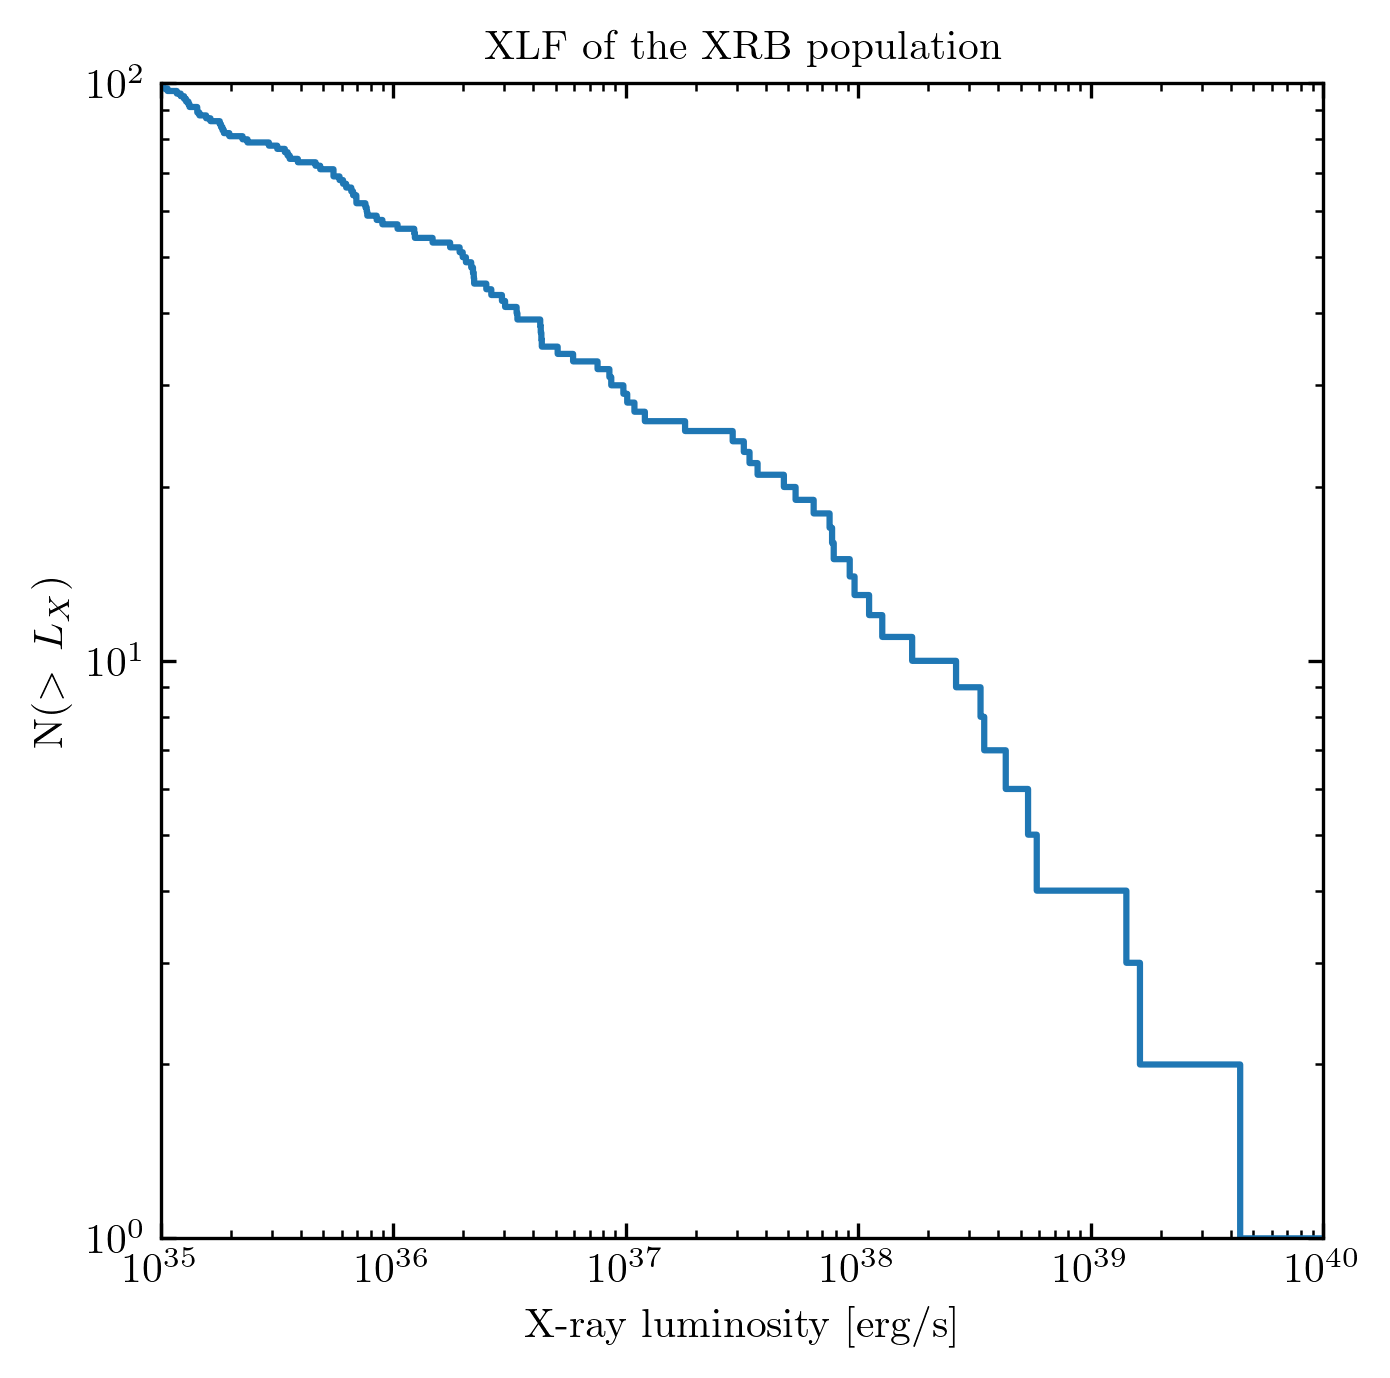

In [42]:
fig, axs = plt.subplots(figsize=(5,5))


axs.step(L1_sorted, N1)

axs.set_title('XLF of the XRB population')
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity [erg/s]')
axs.set_ylabel('N($>\, L_{X}$)')
axs.set_xlim(1e35, 1e40)
axs.set_ylim(1, 1e2)
plt.show()

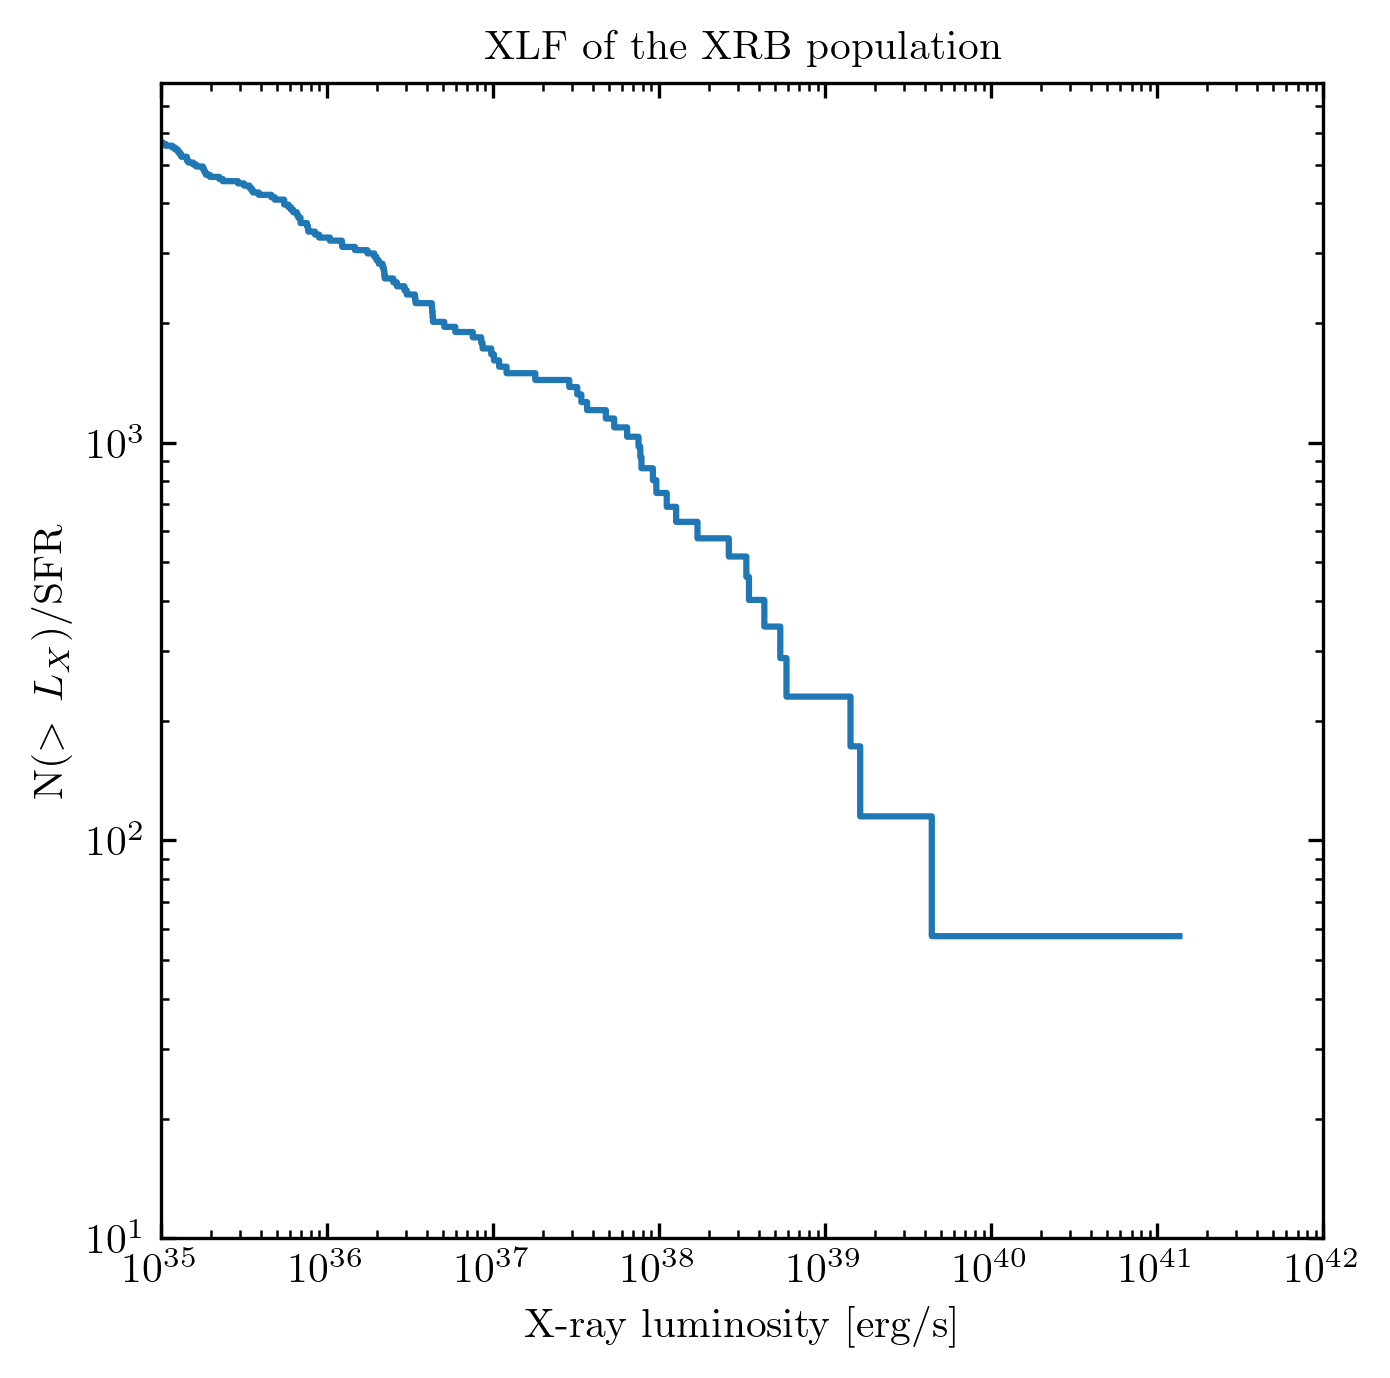

In [41]:
fig, axs = plt.subplots(figsize=(5,5))


axs.step(L1_sorted, N1_weighted)

axs.set_title('XLF of the XRB population')
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity [erg/s]')
axs.set_ylabel('N($>\, L_{X}$)/SFR')
axs.set_xlim(1e35, 1e42)
axs.set_ylim(10, 8e3)
plt.show()

La fonction plot_ccdf(vals, weight, label) trace la CCDF (complementary cumulative distribution function, N(>x)) d'un ensemble de valeurs.

Entrées :
vals : tableau de valeurs (ex. luminosités).
weight : poids associés à chaque valeur (peut être des 1 pour un comptage simple).
label : chaîne pour la légende.
Opérations :
tri croissant des valeurs : x = np.sort(vals)
réordonnancement des poids selon ce tri et somme cumulée inversée :  
```python 
y = np.cumsum(weight[np.argsort(vals)])[::-1]
``` 
(donne N(>x))
trace un diagramme en marches via plt.step(x, y, where='post', label=label).
Remarques : attend vals et weight de même longueur ; ne renvoie rien (affiche la courbe).

In [37]:
D1 = XRB_pop1.population['Donor_state'].value_counts()
display(D1)

Donor_state
H-rich_Core_H_burning               1317
H-rich_Core_He_burning                51
stripped_He_non_burning               40
stripped_He_Core_He_burning           31
H-rich_Shell_H_burning                20
H-rich_non_burning                    18
H-rich_Core_H_burning (Be star)       11
accreted_He_non_burning                3
stripped_He_Core_He_depleted           2
H-rich_Shell_H_burning (Be star)       2
Name: count, dtype: int64

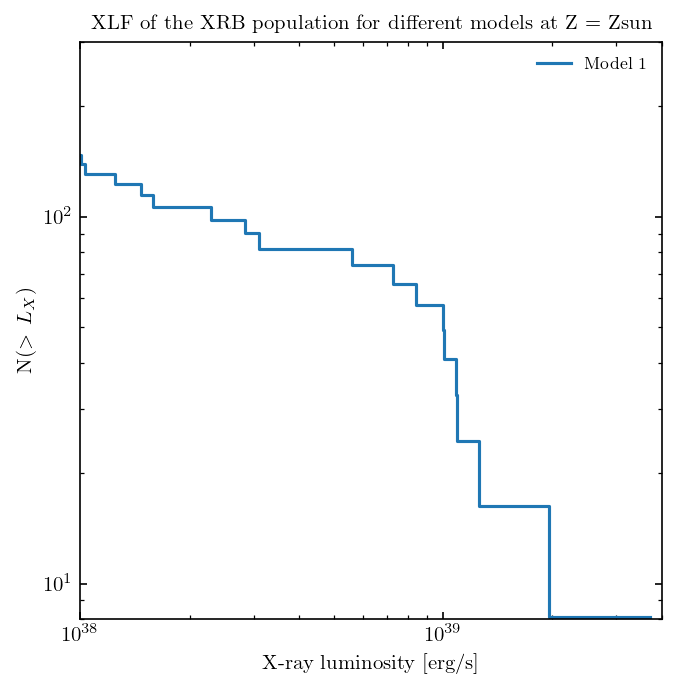

In [ ]:
fig, axs = plt.subplots(figsize=(5,5), dpi = 150)


axs.set_title("XLF of the XRB population for different models at Z = Zsun")
axs.step(L1_sorted, N1_weighted, label = 'Model 1')

axs.legend()
axs.set_xscale('log')
axs.set_yscale('log')
axs.set_xlabel('X-ray luminosity [erg/s]')
axs.set_ylabel('N($>\, L_{X}$)')
axs.set_xlim(1e35, 1e40)
axs.set_ylim(8, 3e2)
plt.show()

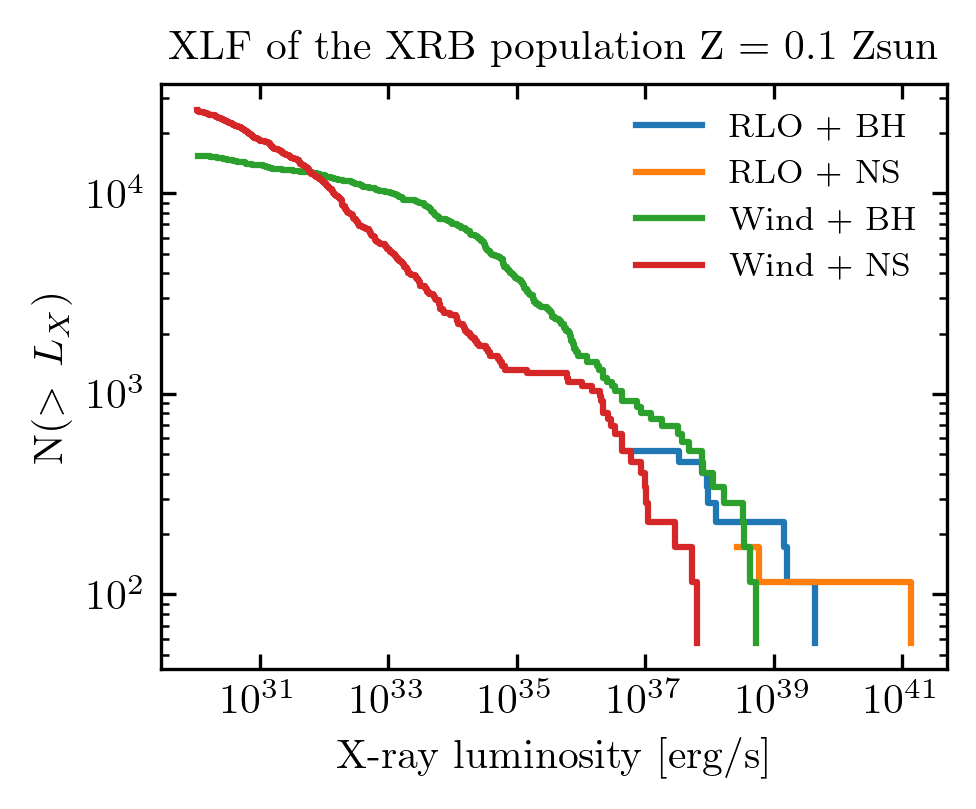

In [44]:
BH = XRB_pop1.population['Accretor_state'] == 'BH' # True/False pandas series
NS = XRB_pop1.population['Accretor_state'] == 'NS' # True/False pandas series
RLO = (XRB_pop1.population['Lx_RLO'] > XRB_pop1.population['Lx_BHL']) & (XRB_pop1.population['Lx_RLO'] > L_min) # True/False pandas series
Wind = (XRB_pop1.population['Lx_BHL'] > XRB_pop1.population['Lx_RLO']) & (XRB_pop1.population['Lx_BHL'] > L_min) # True/False pandas series

def plot_ccdf(vals, weight, label):
    x = np.sort(vals)                    # ascending
    y = np.cumsum(weight[np.argsort(vals)])[::-1]   # N(>x)
    plt.step(x, y, where='post', label=label)
plt.figure()
plot_ccdf(XRB_pop1.population.loc[RLO  & BH, 'Lx_Total'].to_numpy(), weights1[RLO  & BH].to_numpy() * Total_underlying_mass, 'RLO + BH')
plot_ccdf(XRB_pop1.population.loc[RLO  & NS, 'Lx_Total'].to_numpy(), weights1[RLO  & NS].to_numpy() * Total_underlying_mass, 'RLO + NS')
plot_ccdf(XRB_pop1.population.loc[Wind & BH, 'Lx_Total'].to_numpy(), weights1[Wind & BH].to_numpy() * Total_underlying_mass, 'Wind + BH')
plot_ccdf(XRB_pop1.population.loc[Wind & NS, 'Lx_Total'].to_numpy(), weights1[Wind & NS].to_numpy() * Total_underlying_mass, 'Wind + NS')

plt.title('XLF of the XRB population Z = 0.1 Zsun')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('X-ray luminosity [erg/s]')
plt.ylabel('N($>\, L_{X}$)')
plt.legend()
plt.show()

### 3. Default pop Misra

#### 3.1 Loading Data

In [41]:
Pop1_Misra0 = Population('Default_Pop/1e+00_Zsun_population.h5')

- Formation channels calculations (ONLY DO IT ONCE !!)

In [8]:
# ONLY do it once !!!
#Pop1_Misra0.calculate_formation_channels(mt_history=True)
#Pop2_Misra0.calculate_formation_channels(mt_history=True)

- Transient populations

In [17]:
oneline_cols = ['S1_state_f','S2_state_f','S1_mass_f','S2_mass_f',
        'S1_log_R_f','S2_log_R_f','S1_lg_mdot_f','S2_lg_mdot_f','S1_log_L_f','S2_log_L_f',
        'S1_surf_avg_omega_div_omega_crit_f','S2_surf_avg_omega_div_omega_crit_f',
        'S1_spin_f','S2_spin_f','S1_surface_h1_f','S2_surface_h1_f','S1_he_core_mass_f','S2_he_core_mass_f',
        'time_f','time_i','metallicity','orbital_period_f','eccentricity_f','lg_mtransfer_rate_f','state_f']

history_cols = ['time', 'metallicity', 'orbital_period', 'eccentricity', 'lg_mtransfer_rate', 'state', 'S1_state', 
                'S2_state', 'S1_mass', 'S2_mass', 'S1_log_R', 'S2_log_R', 'S1_lg_mdot', 'S2_lg_mdot', 'S1_log_L', 
                'S2_log_L', 'S1_surf_avg_omega_div_omega_crit', 'S2_surf_avg_omega_div_omega_crit', 'S1_spin', 
                'S2_spin', 'S1_surface_h1', 'S2_surface_h1', 'S1_he_core_mass', 'S2_he_core_mass']

In [4]:
import Functions_Misra_like as Func_Misra

In [6]:
Pop_code_Misra_like = Pop1_Misra0.create_transient_population(Func_Misra.XRB_selection_function1, 'XRBs_pop1_Misra')

overwriting transient population


In [15]:
display(Pop_code_Misra_like.population)

,state_sys,Orbital_period,Log_Mtransfer_rate,time,metallicity,Accretor_state,Accretor_mass,Accretor_Radius,Accretor_spin,Accretor_logMdot,Donor_mass,Donor_Radius,Donor_state,Donor_surf_H1,Donor_surf_velo,Donor_RL,Mechanism_Xray,Beaming,Lx_Total
5,detached,7154.689021,NaN,9.697185e+07,1.0,NS,1.301408,0.000018,0.000000,-99.0,4.547213,3.788236,H-rich_Core_H_burning,0.715500,0.589104,9.589091e+13,Wind,1.0,8.712707e-54
26,detached,8.506934,NaN,5.182025e+07,1.0,NS,1.150693,0.000018,0.000000,-99.0,2.354302,1.710388,H-rich_Core_H_burning,0.715500,0.306180,8.193037e+11,Wind,1.0,7.703697e-54
71,initial_RLOF,47.548286,NaN,6.428335e+06,1.0,BH,9.583213,0.000041,0.046109,NaN,33.674718,45.351205,H-rich_Core_H_burning,0.611136,0.160714,6.610789e+12,RLO,1.0,0.000000e+00
138,detached,648.647554,NaN,3.860134e+07,1.0,NS,1.310682,0.000018,0.000000,-99.0,7.189513,5.344517,H-rich_Core_H_burning,0.715500,0.604134,2.367348e+13,Wind,1.0,8.774799e-54
455,initial_RLOF,20.404030,NaN,9.880967e+06,1.0,NS,1.285474,0.000018,0.000000,NaN,18.499011,16.499988,H-rich_Core_H_burning,0.715500,0.246316,3.584105e+12,RLO,1.0,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9999412,initial_RLOF,3.374156,NaN,9.855676e+06,1.0,NS,1.290097,0.000018,0.000000,NaN,16.280871,7.577414,H-rich_Core_H_burning,0.715500,0.104194,1.021031e+12,RLO,1.0,0.000000e+00
9999420,initial_RLOF,13.166552,NaN,4.184929e+06,1.0,BH,14.266780,0.000061,0.121627,NaN,33.734290,45.974539,H-rich_Core_H_burning,0.613733,0.395837,2.699264e+12,RLO,1.0,0.000000e+00
9999820,detached,931.633069,NaN,6.303752e+07,1.0,NS,1.277210,0.000018,0.000000,-99.0,4.829054,3.223453,H-rich_Core_H_burning,0.715500,0.585341,2.534521e+13,Wind,1.0,8.550711e-54
9999983,initial_RLOF,7.159431,NaN,1.169993e+07,1.0,NS,1.382722,0.000018,0.000000,NaN,12.038985,5.441200,H-rich_Core_H_burning,0.715500,0.271318,1.465875e+12,RLO,1.0,0.000000e+00


In [18]:
# Kudritzski+2000
Pop_my_code = Pop1_Misra0.create_transient_population(lambda h, o, f: xrb.XRB_selection_function(h, o, f, Wind_Disk_BH_formation=True, Wind_velo_scheme='Kudritzki+2000', Wind_fed_scheme = None), 'XRBs_pop1_Misra', oneline_cols = oneline_cols, hist_cols = history_cols)
# Hurley+2002
#XRBs_pop2_Misra0 = Pop1_Misra0.create_transient_population(lambda h, o, f: xrb.XRB_selection_function(h, o, f, Wind_Disk_BH_formation=True, Wind_velo_scheme='Hurley+2002', Wind_fed_scheme = None), 'XRBs_pop2_Misra')

overwriting transient population


In [21]:
Pop_my_code.population['final_state']

5              detached
26             detached
71         initial_RLOF
138            detached
455        initial_RLOF
               ...     
9999412    initial_RLOF
9999420    initial_RLOF
9999820        detached
9999983    initial_RLOF
9999998        detached
Name: final_state, Length: 142586, dtype: object

In [ ]:
print("Displaying the " + color.BOLD + color.WHITE + "1st default population " + color.END + "(v2.2.2) with the default parameters from Misra et al. (2023) :")

display(Pop_my_code.population)

print("\nDisplaying the " + color.BOLD + color.WHITE + "2nd default population " + color.END + "(v2.2.2) with the default parameters from Misra et al. (2023) :")
#display(XRBs_pop2_Misra0.population)

Displaying the 1st default population (v2.2.2) with the default parameters from Misra et al. (2023) :


,time,time_of_birth,metallicity,state_final,Accretor_state,Accretor_mass,Accretor_logR,Accretor_logMdot,Accretor_spin,Donor_state,...,Donor_H1_surface_content,Donor_He_core_mass,Orbital_period,Eccentricity,Log_Mtransfer_rate,Mdot_BHL_gps,Mdot_RLO_gps,Beaming,Edd_State,Lx_Total
5,100.000000,3.028150,1.0,detached,NS,1.301408,-4.745687,-99.0,0.000000,H-rich_Core_H_burning,...,0.715500,0.000000,7154.689021,0.664873,NaN,2.177848e+07,0.0,1.0,Sub-Eddington,8.712707e-54
26,100.000000,48.179747,1.0,detached,NS,1.150693,-4.745687,-99.0,0.000000,H-rich_Core_H_burning,...,0.715500,0.000000,8.506934,0.317603,NaN,8.561753e+08,0.0,1.0,Sub-Eddington,7.703697e-54
71,72.767766,66.339432,1.0,initial_RLOF,BH,9.583213,-4.390614,NaN,0.046109,H-rich_Core_H_burning,...,0.611136,6.362662,47.548286,0.531172,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00
138,100.000000,61.398659,1.0,detached,NS,1.310682,-4.745687,-99.0,0.000000,H-rich_Core_H_burning,...,0.715500,0.000000,648.647554,0.935240,NaN,5.301138e+09,0.0,1.0,Sub-Eddington,8.774799e-54
455,54.547446,44.666479,1.0,initial_RLOF,NS,1.285474,-4.745687,NaN,0.000000,H-rich_Core_H_burning,...,0.715500,0.000000,20.404030,0.716198,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9999412,79.332500,69.476823,1.0,initial_RLOF,NS,1.290097,-4.745687,NaN,0.000000,H-rich_Core_H_burning,...,0.715500,0.000000,3.374156,0.680647,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00
9999420,12.052749,7.867819,1.0,initial_RLOF,BH,14.266780,-4.217799,NaN,0.121627,H-rich_Core_H_burning,...,0.613733,1.378004,13.166552,0.178904,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00
9999820,100.000000,36.962482,1.0,detached,NS,1.277210,-4.745687,-99.0,0.000000,H-rich_Core_H_burning,...,0.715500,0.000000,931.633069,0.287173,NaN,1.510021e+08,0.0,1.0,Sub-Eddington,8.550711e-54
9999983,72.745008,61.045078,1.0,initial_RLOF,NS,1.382722,-4.745687,NaN,0.000000,H-rich_Core_H_burning,...,0.715500,0.000000,7.159431,0.872095,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00



Displaying the 2nd default population (v2.2.2) with the default parameters from Misra et al. (2023) :


,time,time_of_birth,metallicity,state_final,Accretor_state,Accretor_mass,Accretor_logR,Accretor_logMdot,Accretor_spin,Donor_state,...,Donor_H1_surface_content,Donor_He_core_mass,Orbital_period,Eccentricity,Log_Mtransfer_rate,Mdot_BHL_gps,Mdot_RLO_gps,Beaming,Edd_State,Lx_Total
31,30.109483,22.540212,1.0,initial_RLOF,BH,9.310061,-4.403173,NaN,0.000076,H-rich_Core_H_burning,...,0.715500,0.0,1.017325,0.142417,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00
65,100.000000,46.160082,1.0,detached,NS,1.257087,-4.745687,-99.0,0.000000,H-rich_Core_H_burning,...,0.715500,0.0,10.147715,0.416668,NaN,2.685714e+10,0.0,1.0,Sub-Eddington,8.415986e-54
128,100.000000,49.287382,1.0,detached,NS,1.262517,-4.745687,-99.0,0.000000,H-rich_Core_H_burning,...,0.715500,0.0,233.049384,0.335513,NaN,1.906398e+08,0.0,1.0,Sub-Eddington,8.452340e-54
142,100.000000,53.623323,1.0,detached,NS,1.351596,-4.745687,-99.0,0.000000,H-rich_Core_H_burning,...,0.715500,0.0,1.765254,0.223976,NaN,1.896652e+10,0.0,1.0,Sub-Eddington,9.048710e-54
195,100.000000,40.428062,1.0,detached,NS,1.286014,-4.745687,-99.0,0.000000,H-rich_Core_H_burning,...,0.715500,0.0,12.066106,0.250895,NaN,3.452680e+11,0.0,1.0,Sub-Eddington,8.609652e-54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999847,96.190231,86.537935,1.0,initial_RLOF,NS,1.311994,-4.745687,NaN,0.000000,H-rich_Core_H_burning,...,0.715500,0.0,14.907985,0.959082,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00
999872,31.780990,27.636658,1.0,initial_RLOF,BH,13.560798,-4.239840,NaN,0.139547,H-rich_Core_H_burning,...,0.715499,0.0,13.909595,0.055866,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00
999875,59.479330,55.392452,1.0,initial_RLOF,BH,11.134311,-4.325462,NaN,0.195220,H-rich_Core_H_burning,...,0.715500,0.0,10.033792,0.341598,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00
999922,38.358819,11.661481,1.0,initial_RLOF,NS,1.150693,-4.745687,NaN,0.000000,H-rich_Core_H_burning,...,0.715500,0.0,5.764737,0.974243,NaN,0.000000e+00,0.0,1.0,Sub-Eddington,0.000000e+00


#### 3.2 some statistics

- Initial parameters for simulations from `.ini`file

In [ ]:
Pop_params = {'Pop_params1': Pop_my_code.ini_params.copy(), 
              #'Pop_params2': XRBs_pop2_Misra0.ini_params.copy()
              }

for name, params in Pop_params.items():
    print(color.WHITE + color.BOLD + color.UNDERLINE + f"Initial population parameters for {('1st' if name == 'Pop_params1' else '2nd')} population :" + color.END)
    display(params)

Initial population parameters for 1st population :


{'metallicity': 1.0,
 'number_of_binaries': 10000000,
 'binary_fraction_scheme': 'const',
 'binary_fraction_const': 0.7,
 'star_formation': 'constant',
 'max_simulation_time': 100000000.0,
 'primary_mass_scheme': 'Kroupa2001',
 'primary_mass_min': 7.0,
 'primary_mass_max': 120.0,
 'secondary_mass_scheme': 'flat_mass_ratio',
 'secondary_mass_min': 0.5,
 'secondary_mass_max': 150.0,
 'orbital_scheme': 'period',
 'orbital_period_scheme': 'Sana+12_period_extended',
 'orbital_period_min': 0.75,
 'orbital_period_max': 6000.0,
 'orbital_separation_scheme': 'log_uniform',
 'orbital_separation_min': 5.0,
 'orbital_separation_max': 100000.0,
 'eccentricity_scheme': 'zero'}

Initial population parameters for 2nd population :


{'metallicity': 1.0,
 'number_of_binaries': 1000000,
 'binary_fraction_scheme': 'const',
 'binary_fraction_const': 0.7,
 'star_formation': 'constant',
 'max_simulation_time': 100000000.0,
 'primary_mass_scheme': 'Kroupa2001',
 'primary_mass_min': 7.0,
 'primary_mass_max': 120.0,
 'secondary_mass_scheme': 'flat_mass_ratio',
 'secondary_mass_min': 0.5,
 'secondary_mass_max': 150.0,
 'orbital_scheme': 'period',
 'orbital_period_scheme': 'Sana+12_period_extended',
 'orbital_period_min': 0.75,
 'orbital_period_max': 6000.0,
 'orbital_separation_scheme': 'log_uniform',
 'orbital_separation_min': 5.0,
 'orbital_separation_max': 100000.0,
 'eccentricity_scheme': 'zero'}

- Total simulated mass of a population (primary + secondary star) :

In [ ]:
Sim_mass = {'1st population': Pop_my_code.mass_per_metallicity['simulated_mass'][1],
            #'2nd population': XRBs_pop2_Misra0.mass_per_metallicity['simulated_mass'][1], 
            }
print(color.BOLD + "Simulated mass :" + color.END)
for label, Sim_mass in Sim_mass.items():
    print(f"\n {label}: {Sim_mass:,.3f} M\u2609".replace(",", "'"))


Simulated mass :

 1st population: 244'228'099.933 M☉

 2nd population: 24'417'513.866 M☉


- Data about the populations

In [ ]:
Populations = {'1st population': Pop_my_code,
               #'2nd population': XRBs_pop2_Misra0, 
               }

stat_kwargs = {'primary_mass_min': 0.01,
               'primary_mass_max': 200.0,
               'orbital_period_max': 1e5,
               'q_min': 0.0,
               'q_max': 1.0,}

for label, population in Populations.items():

    total_XRBs = population.population.shape[0]
    Donor_state_counts = population.population['Donor_state'].value_counts()
    BH_number = int((population.population['Accretor_state'] == 'BH').sum())
    NS_number = int((population.population['Accretor_state'] == 'NS').sum())
    Be_star_number = int((population.population['Donor_state'].str.contains('Be star')).sum())

    print(f"\n" + color.BOLD + color.UNDERLINE + f"Statistics for the {label} :" + color.END)
    print(f"\nThe total number of Be XRB systems in the {label} are : {Be_star_number:,}".replace(",", "'"))
    print(f'Number of neutron stars in the {label} : {NS_number:,} NS'.replace(",", "'") )
    print(f'Number of black holes in the {label} : {BH_number:,} BH'.replace(",", "'") )
    
    print(f"Donor states in the {label} population:")
    display(Donor_state_counts)

    print(f'\nHere are the weights of the {label} population : ')
    _, _, weights = xrb.Stat_XLF(population, Lmin=1e30, Tot_underlying_mass=1e8, stat_kwargs=stat_kwargs)
    ratio = weights * 1e8
    ratio = ratio.rename("IMF * Total underlying mass [M☉]")
    display(pd.concat([weights, ratio], axis=1))




Statistics for the 1st population :

The total number of Be XRB systems in the 1st population are : 1'262
Number of neutron stars in the 1st population : 98'228 NS
Number of black holes in the 1st population : 44'358 BH
Donor states in the 1st population population:


Donor_state
H-rich_Core_H_burning               130614
H-rich_Core_He_burning                4904
H-rich_Shell_H_burning                1931
H-rich_non_burning                    1690
H-rich_Core_H_burning (Be star)       1226
stripped_He_Core_He_burning           1139
stripped_He_Core_He_depleted           380
accreted_He_non_burning                317
stripped_He_non_burning                157
accreted_He_Core_H_burning              87
H-rich_Core_He_depleted                 48
accreted_He_Shell_H_burning             41
H-rich_Shell_H_burning (Be star)        36
accreted_He_Core_He_burning             16
Name: count, dtype: int64


Here are the weights of the 1st population population : 


,base_IMF,IMF * Total underlying mass [M☉]
5,3.734125e-09,0.373412
26,3.814582e-09,0.381458
71,4.395555e-09,0.439555
138,3.816712e-09,0.381671
455,4.395555e-09,0.439555
...,...,...
9999412,4.395555e-09,0.439555
9999420,4.395555e-09,0.439555
9999820,3.751130e-09,0.375113
9999983,4.395555e-09,0.439555



Statistics for the 2nd population :

The total number of Be XRB systems in the 2nd population are : 111
Number of neutron stars in the 2nd population : 10'827 NS
Number of black holes in the 2nd population : 4'549 BH
Donor states in the 2nd population population:


Donor_state
H-rich_Core_H_burning              13907
H-rich_Core_He_burning               533
stripped_He_Core_He_burning          277
H-rich_Shell_H_burning               175
H-rich_non_burning                   171
H-rich_Core_H_burning (Be star)      111
stripped_He_non_burning              103
stripped_He_Core_He_depleted          56
accreted_He_non_burning               27
H-rich_Core_He_depleted                8
accreted_He_Core_H_burning             5
accreted_He_Shell_H_burning            2
accreted_He_Core_He_burning            1
Name: count, dtype: int64


Here are the weights of the 2nd population population : 


,base_IMF,IMF * Total underlying mass [M☉]
31,4.396508e-08,4.396508
65,3.766076e-08,3.766076
128,3.759511e-08,3.759511
142,3.817540e-08,3.817540
195,3.773943e-08,3.773943
...,...,...
999847,4.396508e-08,4.396508
999872,4.396508e-08,4.396508
999875,4.396508e-08,4.396508
999922,3.817540e-08,3.817540


In [ ]:
# Diverse statistics on the population
DataFrame = {'1st population': Pop_my_code.population,
             #'2nd population': XRBs_pop2_Misra0.population,
             }

for label, df in DataFrame.items():
    mask_RLO = (df['Mdot_RLO_gps'] > df['Mdot_BHL_gps'])
    df_bhl = df.loc[~mask_RLO]

    counts_all = pd.crosstab(df['Donor_state'], df['Accretor_state'])
    counts_bhl = pd.crosstab(df_bhl['Donor_state'], df_bhl['Accretor_state'])

    for col in ('BH','NS'):
        if col not in counts_all.columns:
            counts_all[col] = 0
        if col not in counts_bhl.columns:
            counts_bhl[col] = 0

    counts_all = counts_all[['BH','NS']].rename(columns={'BH':'Total # BH','NS':'Total # NS'})
    counts_bhl = counts_bhl[['BH','NS']].rename(columns={'BH':'# BH Winds','NS':'# NS Winds'})

    DF = df['Donor_state'].value_counts().rename('Number of donors').to_frame()
    DF = DF.join([counts_all, counts_bhl], how='left').fillna(0).astype(int)

    DF['# Wind-fed systems'] = df_bhl['Donor_state'].value_counts().reindex(DF.index).fillna(0).astype(int)
    DF['# RLO-fed systems'] = DF['Number of donors'] - DF['# Wind-fed systems']

    print(f"\n" + color.BOLD + color.UNDERLINE + f"Statistics for the {label} :" + color.END)
    display(DF)


Statistics for the 1st population :


,Number of donors,Total # BH,Total # NS,# BH Winds,# NS Winds,# Wind-fed systems,# RLO-fed systems
Donor_state,,,,,,,
H-rich_Core_H_burning,130614,35173,95441,34589,95431,130020,594
H-rich_Core_He_burning,4904,4087,817,3994,817,4811,93
H-rich_Shell_H_burning,1931,1569,362,1516,357,1873,58
H-rich_non_burning,1690,1543,147,1543,147,1690,0
H-rich_Core_H_burning (Be star),1226,828,398,828,398,1226,0
stripped_He_Core_He_burning,1139,538,601,538,601,1139,0
stripped_He_Core_He_depleted,380,54,326,54,325,379,1
accreted_He_non_burning,317,302,15,302,15,317,0
stripped_He_non_burning,157,141,16,141,16,157,0



Statistics for the 2nd population :


,Number of donors,Total # BH,Total # NS,# BH Winds,# NS Winds,# Wind-fed systems,# RLO-fed systems
Donor_state,,,,,,,
H-rich_Core_H_burning,13907,3589,10318,3507,10316,13823,84
H-rich_Core_He_burning,533,447,86,435,86,521,12
stripped_He_Core_He_burning,277,77,200,77,180,257,20
H-rich_Shell_H_burning,175,147,28,143,28,171,4
H-rich_non_burning,171,153,18,153,18,171,0
H-rich_Core_H_burning (Be star),111,78,33,78,33,111,0
stripped_He_non_burning,103,15,88,15,88,103,0
stripped_He_Core_He_depleted,56,11,45,11,41,52,4
accreted_He_non_burning,27,25,2,25,2,27,0


#### 3.3 Plots

- Plot of reference (Misra et al. (2023)) : 

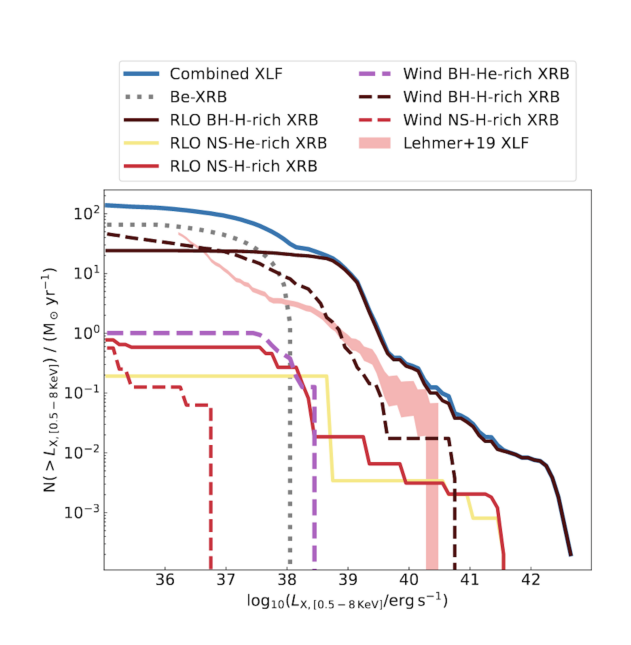

In [32]:
import matplotlib.image as mpimg

Plot_Misra = mpimg.imread("Default_Pop_Misra_with_Legends.png")

plt.imshow(Plot_Misra)
plt.axis('off')  # turn off axis numbers and ticks
plt.show()


- Calculating the weights through `Stat_XLF()` if not using `plot_XLF_models()`

In [7]:
stat_kwargs = {'primary_mass_min': 0.01,
               'primary_mass_max': 200.0,
               'secondary_mass_min': 0.01,
               'secondary_mass_max': 150.0,
               'orbital_period_max': 6e3,
               'q_min': 0.05,
               'q_max': 1.0,}

weights1, Inv_Norm_fact = xrb.Stat_XLF(Pop_code_Misra_like, Lmin=1e30, SFR = 1.0, stat_kwargs=stat_kwargs)
#_, _, weights2, Inv_Norm_fact2 = xrb.Stat_XLF(XRBs_pop2_Misra0, Lmin=1e30, SFR = 1.0, stat_kwargs=stat_kwargs)

- Kudritzki+2000

In [12]:
# If Compute_Lx_Misrastyle() was used to calculate luminosities
Pop_code_Misra_like.population.columns


Index(['state_sys', 'Orbital_period', 'Log_Mtransfer_rate', 'time',
       'metallicity', 'Accretor_state', 'Accretor_mass', 'Accretor_Radius',
       'Accretor_spin', 'Accretor_logMdot', 'Donor_mass', 'Donor_Radius',
       'Donor_state', 'Donor_surf_H1', 'Donor_surf_velo', 'Donor_RL',
       'Mechanism_Xray', 'Beaming', 'Lx_Total'],
      dtype='object')

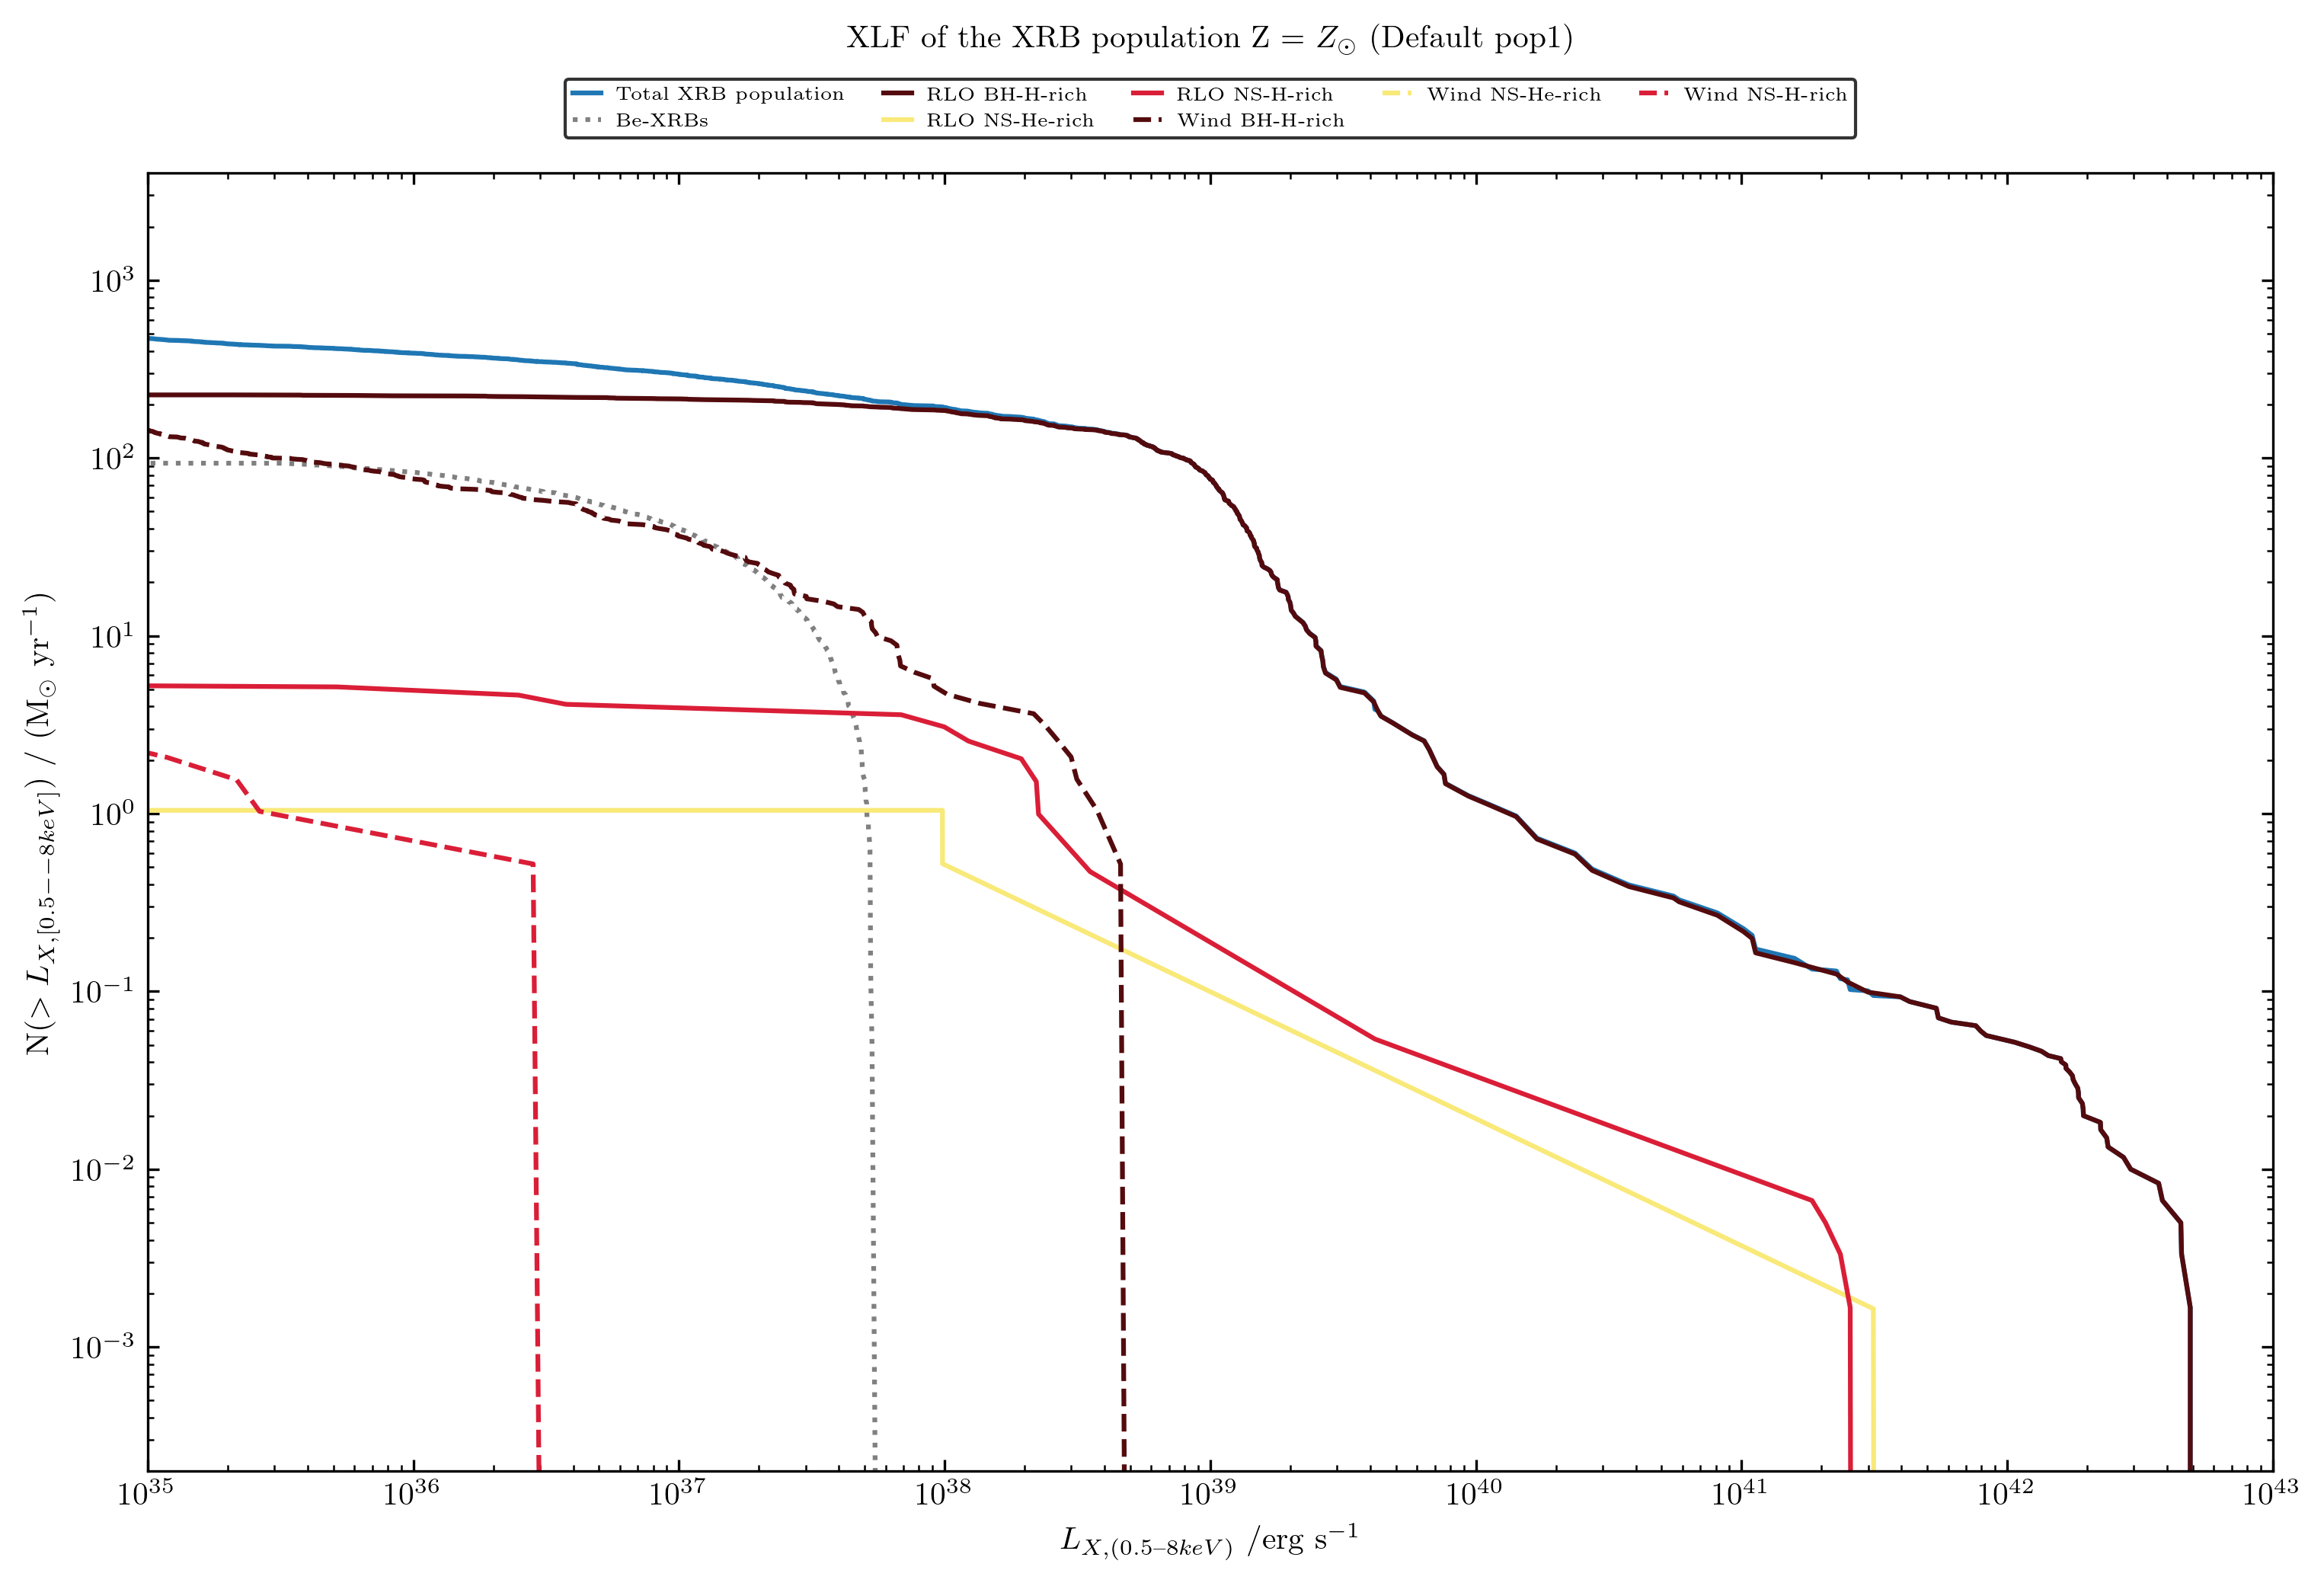

In [8]:
L_min = 1e30 # Minimal luminosity threshold for XRBs [erg/s]
L_max = 1e43
SFR = 1.0

# Boolean masks of length 14220
Accretor_state = Pop_code_Misra_like.population['Accretor_state']
Donor_state = Pop_code_Misra_like.population['Donor_state']
Binsys_state = Pop_code_Misra_like.population['state_sys']


BH1 = (Accretor_state == 'BH')
NS1 = (Accretor_state == 'NS')
H1_rich = Donor_state.str.contains('H-rich|accreted_He', regex=True, na=False)
stripped_He = Donor_state.str.contains('stripped_He', na=False)
Be_XRB = Donor_state.str.contains('Be star', na=False)

#===== Mask selection =====
Lumino_range = (Pop_code_Misra_like.population['Lx_Total'] < L_max) & (Pop_code_Misra_like.population['Lx_Total'] > L_min)
RLO = (Pop_code_Misra_like.population['Mechanism_Xray'] == 'RLO')
Wind = (Pop_code_Misra_like.population['Mechanism_Xray'] == 'Wind')

#===== Plotting =====
fig , ax = plt.subplots(figsize=(12,8), dpi=300)
xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, Lumino_range, 'Total XRB population', SFR = SFR, linestyle='-', color='#1F77B4')
xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, Be_XRB, 'Be-XRBs', SFR = SFR, linestyle=':', color='#808080')

xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, RLO & BH1 & stripped_He, 'RLO BH-He-rich', SFR = SFR, linestyle='-', color='#B760C4')
xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, RLO & BH1 & H1_rich, 'RLO BH-H-rich', SFR = SFR, linestyle='-', color='#540B0E')
xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, RLO & NS1 & stripped_He, 'RLO NS-He-rich', SFR = SFR, linestyle='-', color='#F9E979')
xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, RLO & NS1 & H1_rich, 'RLO NS-H-rich', SFR = SFR, linestyle='-', color='#DA1E37')

xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, Wind & BH1 & stripped_He, 'Wind BH-He-rich', SFR = SFR, linestyle='--', color='#B760C4')
xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, Wind & BH1 & H1_rich, 'Wind BH-H-rich', SFR = SFR, linestyle='--', color='#540B0E')
xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, Wind & NS1 & stripped_He, 'Wind NS-He-rich', SFR = SFR, linestyle='--', color='#F9E979')
xrb.plot_ccdf(Pop_code_Misra_like, ax, weights1, Wind & NS1 & H1_rich , 'Wind NS-H-rich', SFR = SFR, linestyle='--', color='#DA1E37')


ax.set_title(r'XLF of the XRB population Z = $Z_{\odot}$ (Default pop1)', pad = 40)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$L_{X,(0.5–8 keV)}$ /erg s$^{-1}$')
ax.set_ylabel(r'N($> L_{X,[0.5--8 keV]}$) / (M$_\odot$ yr$^{-1}$)')
ax.set_xlim(1e35, 1e43)
ax.set_ylim(2e-4, 4e3)
legend = ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), bbox_transform=ax.transAxes, 
                   ncol=5, frameon=True, fancybox=True, edgecolor='k', handlelength=1.5, borderpad=0.4, fontsize=6)
fig.subplots_adjust(top=0.82)  # ajuster l'espace supérieur pour la légende

plt.show()

In [20]:
Pop_my_code.population['Donor_state'].value_counts()

Donor_state
H-rich_Core_H_burning              130614
H-rich_Core_He_burning               4904
H-rich_Shell_H_burning               1967
H-rich_non_burning                   1690
H-rich_Core_H_burning (Be star)      1226
stripped_He_Core_He_burning          1139
stripped_He_Core_He_depleted          380
accreted_He_non_burning               317
stripped_He_non_burning               157
accreted_He_Core_H_burning             87
H-rich_Core_He_depleted                48
accreted_He_Shell_H_burning            41
accreted_He_Core_He_burning            16
Name: count, dtype: int64

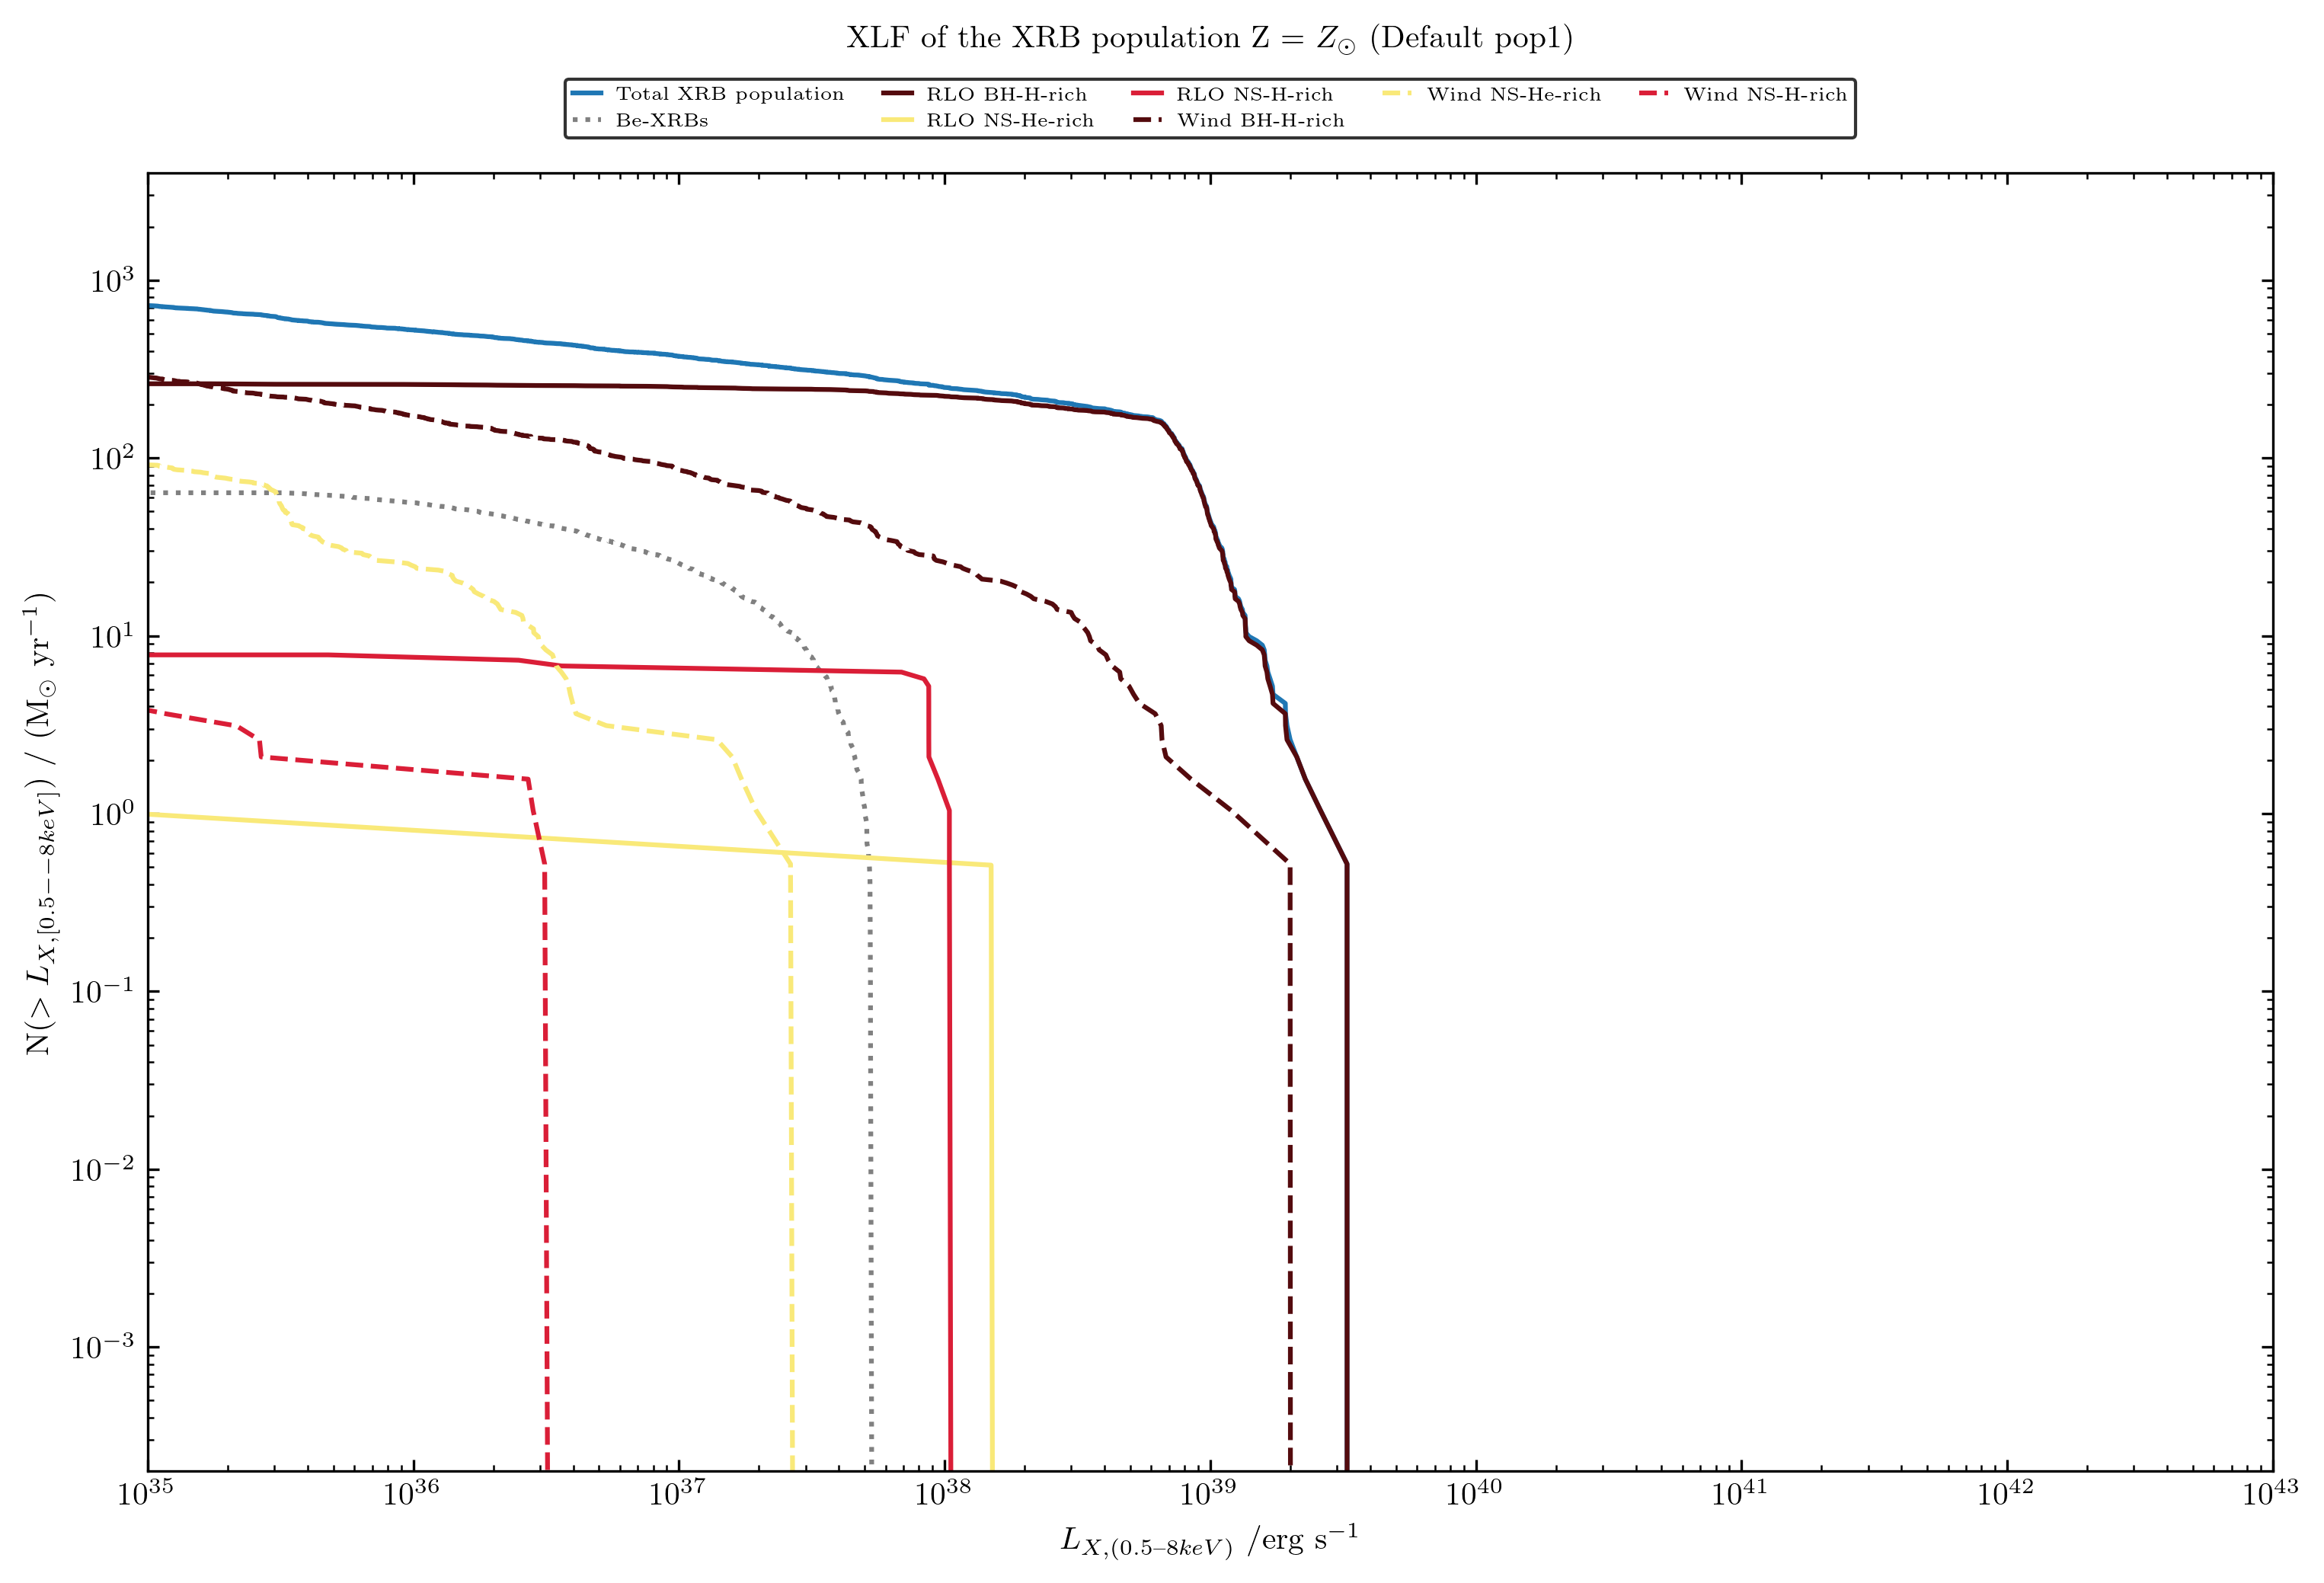

In [21]:
L_min = 1e30 # Minimal luminosity threshold for XRBs [erg/s]
L_max = 1e43
SFR = 1.0

# Boolean masks of length 14220
Accretor_state = Pop_my_code.population['Accretor_state']
Donor_state = Pop_my_code.population['Donor_state']

#? If Compute_Lx_Misrastyle() was used to calculate luminosities
#Binsys_state_f = Pop_my_code.population['state_final']
#? ======================

Mdot_RLO = Pop_my_code.population['Mdot_RLO_gps']
Mdot_BHL = Pop_my_code.population['Mdot_BHL_gps']

#Hydrogen_star_list = ['H-rich_Core_H_burning', 'H-rich_Shell_H_burning', 'H-rich_non_burning', 'H-rich_Core_He_depleted', 'accreted_He_Core_H_burning', 'accreted_He_Shell_H_burning']
#Helium_star_list = ['H-rich_Core_He_burning','stripped_He_Core_He_burning', 'stripped_He_Core_He_depleted', 'accreted_He_non_burning', 'stripped_He_non_burning', 'accreted_He_Core_He_burning']

BH1 = (Accretor_state == 'BH')
NS1 = (Accretor_state == 'NS')
#H1_rich = Donor_state.isin(Hydrogen_star_list)
#stripped_He = Donor_state.isin(Helium_star_list)

H1_rich = (Donor_state.str.contains('H-rich|accreted_He', regex=True, na=False) & ~Donor_state.str.contains('Be star', na=False))
stripped_He = Donor_state.str.contains('stripped_He', na=False)
Be_XRB = Donor_state.str.contains('Be star', na=False)

#===== Mask selection =====
Lumino_range = (Pop_my_code.population['Lx_Total'] < L_max) & (Pop_my_code.population['Lx_Total'] > L_min)
RLO = (Mdot_RLO > Mdot_BHL)  # True/False pandas series
Wind = (Mdot_BHL > Mdot_RLO) # True/False pandas series

#? If Compute_Lx_Misrastyle() was used to calculate luminosities
#RLO = (Binsys_state_f == 'initial_RLOF') | (Binsys_state_f == 'RLO2') # True/False pandas series
#Wind = (Binsys_state_f == 'detached')# True/False pandas series
#? ======================

#===== Plotting =====
fig , ax = plt.subplots(figsize=(12,8), dpi=300)
xrb.plot_ccdf(Pop_my_code, ax, weights1, Lumino_range, 'Total XRB population', SFR = SFR, linestyle='-', color='#1F77B4')
xrb.plot_ccdf(Pop_my_code, ax, weights1, Be_XRB, 'Be-XRBs', SFR = SFR, linestyle=':', color='#808080')

xrb.plot_ccdf(Pop_my_code, ax, weights1, RLO & BH1 & stripped_He, 'RLO BH-He-rich', SFR = SFR, linestyle='-', color='#B760C4')
xrb.plot_ccdf(Pop_my_code, ax, weights1, RLO & BH1 & H1_rich, 'RLO BH-H-rich', SFR = SFR, linestyle='-', color='#540B0E')
xrb.plot_ccdf(Pop_my_code, ax, weights1, RLO & NS1 & stripped_He, 'RLO NS-He-rich', SFR = SFR, linestyle='-', color='#F9E979')
xrb.plot_ccdf(Pop_my_code, ax, weights1, RLO & NS1 & H1_rich, 'RLO NS-H-rich', SFR = SFR, linestyle='-', color='#DA1E37')

xrb.plot_ccdf(Pop_my_code, ax, weights1, Wind & BH1 & stripped_He, 'Wind BH-He-rich', SFR = SFR, linestyle='--', color='#B760C4')
xrb.plot_ccdf(Pop_my_code, ax, weights1, Wind & BH1 & H1_rich, 'Wind BH-H-rich', SFR = SFR, linestyle='--', color='#540B0E')
xrb.plot_ccdf(Pop_my_code, ax, weights1, Wind & NS1 & stripped_He, 'Wind NS-He-rich', SFR = SFR, linestyle='--', color='#F9E979')
xrb.plot_ccdf(Pop_my_code, ax, weights1, Wind & NS1 & H1_rich , 'Wind NS-H-rich', SFR = SFR, linestyle='--', color='#DA1E37')


ax.set_title(r'XLF of the XRB population Z = $Z_{\odot}$ (Default pop1)', pad = 40)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$L_{X,(0.5–8 keV)}$ /erg s$^{-1}$')
ax.set_ylabel(r'N($> L_{X,[0.5--8 keV]}$) / (M$_\odot$ yr$^{-1}$)')
ax.set_xlim(1e35, 1e43)
ax.set_ylim(2e-4, 4e3)
legend = ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), bbox_transform=ax.transAxes, 
                   ncol=5, frameon=True, fancybox=True, edgecolor='k', handlelength=1.5, borderpad=0.4, fontsize=6)
fig.subplots_adjust(top=0.82)  # ajuster l'espace supérieur pour la légende

plt.show()

- Hurley+2002

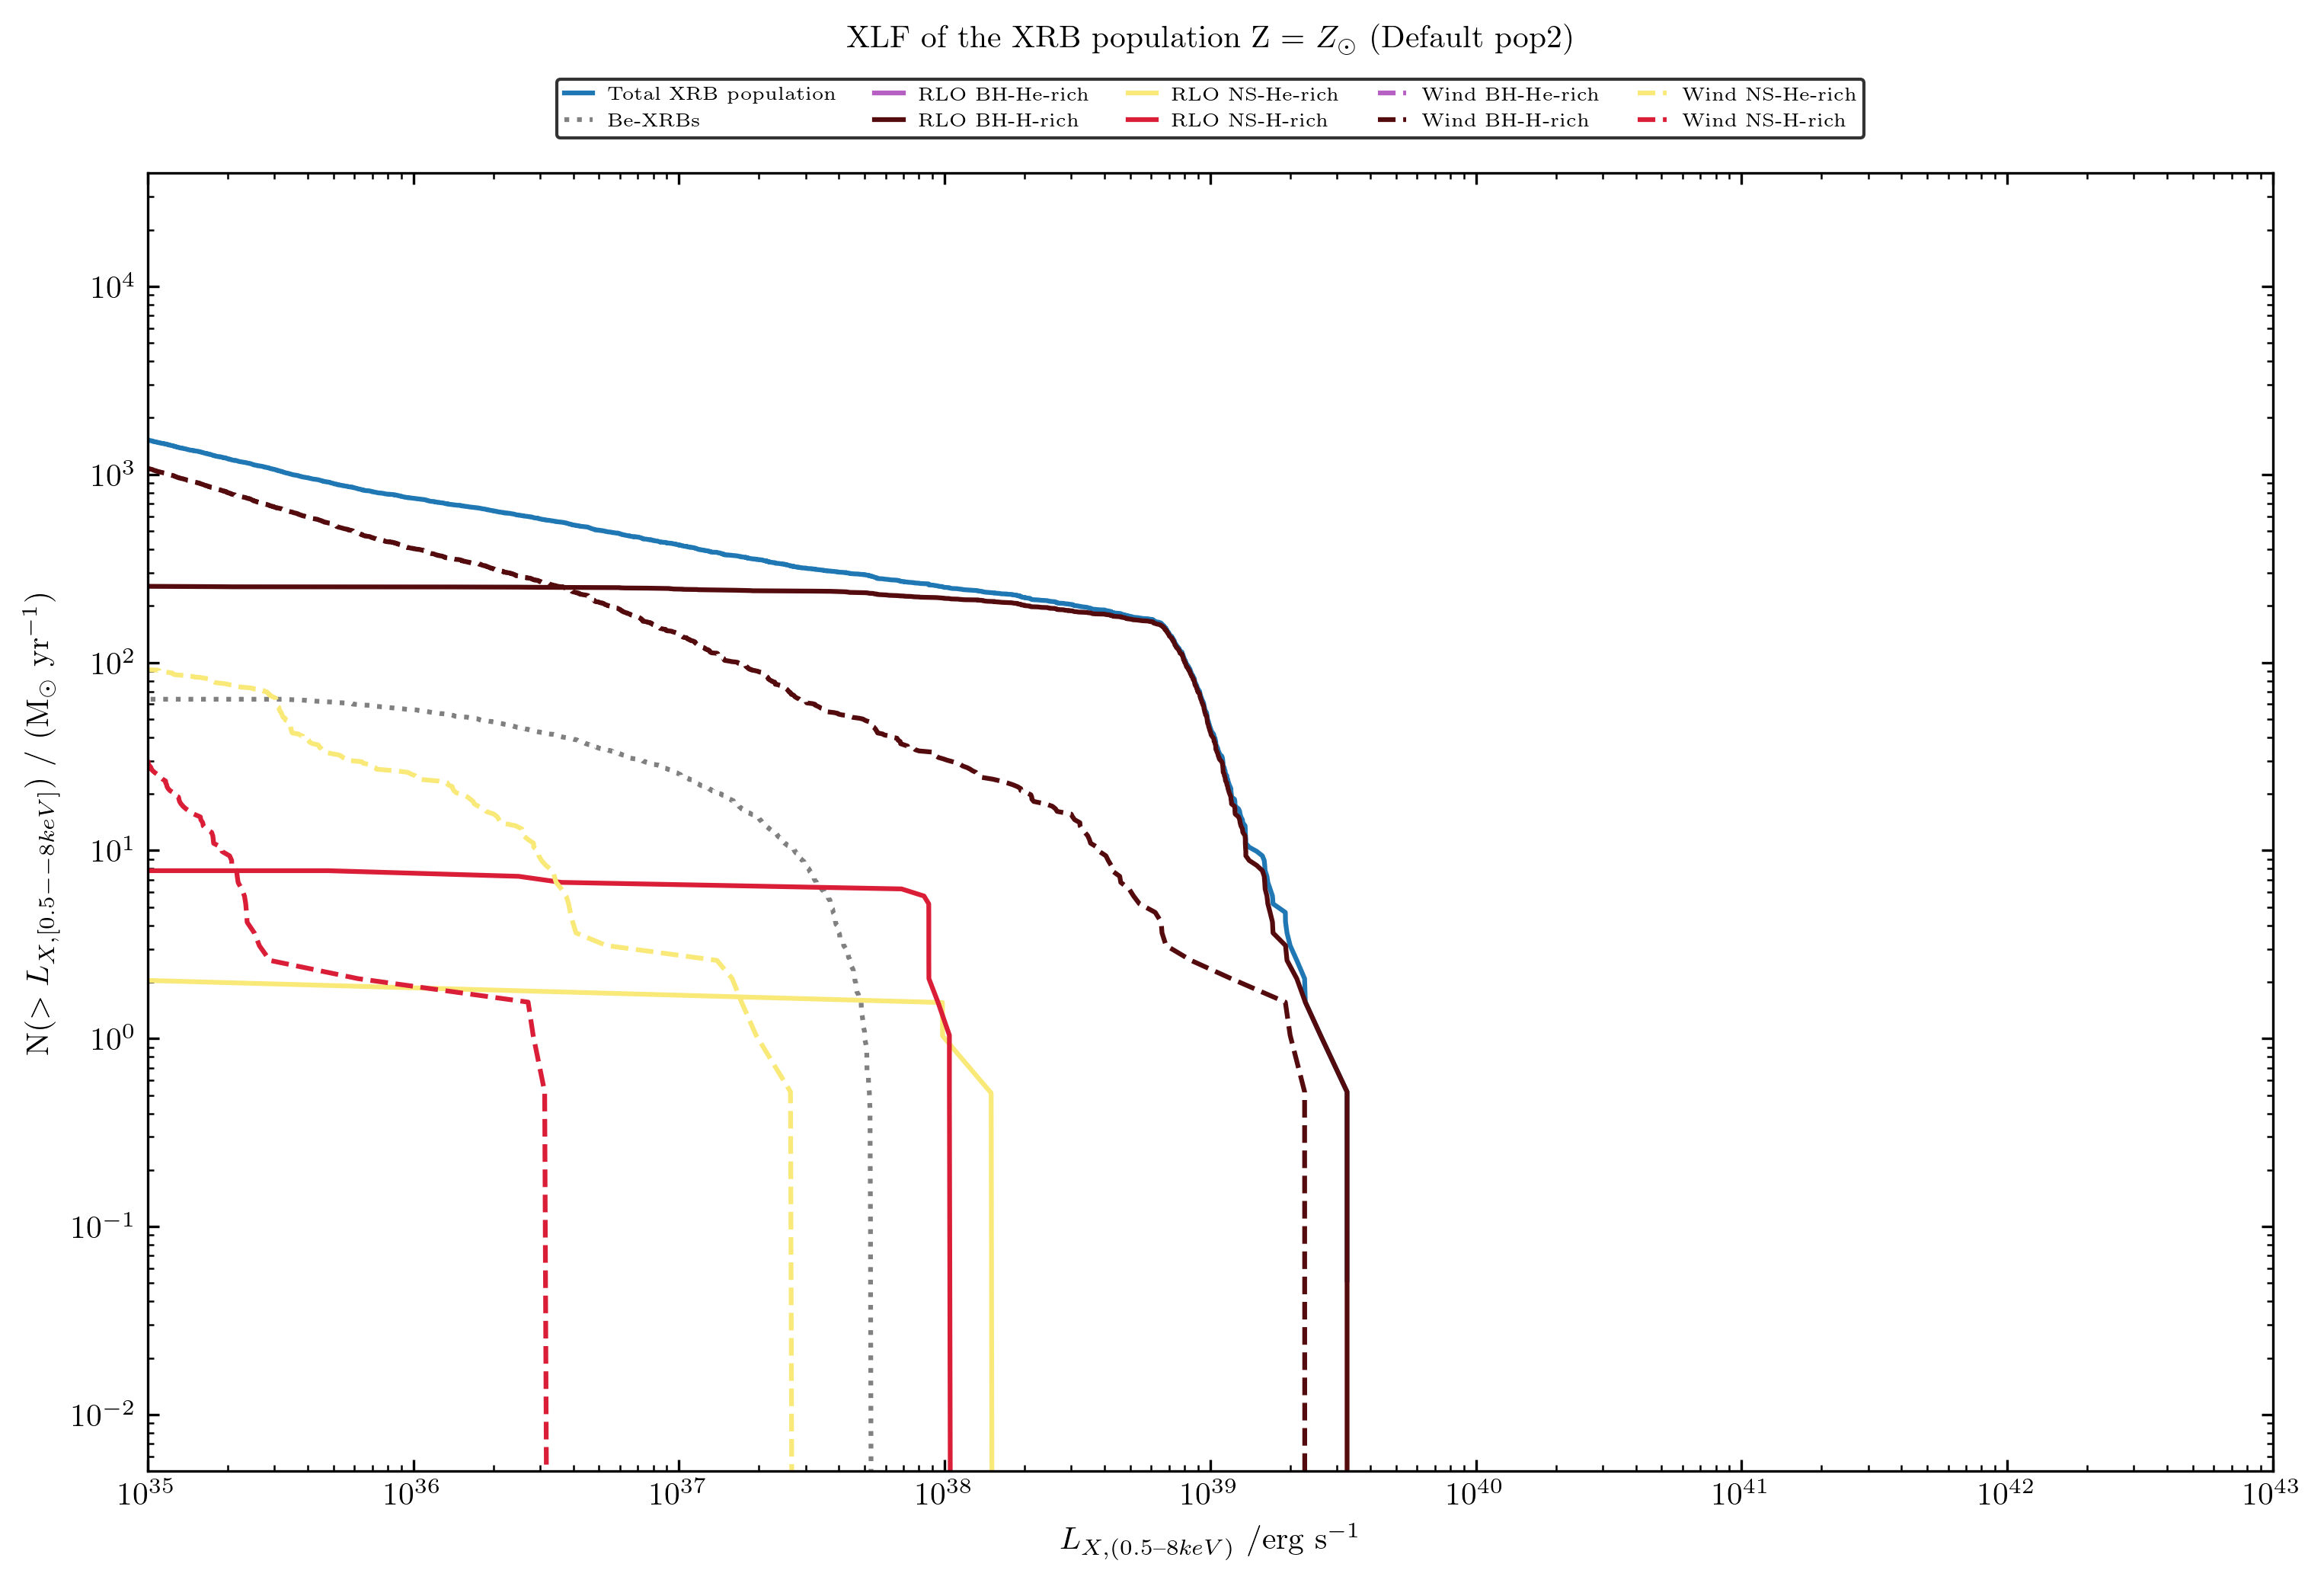

In [17]:
L_min = 1e30 # Minimal luminosity threshold for XRBs [erg/s]
L_max = 1e43

# Boolean masks
Donor_state = XRBs_pop2_Misra0.population['Donor_state']
Accretor_state = XRBs_pop2_Misra0.population['Accretor_state']
Mdot_RLO = XRBs_pop2_Misra0.population['Mdot_RLO_gps']
Mdot_BHL = XRBs_pop2_Misra0.population['Mdot_BHL_gps']

BH1 = (Accretor_state == 'BH')
NS1 = (Accretor_state == 'NS')
H1_rich = (Donor_state.str.contains('H-rich|accreted_He', regex=True, na=False) & ~Donor_state.str.contains('Be star', na=False))
stripped_He = Donor_state.str.contains('stripped_He', na=False)
Be_XRB = Donor_state.str.contains('Be star', na=False)

#===== Mask selection =====
Lumino_range = (XRBs_pop2_Misra0.population['Lx_Total'] < L_max) & (XRBs_pop2_Misra0.population['Lx_Total'] > L_min)
RLO = (Mdot_RLO >= Mdot_BHL) & (Lumino_range) # True/False pandas series
Wind = (Mdot_BHL > Mdot_RLO) & (Lumino_range)# True/False pandas series

#===== Plotting =====
fig , ax = plt.subplots(figsize=(12,8), dpi=300)
xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, Lumino_range, 'Total XRB population', SFR = SFR, linestyle='-', color='#1F77B4')
xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, Be_XRB, 'Be-XRBs', SFR = SFR, linestyle=':', color='#808080')

xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, RLO & BH1 & stripped_He, 'RLO BH-He-rich', SFR = SFR, linestyle='-', color='#B760C4')
xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, RLO & BH1 & H1_rich, 'RLO BH-H-rich', SFR = SFR, linestyle='-', color='#540B0E')
xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, RLO & NS1 & stripped_He, 'RLO NS-He-rich', SFR = SFR, linestyle='-', color='#F9E979')
xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, RLO & NS1 & H1_rich, 'RLO NS-H-rich', SFR = SFR, linestyle='-', color='#DA1E37')

xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, Wind & BH1 & stripped_He, 'Wind BH-He-rich', SFR = SFR, linestyle='--', color='#B760C4')
xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, Wind & BH1 & H1_rich, 'Wind BH-H-rich', SFR = SFR, linestyle='--', color='#540B0E')
xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, Wind & NS1 & stripped_He, 'Wind NS-He-rich', SFR = SFR, linestyle='--', color='#F9E979')
xrb.plot_ccdf(XRBs_pop2_Misra0, ax, weights2, Wind & NS1 & H1_rich , 'Wind NS-H-rich', SFR = SFR, linestyle='--', color='#DA1E37')


ax.set_title(r'XLF of the XRB population Z = $Z_{\odot}$ (Default pop2)', pad = 40)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$L_{X,(0.5–8 keV)}$ /erg s$^{-1}$')
ax.set_ylabel(r'N($> L_{X,[0.5--8 keV]}$) / (M$_\odot$ yr$^{-1}$)')
ax.set_xlim(1e35, 1e43)
ax.set_ylim(5e-3, 4e4)
legend = ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), bbox_transform=ax.transAxes, 
                   ncol=5, frameon=True, fancybox=True, edgecolor='k', handlelength=1.5, borderpad=0.4, fontsize=6)
fig.subplots_adjust(top=0.82)  # ajuster l'espace supérieur pour la légende

plt.show()

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/synthetic_population.py:1965: OverwriteWarning: 'Model weights already exist! Overwriting them!'


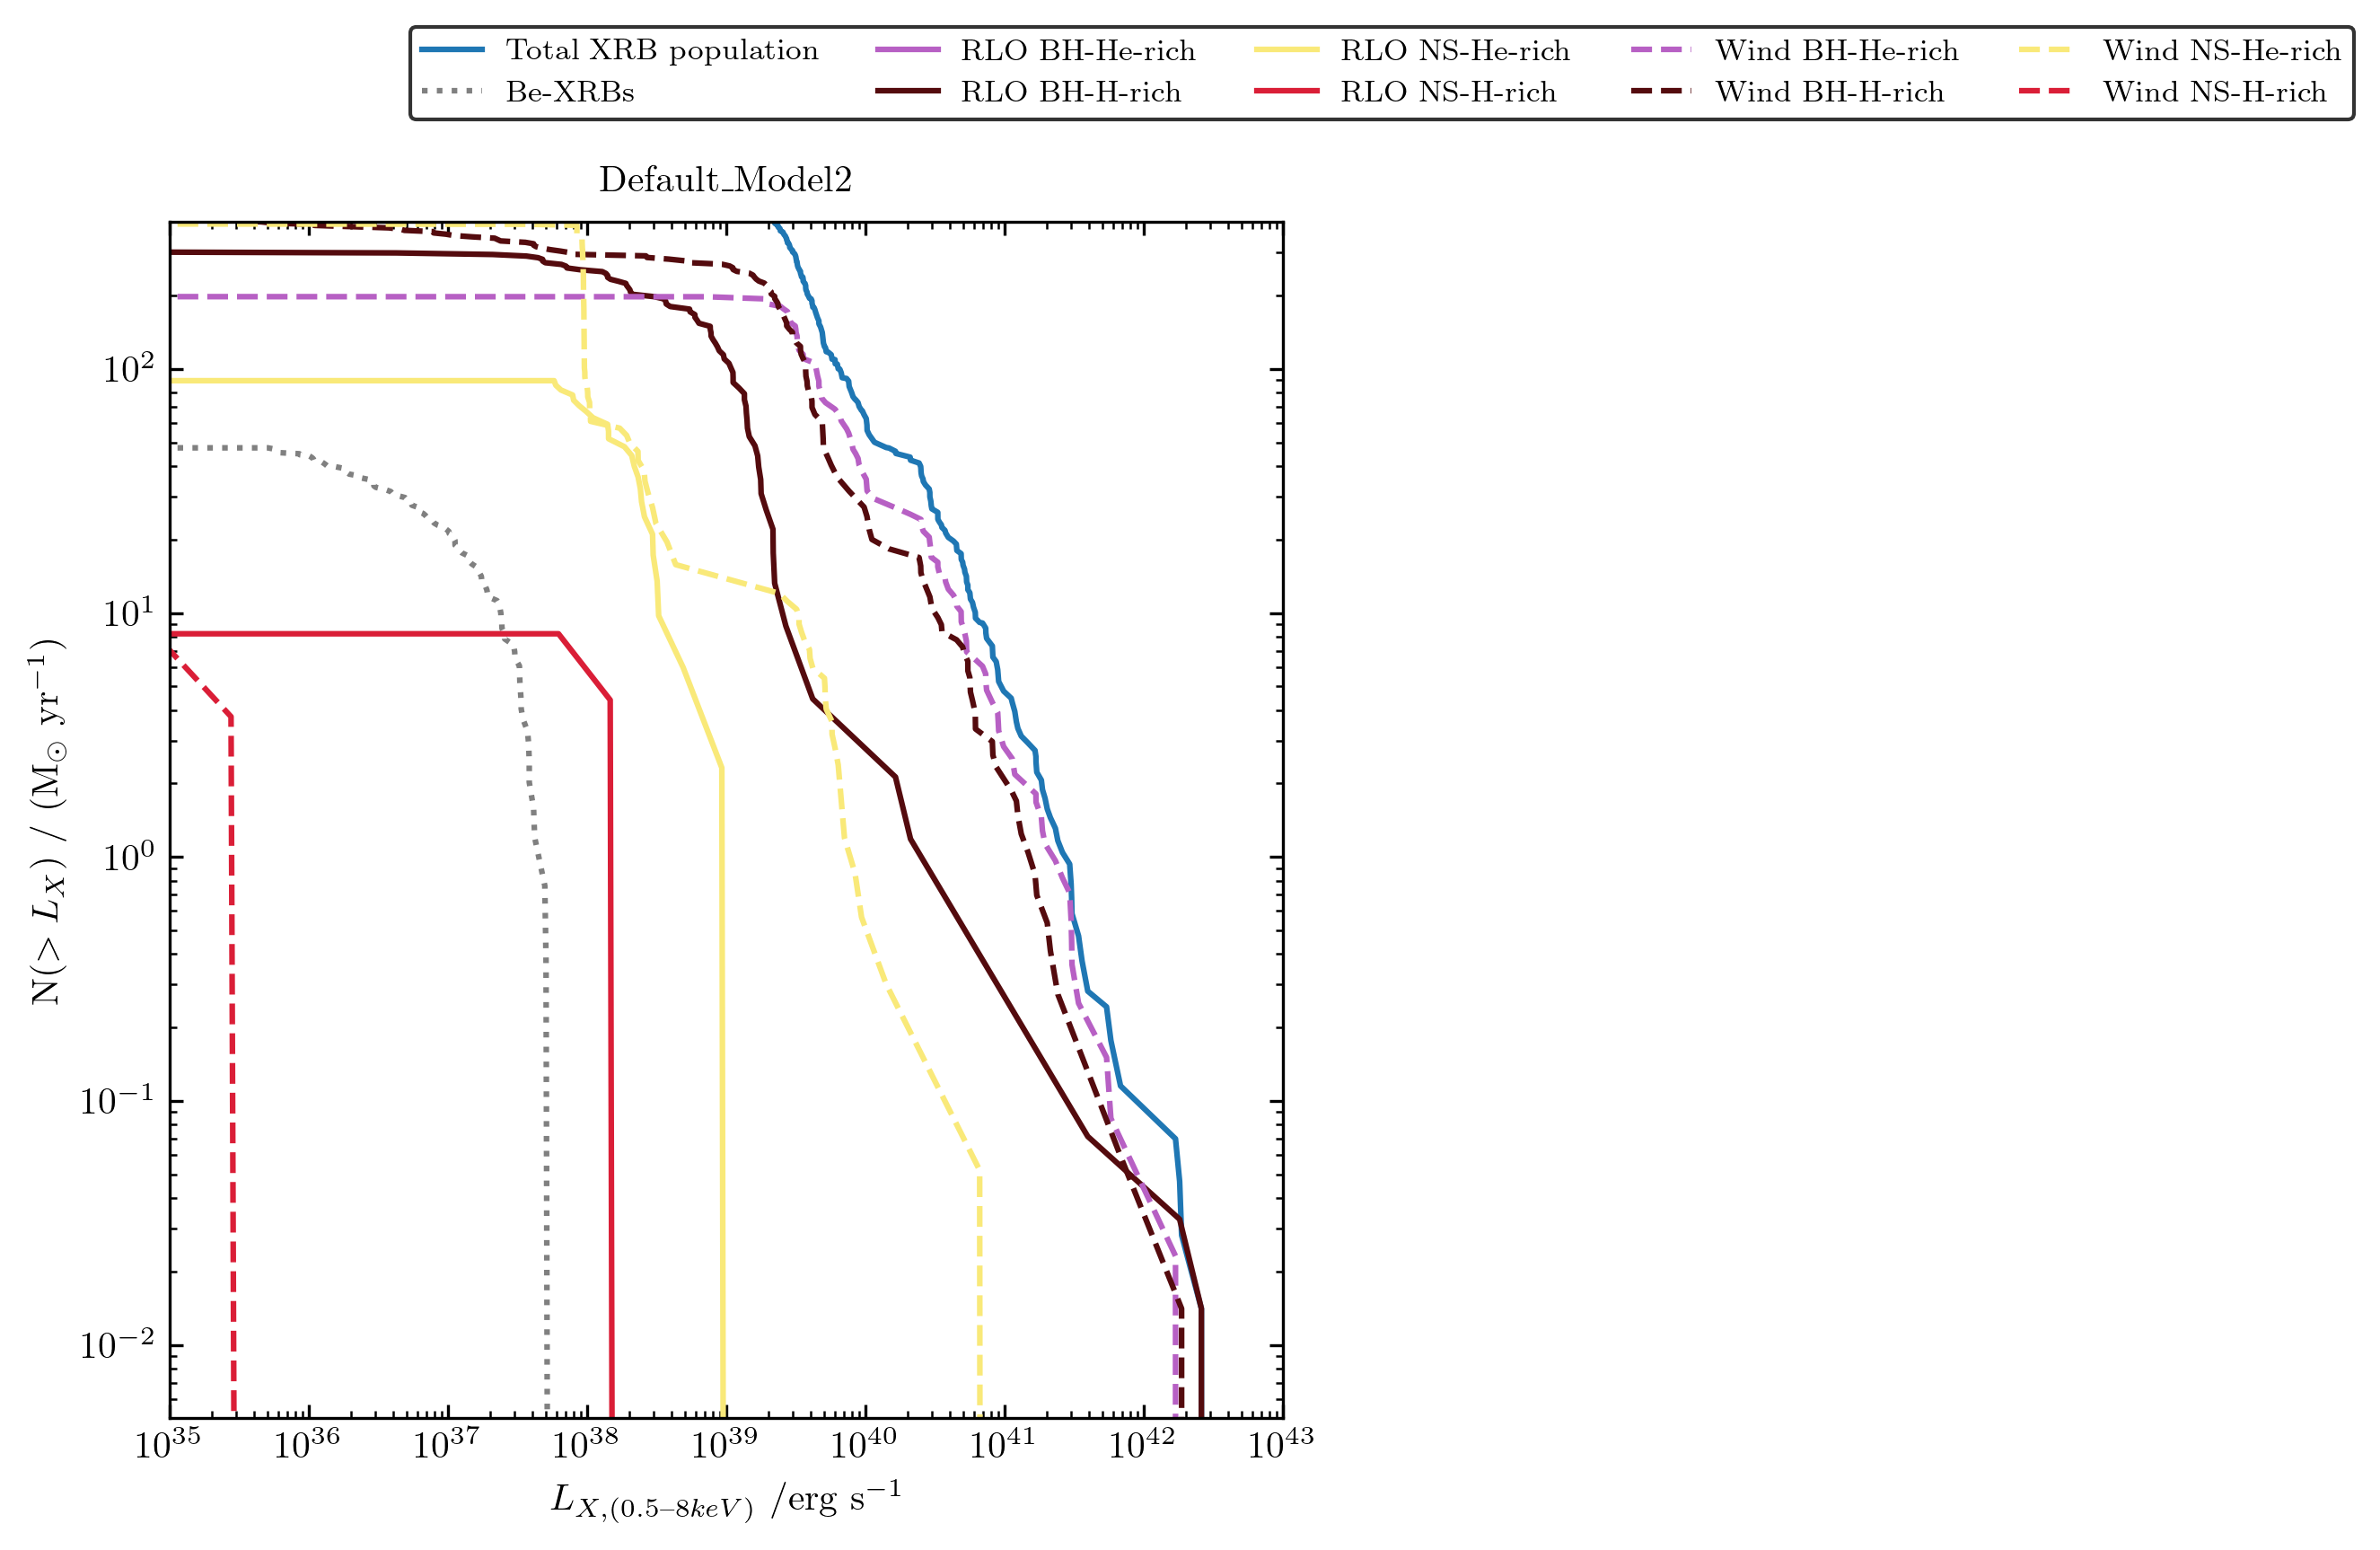

In [ ]:


models = [#('Default_Model1', Pop_my_code), 
          ('Default_Model2', XRBs_pop2_Misra0)]

ylims = [#(9e-3, 4e2), 
         (5e-3, 4e2)]

fig = xrb.plot_XLF_models(models, ncols=2, figsize=(12,6), dpi = 300, ylims=ylims, stat_kwargs=stat_kwargs)

### 4. Best models 

#### 4.1 Loading and preparing X-ray binary populations

In [4]:
Model_36 = Population('Best_models_Misra/Norm_similar/1e+00_Zsun_population36.h5')
Model36b = Population('Best_models_Misra/Norm_similar/1e+00_Zsun_population36b.h5')
Model_44 = Population('Best_models_Misra/Norm_similar/1e+00_Zsun_population44.h5')
Model_55 = Population('Best_models_Misra/Shape_similar/1e+00_Zsun_population55.h5')
Model_64 = Population('Best_models_Misra/Shape_similar/1e+00_Zsun_population64.h5')


Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [ ]:
# Only do it once
Model_36.calculate_formation_channels(mt_history=True)
Model36b.calculate_formation_channels(mt_history=True)
Model_44.calculate_formation_channels(mt_history=True)
Model_55.calculate_formation_channels(mt_history=True)
Model_64.calculate_formation_channels(mt_history=True)


In [ ]:
XRB_pop_36 = Model_36.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=True, Vwind_scheme='Kudritzki+2000', Wind_fed_scheme= None), 'XRBs_36') 
XRB_pop_36b = Model36b.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=True, Vwind_scheme='Kudritzki+2000', Wind_fed_scheme= None), 'XRBs_pop36b') #
XRB_pop_44 = Model_44.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=True, Vwind_scheme='Kudritzki+2000', Wind_fed_scheme= None), 'XRBs_44')
XRB_pop_55 = Model_55.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=True, Vwind_scheme='Kudritzki+2000', Wind_fed_scheme='HiraiMandel21'), 'XRBs_55') 
XRB_pop_64 = Model_64.create_transient_population(lambda h, o, f: XRB_selection_function(h, o, f, wind_disk_formation=True, Vwind_scheme='Kudritzki+2000', Wind_fed_scheme='HiraiMandel21'), 'XRBs_64') 

overwriting transient population
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
overwriting transient population
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
overwriting transient population
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
overwriting transient population


/home/users/a/aguetar1/XRB_functions.py:289: InappropriateValueWarning: 'Warning: Wind velocity is zero, setting accretion fraction to 1.0 (PID=3392798)'


Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max
overwriting transient population
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


- Dataframe visualisation

In [6]:
DS_36 = XRB_pop_36.population['Donor_state'].value_counts().rename('# Systems Model 36').to_frame()
DS_36b = XRB_pop_36b.population['Donor_state'].value_counts().rename('# Systems Model 36b').to_frame()
DS_44 = XRB_pop_44.population['Donor_state'].value_counts().rename('# Systems Model 44').to_frame()
DS_55 = XRB_pop_55.population['Donor_state'].value_counts().rename('# Systems Model 55').to_frame()
DS_64 = XRB_pop_64.population['Donor_state'].value_counts().rename('# Systems Model 64').to_frame()

display(pd.concat([DS_36, DS_36b, DS_44, DS_55, DS_64], axis=1))

,# Systems Model 36,# Systems Model 36b,# Systems Model 44,# Systems Model 55,# Systems Model 64
Donor_state,,,,,
H-rich_Core_H_burning,11962.0,23881,11582,14063.0,12611
H-rich_Core_He_burning,182.0,407,132,546.0,479
stripped_He_Core_He_burning,181.0,510,154,318.0,369
H-rich_non_burning,95.0,90,92,201.0,207
stripped_He_non_burning,92.0,286,92,443.0,124
stripped_He_Core_He_depleted,80.0,213,76,68.0,104
H-rich_Shell_H_burning,65.0,185,75,224.0,205
H-rich_Core_H_burning (Be star),49.0,133,43,143.0,136
accreted_He_non_burning,20.0,20,12,34.0,38


#### 4.2 Plotting XLFs of XRB populations

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/synthetic_population.py:1992: OverwriteWarning: 'Model weights already exist! Overwriting them!'
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered i

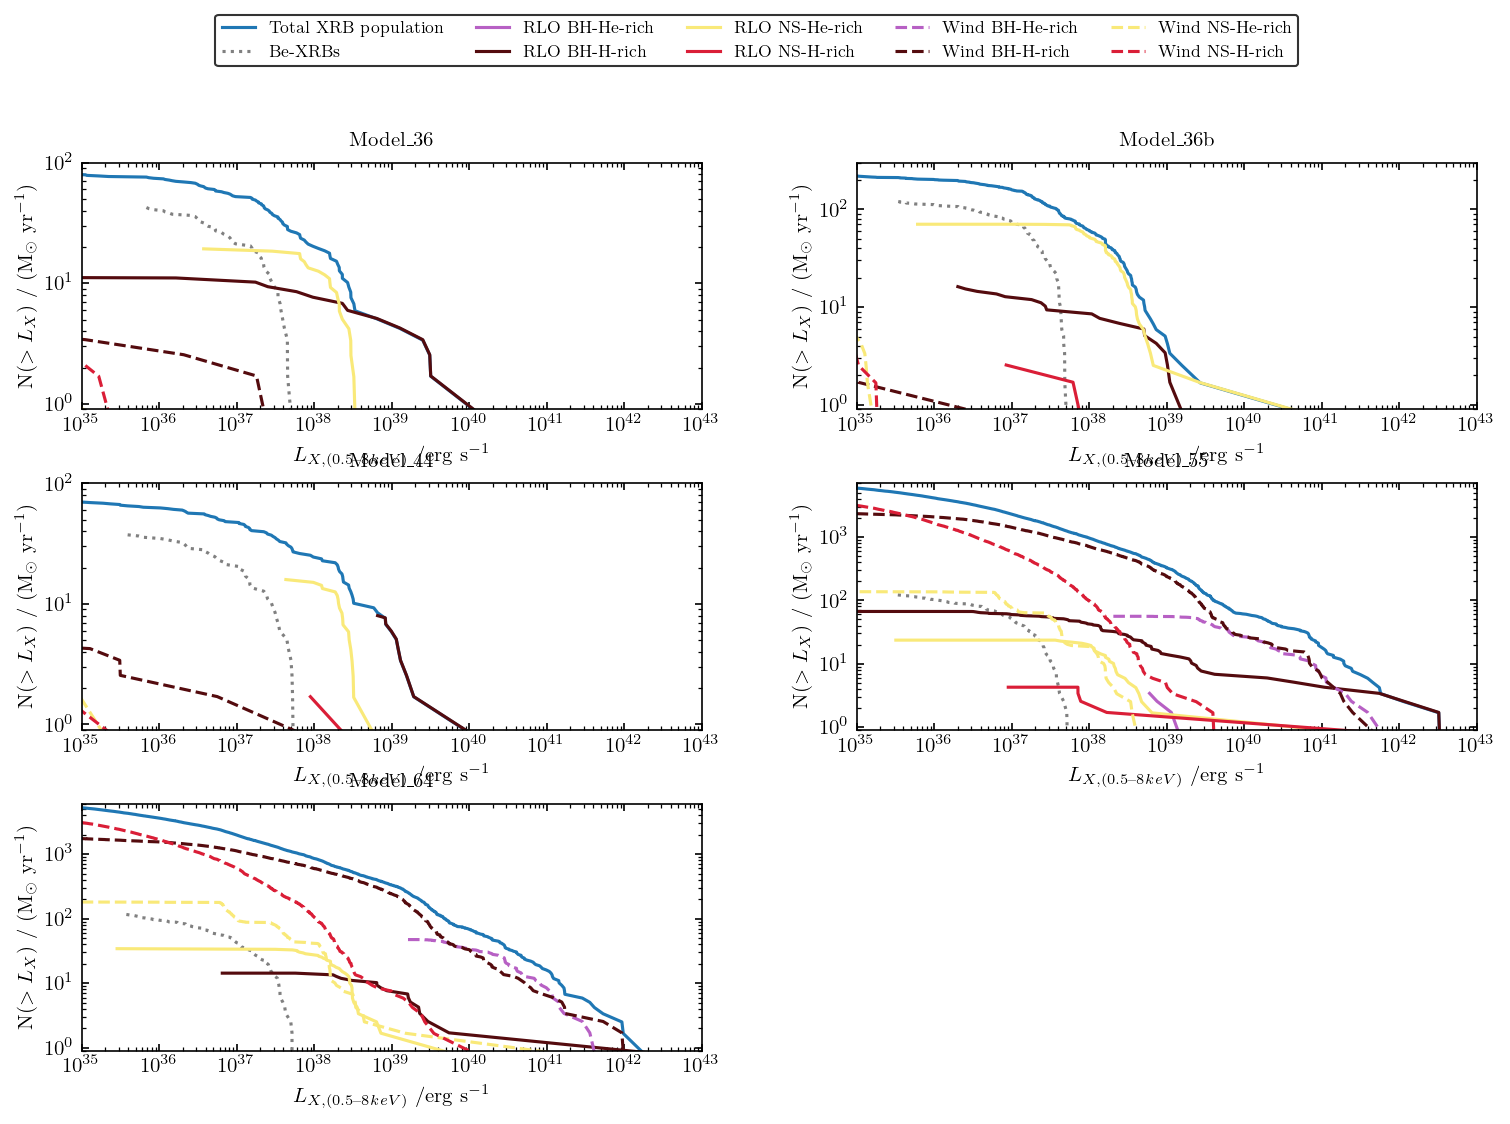

In [8]:
models = [
    ('Model_36', XRB_pop_36),
    ('Model_36b', XRB_pop_36b),
    ('Model_44', XRB_pop_44),
    ('Model_55', XRB_pop_55),
    ('Model_64', XRB_pop_64),
]
ylims = {'Model_36' : (9e-1, 1e2), 
         'Model_36b' : (9e-1, 3e2),
         'Model_44' : (9e-1, 1e2),
         'Model_55' : (9e-1, 7e3),
         'Model_64' : (9e-1, 6e3),
        }

fig = plot_XLF_models(models, ncols=2, figsize=(12, 8), ylims=ylims)

#### 4.3 Individual plots of XLFs

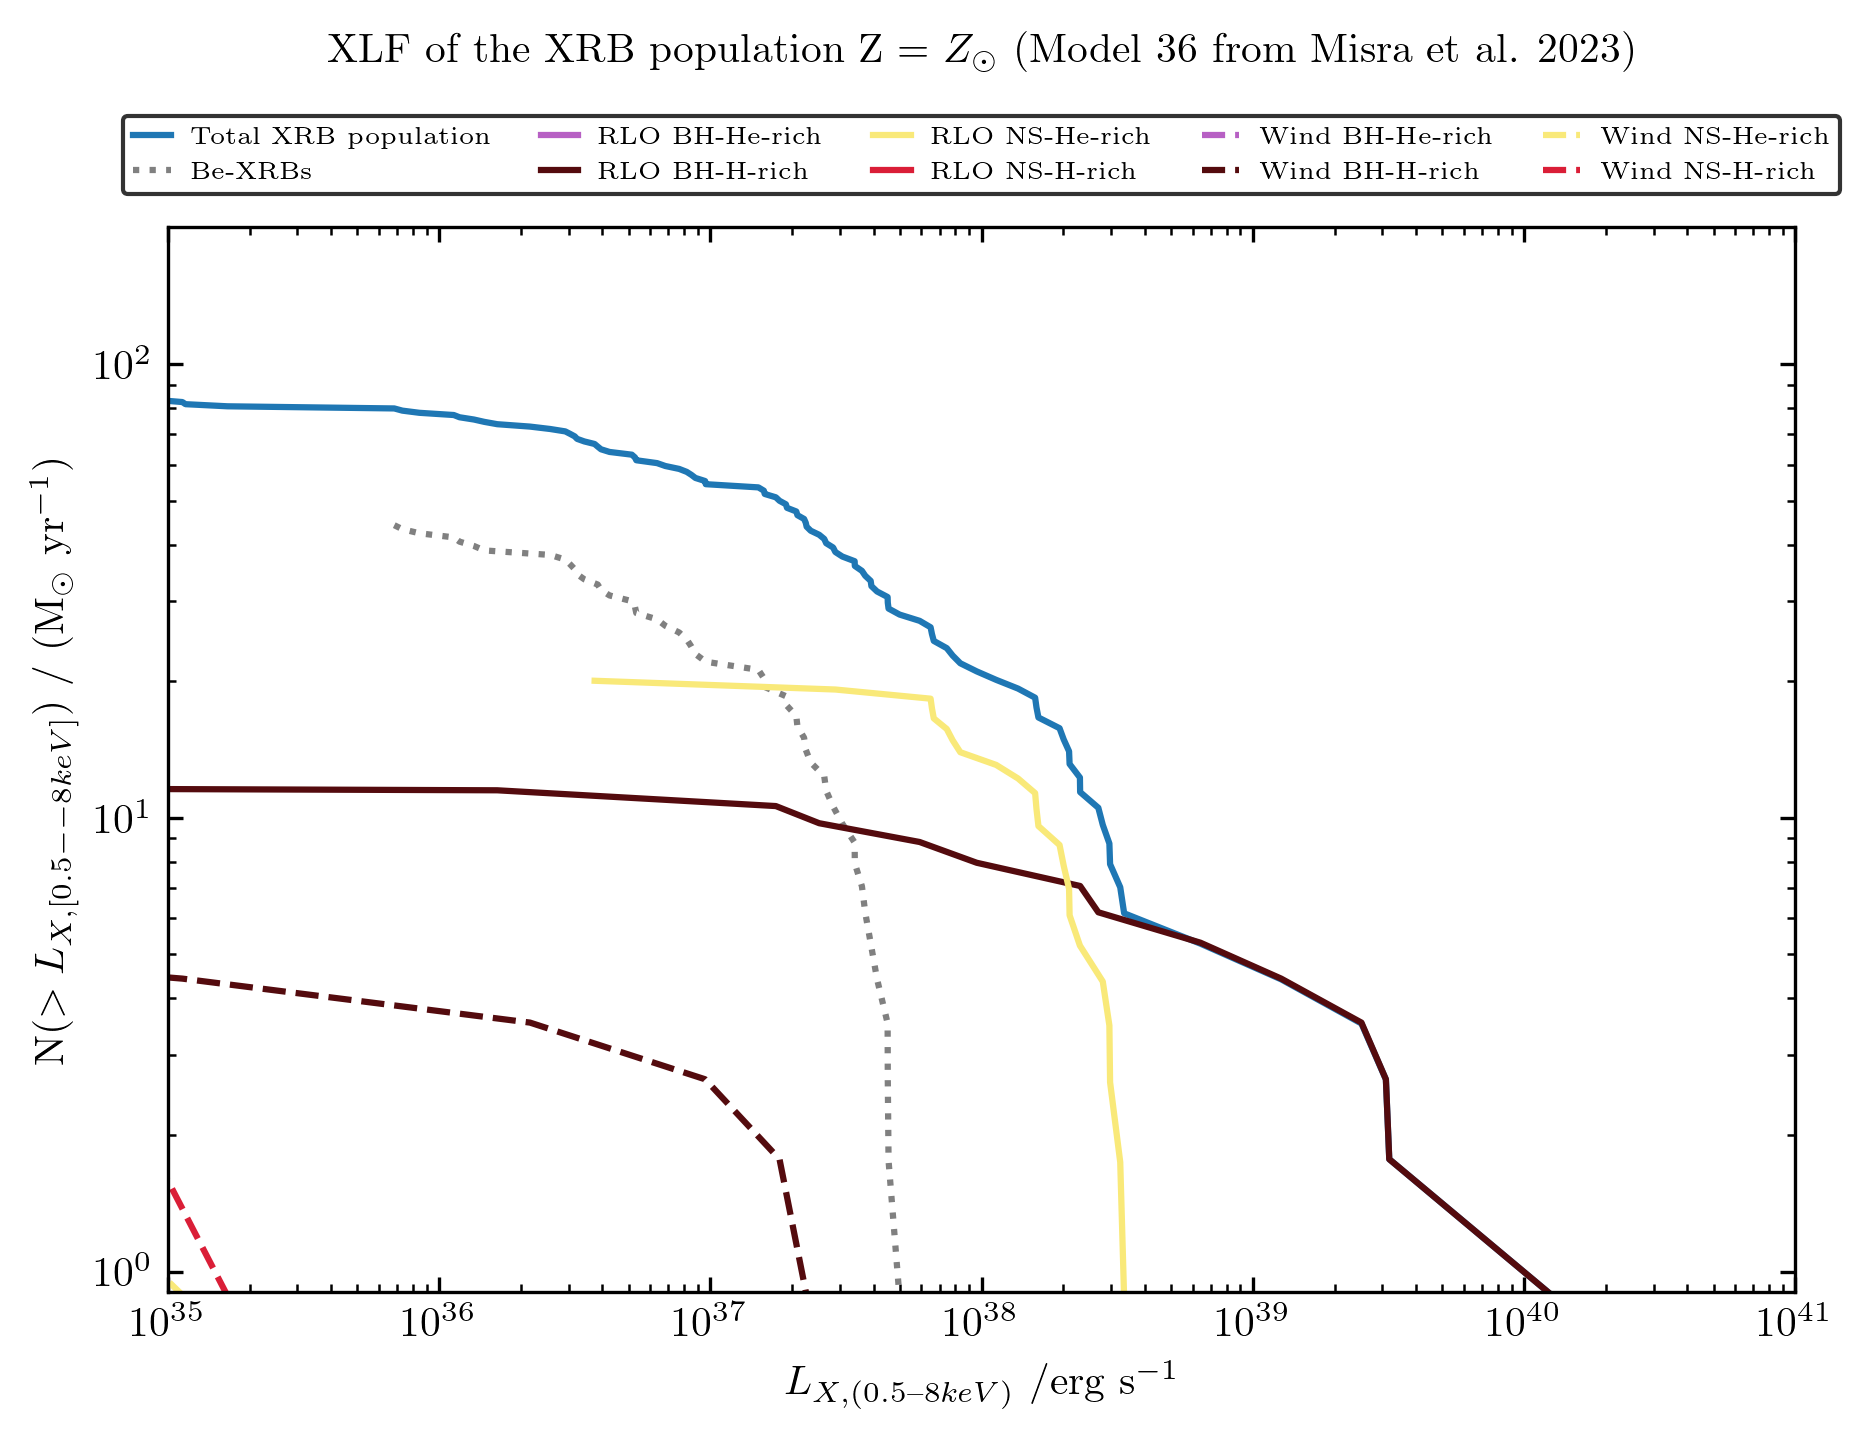

In [12]:
L_min = 1e30 # Minimal luminosity threshold for XRBs [erg/s]
L_max = 1e43

# Boolean masks of length 14220
BH1 = XRB_pop_36.population['Accretor_state'] == 'BH'
NS1 = XRB_pop_36.population['Accretor_state'] == 'NS'
H1_rich = (XRB_pop_36.population['Donor_state'].str.contains('H-rich|accreted_He', regex=True) & ~XRB_pop_36.population['Donor_state'].str.contains('Be star'))
stripped_He = XRB_pop_36.population['Donor_state'].str.contains('stripped_He')
#accreted_He = XRB_pop_36.population['Donor_state'].str.contains('accreted_He')
Be_XRB = XRB_pop_36.population['Donor_state'].str.contains('Be star')

#===== Mask selection =====
RLO = (XRB_pop_36.population['Lx_RLO'] > XRB_pop_36.population['Lx_BHL']) & (XRB_pop_36.population['Lx_RLO'] > L_min) & (L_max > XRB_pop_36.population['Lx_RLO']) # True/False pandas series
Wind = (XRB_pop_36.population['Lx_BHL'] > XRB_pop_36.population['Lx_RLO']) & (XRB_pop_36.population['Lx_BHL'] > L_min) & (L_max > XRB_pop_36.population['Lx_BHL'])# True/False pandas series
Lumino_range = (XRB_pop_36.population['Lx_Total'] < L_max) & (XRB_pop_36.population['Lx_Total'] > L_min)


#===== Plotting =====
fig , ax = plt.subplots(figsize=(7,5), dpi=300)
plot_ccdf(XRB_pop_36, ax, weights_36, Lumino_range, 'Total XRB population', linestyle='-', color='#1F77B4')
plot_ccdf(XRB_pop_36, ax, weights_36, Be_XRB, 'Be-XRBs', linestyle=':', color='#808080')

plot_ccdf(XRB_pop_36, ax, weights_36, RLO & BH1 & stripped_He, 'RLO BH-He-rich', linestyle='-', color='#B760C4')
plot_ccdf(XRB_pop_36, ax, weights_36, RLO & BH1 & H1_rich, 'RLO BH-H-rich', linestyle='-', color='#540B0E')
plot_ccdf(XRB_pop_36, ax, weights_36, RLO & NS1 & stripped_He, 'RLO NS-He-rich', linestyle='-', color='#F9E979')
plot_ccdf(XRB_pop_36, ax, weights_36, RLO & NS1 & H1_rich, 'RLO NS-H-rich', linestyle='-', color='#DA1E37')

plot_ccdf(XRB_pop_36, ax, weights_36, Wind & BH1 & stripped_He, 'Wind BH-He-rich', linestyle='--', color='#B760C4')
plot_ccdf(XRB_pop_36, ax, weights_36, Wind & BH1 & H1_rich, 'Wind BH-H-rich', linestyle='--', color='#540B0E')
plot_ccdf(XRB_pop_36, ax, weights_36, Wind & NS1 & stripped_He, 'Wind NS-He-rich', linestyle='--', color='#F9E979')
plot_ccdf(XRB_pop_36, ax, weights_36, Wind & NS1 & H1_rich , 'Wind NS-H-rich', linestyle='--', color='#DA1E37')


ax.set_title(r'XLF of the XRB population Z = $Z_{\odot}$ (Model 36 from Misra et al. 2023)', pad = 40)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$L_{X,(0.5–8 keV)}$ /erg s$^{-1}$')
ax.set_ylabel(r'N($> L_{X,[0.5--8 keV]}$) / (M$_\odot$ yr$^{-1}$)')
ax.set_xlim(1e35, 1e41)
ax.set_ylim(9e-1, 2e2)
legend = ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), bbox_transform=ax.transAxes, 
                   ncol=5, frameon=True, fancybox=True, edgecolor='k', handlelength=1.5, borderpad=0.4, fontsize=6)
fig.subplots_adjust(top=0.82)  # ajuster l'espace supérieur pour la légende

plt.show()

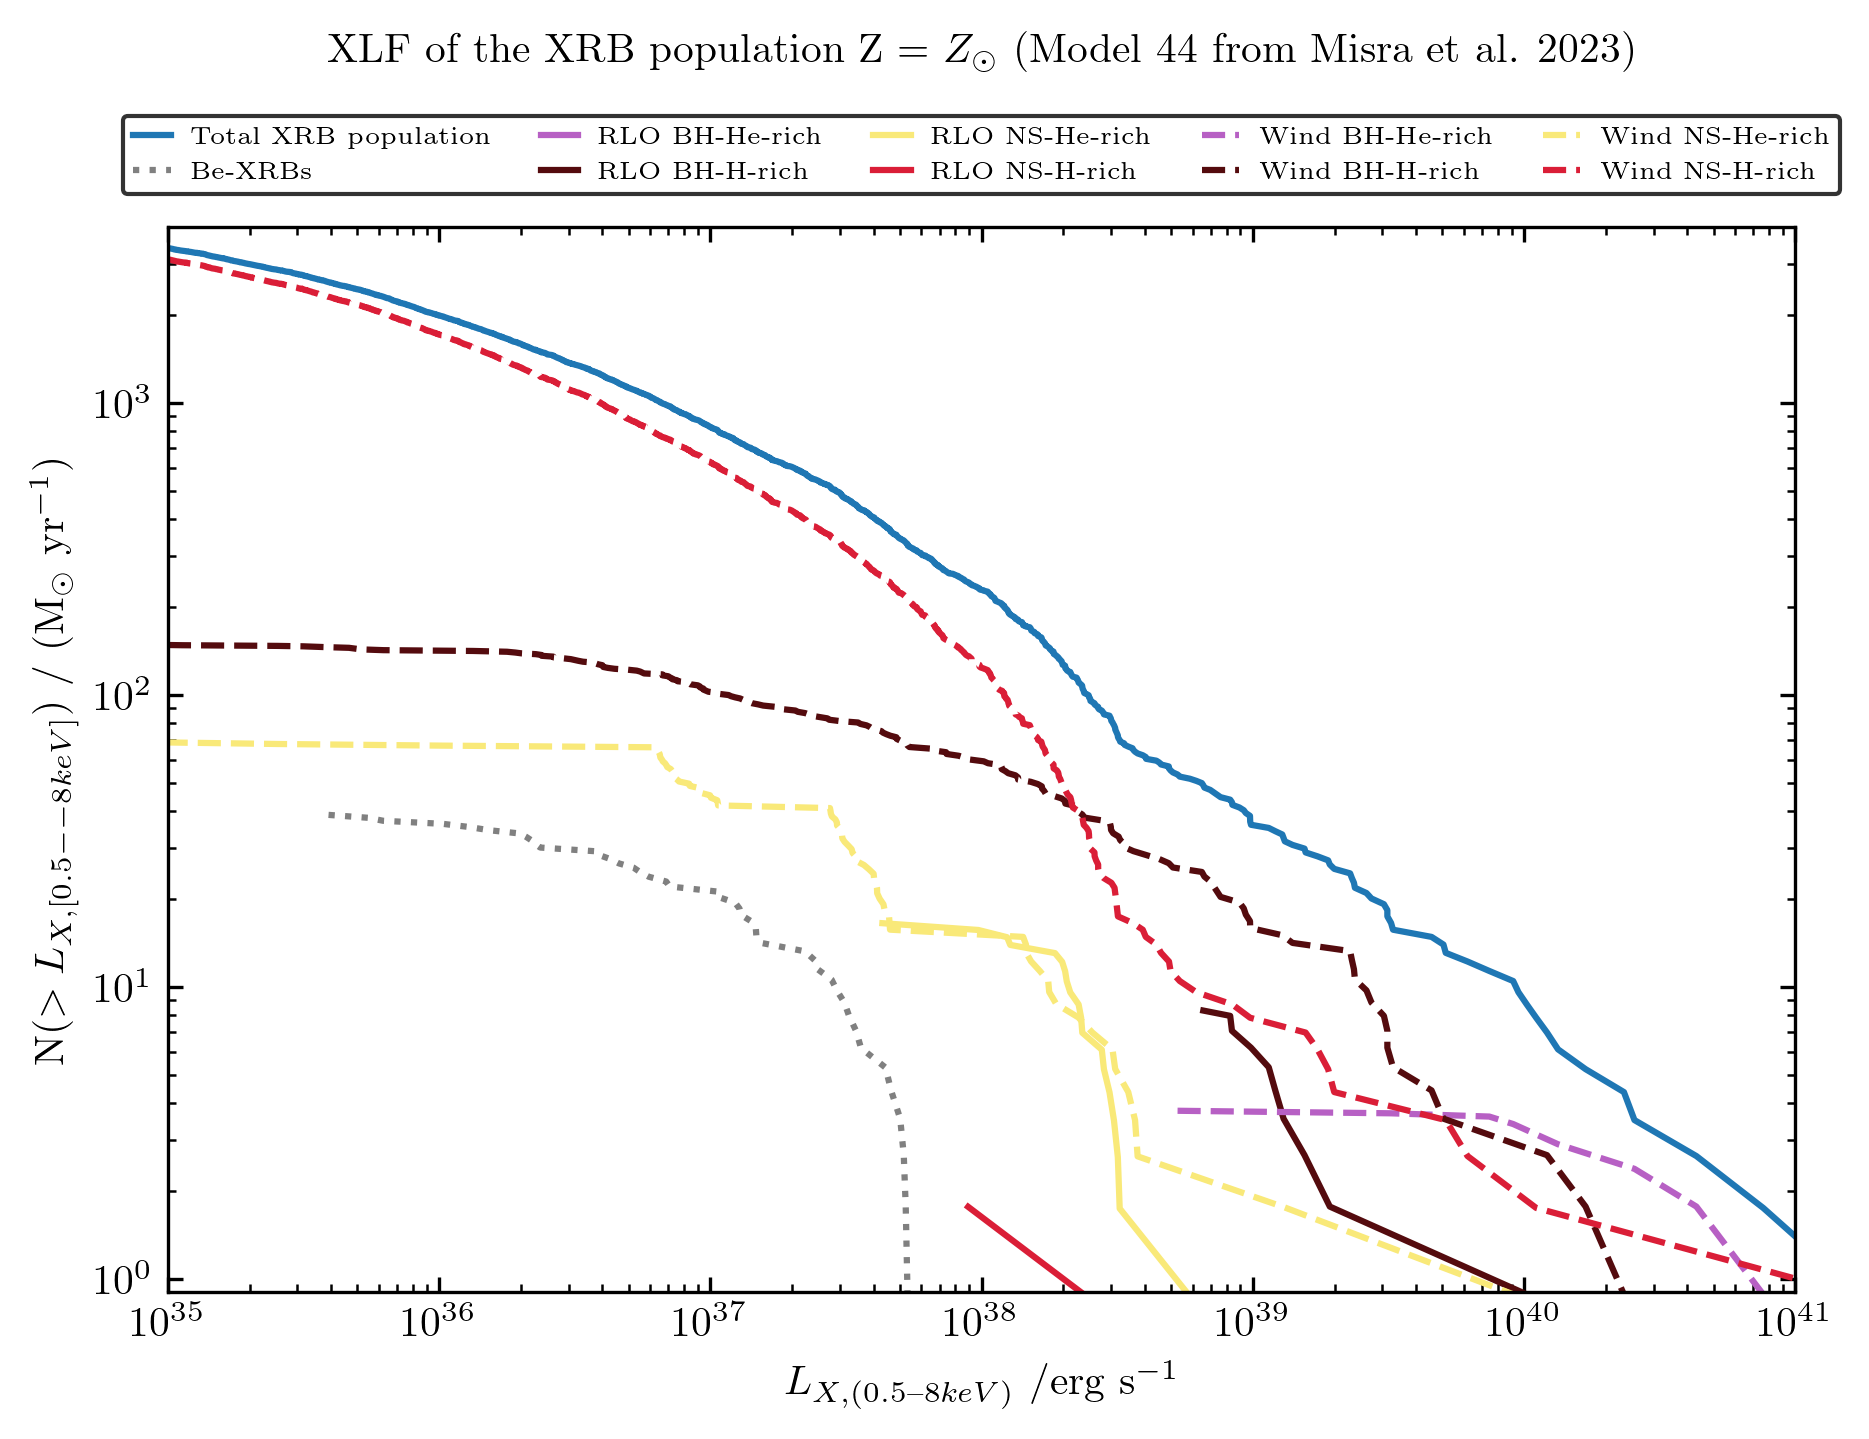

In [13]:
L_min = 1e30 # Minimal luminosity threshold for XRBs [erg/s]
L_max = 1e43

# Boolean masks of length 14220
BH1 = XRB_pop_44.population['Accretor_state'] == 'BH'
NS1 = XRB_pop_44.population['Accretor_state'] == 'NS'
H1_rich = (XRB_pop_44.population['Donor_state'].str.contains('H-rich|accreted_He', regex=True) & ~XRB_pop_44.population['Donor_state'].str.contains('Be star'))
stripped_He = XRB_pop_44.population['Donor_state'].str.contains('stripped_He')
#accreted_He = XRB_pop_44.population['Donor_state'].str.contains('accreted_He')
Be_XRB = XRB_pop_44.population['Donor_state'].str.contains('Be star')

#===== Mask selection =====
RLO = (XRB_pop_44.population['Lx_RLO'] > XRB_pop_44.population['Lx_BHL']) & (XRB_pop_44.population['Lx_RLO'] > L_min) & (L_max > XRB_pop_44.population['Lx_RLO']) # True/False pandas series
Wind = (XRB_pop_44.population['Lx_BHL'] > XRB_pop_44.population['Lx_RLO']) & (XRB_pop_44.population['Lx_BHL'] > L_min) & (L_max > XRB_pop_44.population['Lx_BHL'])# True/False pandas series
Lumino_range = (XRB_pop_44.population['Lx_Total'] < L_max) & (XRB_pop_44.population['Lx_Total'] > L_min)


#===== Plotting =====
fig , ax = plt.subplots(figsize=(7,5), dpi=300)
plot_ccdf(XRB_pop_44, ax, weights_44, Lumino_range, 'Total XRB population', linestyle='-', color='#1F77B4')
plot_ccdf(XRB_pop_44, ax, weights_44, Be_XRB, 'Be-XRBs', linestyle=':', color='#808080')

plot_ccdf(XRB_pop_44, ax, weights_44, RLO & BH1 & stripped_He, 'RLO BH-He-rich', linestyle='-', color='#B760C4')
plot_ccdf(XRB_pop_44, ax, weights_44, RLO & BH1 & H1_rich, 'RLO BH-H-rich', linestyle='-', color='#540B0E')
plot_ccdf(XRB_pop_44, ax, weights_44, RLO & NS1 & stripped_He, 'RLO NS-He-rich', linestyle='-', color='#F9E979')
plot_ccdf(XRB_pop_44, ax, weights_44, RLO & NS1 & H1_rich, 'RLO NS-H-rich', linestyle='-', color='#DA1E37')

plot_ccdf(XRB_pop_44, ax, weights_44, Wind & BH1 & stripped_He, 'Wind BH-He-rich', linestyle='--', color='#B760C4')
plot_ccdf(XRB_pop_44, ax, weights_44, Wind & BH1 & H1_rich, 'Wind BH-H-rich', linestyle='--', color='#540B0E')
plot_ccdf(XRB_pop_44, ax, weights_44, Wind & NS1 & stripped_He, 'Wind NS-He-rich', linestyle='--', color='#F9E979')
plot_ccdf(XRB_pop_44, ax, weights_44, Wind & NS1 & H1_rich , 'Wind NS-H-rich', linestyle='--', color='#DA1E37')


ax.set_title(r'XLF of the XRB population Z = $Z_{\odot}$ (Model 44 from Misra et al. 2023)', pad = 40)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$L_{X,(0.5–8 keV)}$ /erg s$^{-1}$')
ax.set_ylabel(r'N($> L_{X,[0.5--8 keV]}$) / (M$_\odot$ yr$^{-1}$)')
ax.set_xlim(1e35, 1e41)
ax.set_ylim(9e-1, 4e3)
legend = ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), bbox_transform=ax.transAxes, 
                   ncol=5, frameon=True, fancybox=True, edgecolor='k', handlelength=1.5, borderpad=0.4, fontsize=6)
fig.subplots_adjust(top=0.82)  # ajuster l'espace supérieur pour la légende

plt.show()

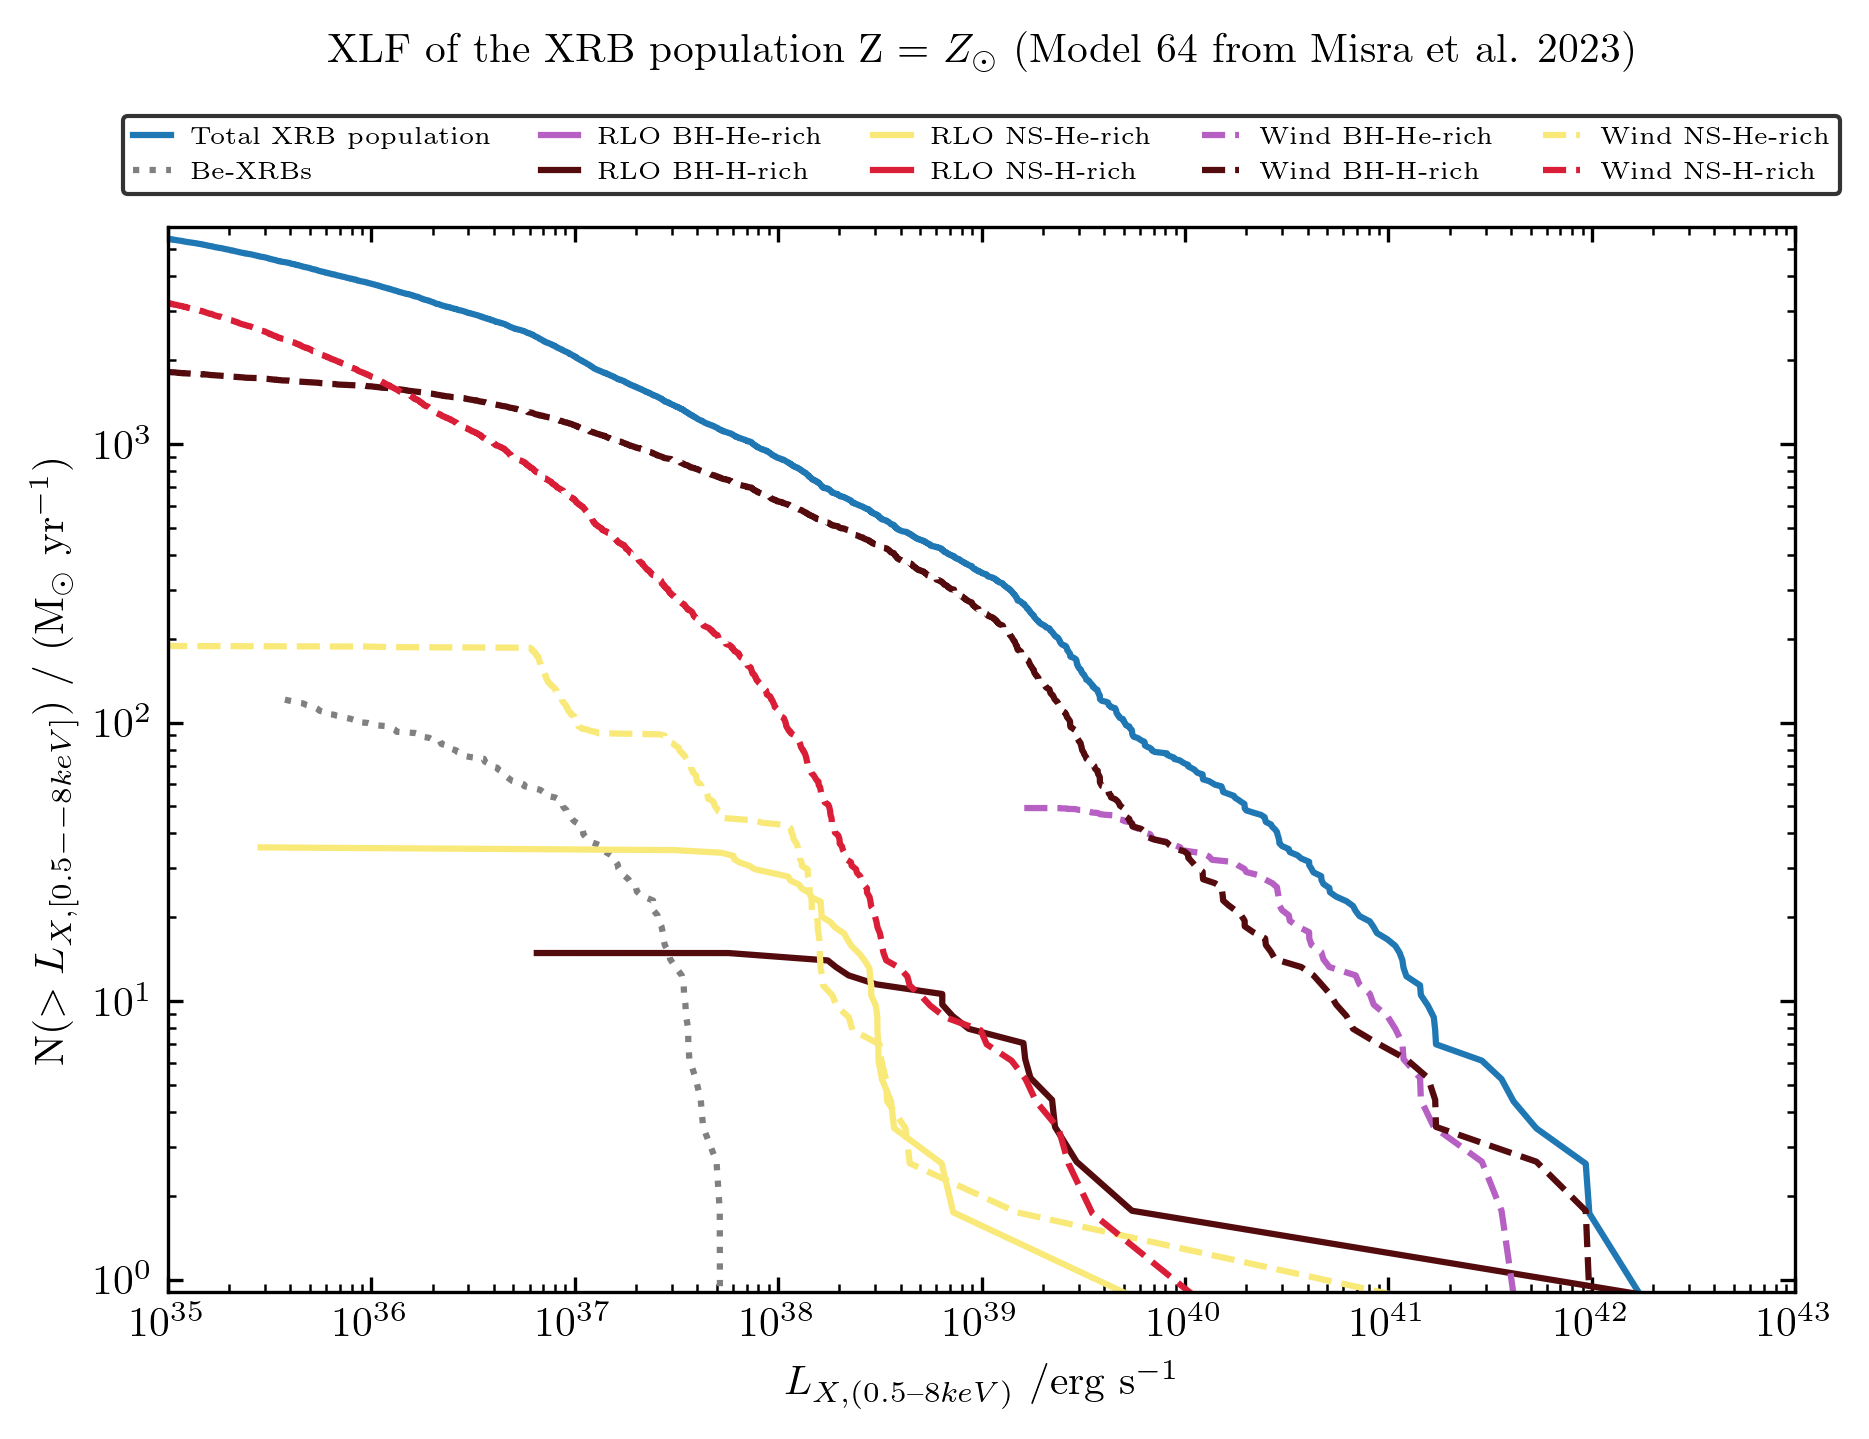

In [17]:
L_min = 1e30 # Minimal luminosity threshold for XRBs [erg/s]
L_max = 1e43

# Boolean masks of length 14220
BH1 = XRB_pop_64.population['Accretor_state'] == 'BH'
NS1 = XRB_pop_64.population['Accretor_state'] == 'NS'
H1_rich = (XRB_pop_64.population['Donor_state'].str.contains('H-rich|accreted_He', regex=True) & ~XRB_pop_64.population['Donor_state'].str.contains('Be star'))
stripped_He = XRB_pop_64.population['Donor_state'].str.contains('stripped_He')
#accreted_He = XRB_pop_64.population['Donor_state'].str.contains('accreted_He')
Be_XRB = XRB_pop_64.population['Donor_state'].str.contains('Be star')

#===== Mask selection =====
RLO = (XRB_pop_64.population['Lx_RLO'] > XRB_pop_64.population['Lx_BHL']) & (XRB_pop_64.population['Lx_RLO'] > L_min) & (L_max > XRB_pop_64.population['Lx_RLO']) # True/False pandas series
Wind = (XRB_pop_64.population['Lx_BHL'] > XRB_pop_64.population['Lx_RLO']) & (XRB_pop_64.population['Lx_BHL'] > L_min) & (L_max > XRB_pop_64.population['Lx_BHL'])# True/False pandas series
Lumino_range = (XRB_pop_64.population['Lx_Total'] < L_max) & (XRB_pop_64.population['Lx_Total'] > L_min)


#===== Plotting =====
fig , ax = plt.subplots(figsize=(7,5), dpi=300)
plot_ccdf(XRB_pop_64, ax, weights_64, Lumino_range, 'Total XRB population', linestyle='-', color='#1F77B4')
plot_ccdf(XRB_pop_64, ax, weights_64, Be_XRB, 'Be-XRBs', linestyle=':', color='#808080')

plot_ccdf(XRB_pop_64, ax, weights_64, RLO & BH1 & stripped_He, 'RLO BH-He-rich', linestyle='-', color='#B760C4')
plot_ccdf(XRB_pop_64, ax, weights_64, RLO & BH1 & H1_rich, 'RLO BH-H-rich', linestyle='-', color='#540B0E')
plot_ccdf(XRB_pop_64, ax, weights_64, RLO & NS1 & stripped_He, 'RLO NS-He-rich', linestyle='-', color='#F9E979')
plot_ccdf(XRB_pop_64, ax, weights_64, RLO & NS1 & H1_rich, 'RLO NS-H-rich', linestyle='-', color='#DA1E37')

plot_ccdf(XRB_pop_64, ax, weights_64, Wind & BH1 & stripped_He, 'Wind BH-He-rich', linestyle='--', color='#B760C4')
plot_ccdf(XRB_pop_64, ax, weights_64, Wind & BH1 & H1_rich, 'Wind BH-H-rich', linestyle='--', color='#540B0E')
plot_ccdf(XRB_pop_64, ax, weights_64, Wind & NS1 & stripped_He, 'Wind NS-He-rich', linestyle='--', color='#F9E979')
plot_ccdf(XRB_pop_64, ax, weights_64, Wind & NS1 & H1_rich , 'Wind NS-H-rich', linestyle='--', color='#DA1E37')


ax.set_title(r'XLF of the XRB population Z = $Z_{\odot}$ (Model 64 from Misra et al. 2023)', pad = 40)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$L_{X,(0.5–8 keV)}$ /erg s$^{-1}$')
ax.set_ylabel(r'N($> L_{X,[0.5--8 keV]}$) / (M$_\odot$ yr$^{-1}$)')
ax.set_xlim(1e35, 1e43)
ax.set_ylim(9e-1, 6e3)
legend = ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), bbox_transform=ax.transAxes, 
                   ncol=5, frameon=True, fancybox=True, edgecolor='k', handlelength=1.5, borderpad=0.4, fontsize=6)
fig.subplots_adjust(top=0.82)  # ajuster l'espace supérieur pour la légende

plt.show()

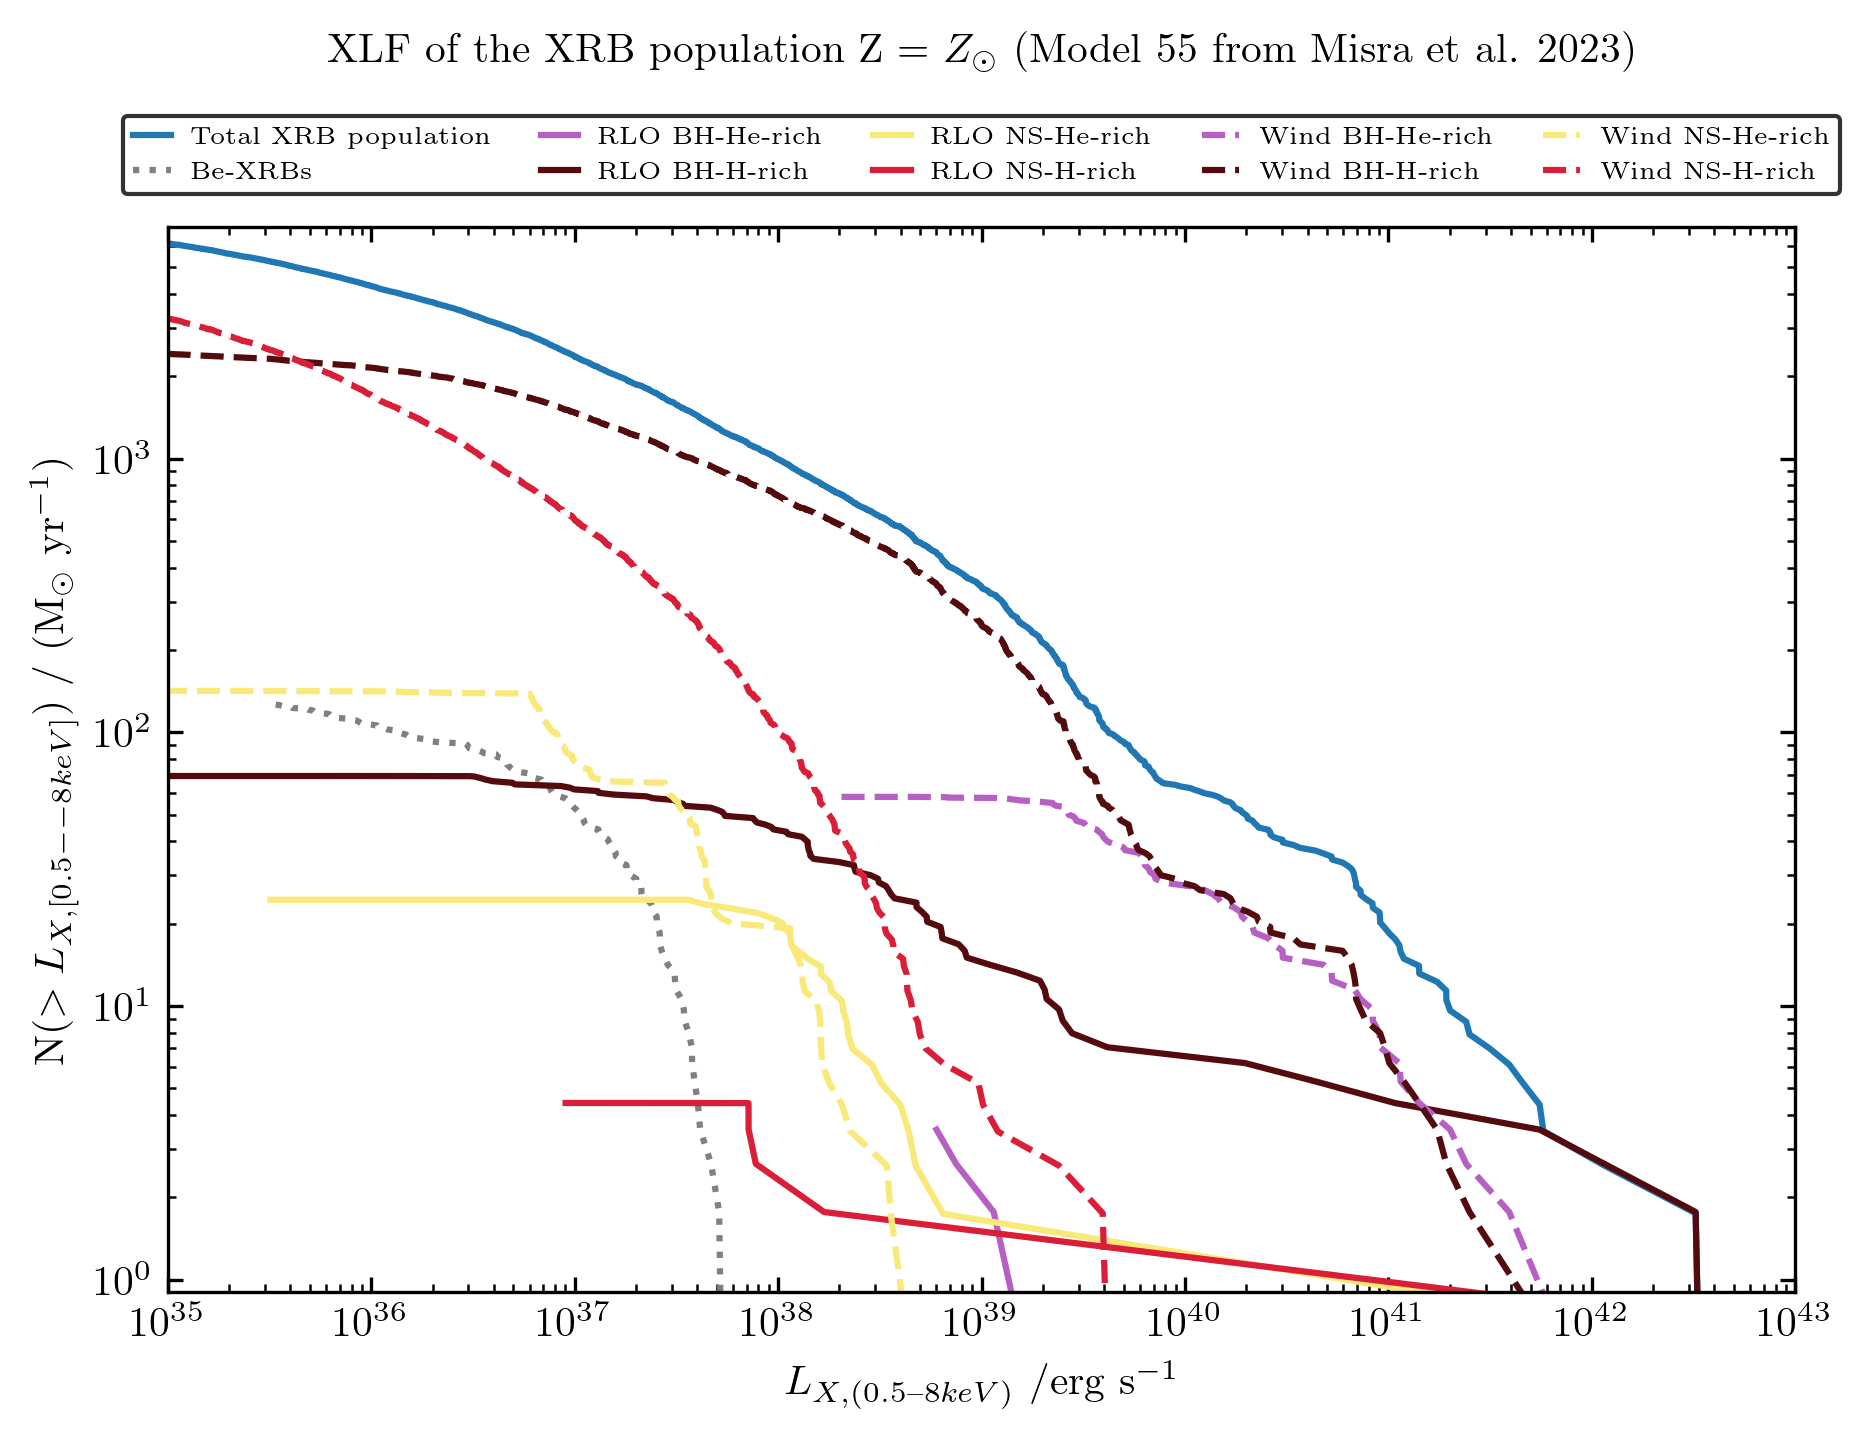

In [20]:
L_min = 1e30 # Minimal luminosity threshold for XRBs [erg/s]
L_max = 1e43

# Boolean masks of length 14220
BH1 = XRB_pop_55.population['Accretor_state'] == 'BH'
NS1 = XRB_pop_55.population['Accretor_state'] == 'NS'
H1_rich = (XRB_pop_55.population['Donor_state'].str.contains('H-rich|accreted_He', regex=True) & ~XRB_pop_55.population['Donor_state'].str.contains('Be star'))
stripped_He = XRB_pop_55.population['Donor_state'].str.contains('stripped_He')
#accreted_He = XRB_pop_55.population['Donor_state'].str.contains('accreted_He')
Be_XRB = XRB_pop_55.population['Donor_state'].str.contains('Be star')

#===== Mask selection =====
RLO = (XRB_pop_55.population['Lx_RLO'] > XRB_pop_55.population['Lx_BHL']) & (XRB_pop_55.population['Lx_RLO'] > L_min) & (L_max > XRB_pop_55.population['Lx_RLO']) # True/False pandas series
Wind = (XRB_pop_55.population['Lx_BHL'] > XRB_pop_55.population['Lx_RLO']) & (XRB_pop_55.population['Lx_BHL'] > L_min) & (L_max > XRB_pop_55.population['Lx_BHL'])# True/False pandas series
Lumino_range = (XRB_pop_55.population['Lx_Total'] < L_max) & (XRB_pop_55.population['Lx_Total'] > L_min)


#===== Plotting =====
fig , ax = plt.subplots(figsize=(7,5), dpi=300)
plot_ccdf(XRB_pop_55, ax, weights_55, Lumino_range, 'Total XRB population', linestyle='-', color='#1F77B4')
plot_ccdf(XRB_pop_55, ax, weights_55, Be_XRB, 'Be-XRBs', linestyle=':', color='#808080')

plot_ccdf(XRB_pop_55, ax, weights_55, RLO & BH1 & stripped_He, 'RLO BH-He-rich', linestyle='-', color='#B760C4')
plot_ccdf(XRB_pop_55, ax, weights_55, RLO & BH1 & H1_rich, 'RLO BH-H-rich', linestyle='-', color='#540B0E')
plot_ccdf(XRB_pop_55, ax, weights_55, RLO & NS1 & stripped_He, 'RLO NS-He-rich', linestyle='-', color='#F9E979')
plot_ccdf(XRB_pop_55, ax, weights_55, RLO & NS1 & H1_rich, 'RLO NS-H-rich', linestyle='-', color='#DA1E37')

plot_ccdf(XRB_pop_55, ax, weights_55, Wind & BH1 & stripped_He, 'Wind BH-He-rich', linestyle='--', color='#B760C4')
plot_ccdf(XRB_pop_55, ax, weights_55, Wind & BH1 & H1_rich, 'Wind BH-H-rich', linestyle='--', color='#540B0E')
plot_ccdf(XRB_pop_55, ax, weights_55, Wind & NS1 & stripped_He, 'Wind NS-He-rich', linestyle='--', color='#F9E979')
plot_ccdf(XRB_pop_55, ax, weights_55, Wind & NS1 & H1_rich , 'Wind NS-H-rich', linestyle='--', color='#DA1E37')


ax.set_title(r'XLF of the XRB population Z = $Z_{\odot}$ (Model 55 from Misra et al. 2023)', pad = 40)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$L_{X,(0.5–8 keV)}$ /erg s$^{-1}$')
ax.set_ylabel(r'N($> L_{X,[0.5--8 keV]}$) / (M$_\odot$ yr$^{-1}$)')
ax.set_xlim(1e35, 1e43)
ax.set_ylim(9e-1, 7e3)
legend = ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), bbox_transform=ax.transAxes, 
                   ncol=5, frameon=True, fancybox=True, edgecolor='k', handlelength=1.5, borderpad=0.4, fontsize=6)
fig.subplots_adjust(top=0.82)  # ajuster l'espace supérieur pour la légende

plt.show()

### 5. Tests

In [ ]:
selection = Population('BHNS_only.h5')

In [ ]:

def Eddington_limit(accretor_mass, Donor_surface_H1, eta):
    """
    Compute the Eddington accretion rate from the accretor mass, its accretion efficieny and the content of hydrogen at the surface of the donor star.
    Also compute the Eddington luminosity.

    Parameters
    ----------
    accretor_mass : float
        Mass of the accretor in [M⊙].
    Donor_surface_H1 : float
        Hydrogen mass fraction of the donor star's surface (surface_h1_f).
    eta : float
        Radiative efficiency of the accretor (NS or BH), dimensionless.

    Returns
    -------
    Mdot_Edd_gps : float
        Eddington accretion rate in [g/s].
    L_edd : float 
        Eddington luminosity in [erg/s].
    
    """
    L_edd = 4.0 * np.pi * const.standard_cgrav * accretor_mass * const.Msun * const.clight /(0.2 * (1.0 + Donor_surface_H1)) # [erg/s]

    Mdot_Edd_gps = L_edd / (eta * const.clight**2) # [g/s]

    return Mdot_Edd_gps, L_edd

def BH_efficiency(spin): 
    """
    Compute the radiative efficiency of a Kerr black hole (or Schwarzschild BH if spin = 0)
    as a function of the spin parameter *a* and the mass according to Novikov-Thorne radiative efficiency [[1]_] .
    
    Parameters
    ---------- 
    mass : float
        Mass of the black hole in [M⊙].
    spin : float
        Spin of the black hole. Can be given as dimensionless spin "*a**" [c*J/(GM^2)] or dimensional spin "*a*" [J/M].
        Its value can be given either positively (prograde accretion) or negatively (retrograde accretion) 
        (spin  ∈ [-0.998, 0.998] with ± 0.998 being the Thorne limit).

    Returns
    -------
    tuple
        A tuple with three floats: (E_ISCO, r_tilde, eta).
        - E_ISCO (float): Specific energy at the ISCO, in units of mc^2.
        - r_tilde (float): Radius of the ISCO in units of GM / c^2.
        - eta (float): Radiative efficiency (1 - E_ISCO), dimensionless.

    References
    ----------
    .. [1] Bambi, C., Malafarina, D., & Tsukamoto, N. (2014).
            "Note on the radiation emitted by a thin accretion disk around a rotating compact object."
            *Phys. Rev. D*, 89(12), 127302. https://arxiv.org/abs/1406.2181
    """
    
    # To control that the spin is in the range that gives the maximal efficiency
    a_star = float(np.clip(spin, -0.998, 0.998))

    #=== Compute efficiency [1]=== 
    
    # Use sign = +1 for spin ≥ 0 (prograde) and -1 otherwise (retrograde)
    sign = 1 if a_star >= 0 else -1

    Z1 = 1 + (1 - a_star**2)**(1/3) * ((1 + a_star)**(1/3) + (1 - a_star)**(1/3))
    Z2 = np.sqrt(3 * a_star**2 + Z1**2)

    # Radius at the innermost stable circular orbit (ISCO)
    r_tilde = 3 + Z2 - sign * np.sqrt((3 - Z1)*(3 + Z1 + 2 * Z2)) # Dimensionless

    # Energy at ISCO in units of mc^2 (i.e E_ISCO < 1, E = 1 means particle energy at infinity)
    E_ISCO = (r_tilde**(3/2) - 2 * r_tilde**(1/2) + a_star)/(r_tilde**(3/4) * np.sqrt(r_tilde**(3/2) - 3 * r_tilde**(1/2) + 2 * a_star))
    
    # Radiative efficiency
    eta = 1 - E_ISCO

    return eta, r_tilde

def Stefan_Boltzmann_law(Luminosity, Radius):
    """
    Compute the effective temperature from the luminosity and radius of 
    a star using the Stefan-Boltzmann law.
    
    Parameters
    ----------
    Luminosity : float
        Luminosity of the star in [L⊙]
    Radius : float
        Radius of the star in [R⊙]

    Returns
    -------
    Teff : float
        Effective temperature of the star in [K].

    """

    #===== Check inputs =====
    if Luminosity <= 0.0 or Radius <= 0.0:
        Pwarn(f"Warning: Luminosity and Radius must be positive in L⊙ and R⊙ (PID={os.getpid()}). Returning NaN for Teff.",
              category="InappropriateValueWarning")
        return np.nan
    
    #===== Calculation =====
    Teff = ((Luminosity * const.Lsun) / (4.0 * np.pi * (Radius * const.Rsun)**2.0 * const.boltz_sigma))**(1.0/4.0)
    
    return Teff


def NS_efficiency(Mass,log_radius, **kwargs):
    """
    Compute the radiative efficiency of a neutron star as a function of its mass and radius. 
    
    If there is a magnetic field, it will compare the magnetospheric radius with the radius of the neutron star to compute the accretion radius accordingly to [[1]_]. 
    The strength of the magntic field affects the magnetospheric radius of the NS and therefore, if the magnetospheric radius is larger than the NS radius, 
    the efficiency is lowered because the accretion disk is truncated and accretion happens along the magnetic lines up to the poles on smaller surface area.
    This results as a beaming effect of the X-ray emission due to smaller accretion area.

    Parameters
    ----------
    mass : float
        Mass of the neutron star in [M⊙]
    log_radius : float
        Log10(Radius of the neutron star) in [R⊙]
    **kwargs : dict, optional
        - B_surf (float) : Surface magnetic field strength of the neutron star in [G]. If provided along with accretor_logMdot, the magnetosphere radius will be computed.
        - accretor_logMdot (float) : Log10(Mass accretion rate onto the neutron star) in [M⊙/yr]. Required if B_surf is provided.

    Returns
    -------
    eta : float
        Radiative efficiency of the neutron star, dimensionless.
    R : float
        Accretion radius used for the efficiency computation in [cm]. It is either the NS radius or the magnetosphere radius if B_surf is provided and R_mag > R_NS.

    References
    ----------
    .. [1] Misra et al. (2024), Astronomy & Astrophysics, 682, A69,
           **Exploring the nature of Ultra-luminous X-ray sources across stellar population ages using detailed binary evolution calculations**
           https://doi.org/10.1051/0004-6361/202347880

    """
    #===== Optional parameters =====
    allowed_keys = {'B_surf', 'accretor_logMdot'}

    B_surf = kwargs.get('B_surf', None)  # Magnetic field [G]
    accretor_logMdot = kwargs.get('accretor_logMdot', None)  # [M⊙/yr]

    unknown = sorted(set(kwargs.keys()) - allowed_keys)
    if unknown:
        Pwarn(f"NS_efficiency: ignoring unknown parameter(s): {unknown} (PID={os.getpid()})",
            category="InappropriateValueWarning")
        
    #===== Mass =====
    mass_arr = np.asarray(Mass, dtype=float)
    
    mass = np.where(~np.isfinite(mass_arr) | (mass_arr <= 0.0), 1.45, mass_arr) 
        # Default 1.45 [M⊙] for Neutron stars

    M = float(mass) * const.Msun # [gr]

    #===== Radius =====
    logR_arr = np.assaray(log_radius, dtype=float)
    
    R_Ns_cm = np.where(np.isfinite(logR_arr), (10.0**(logR_arr)) * const.Rsun, 1.25e6) 
        # Default radius [cm] for Neutron stars

            

    # If there is a magnetic field, compute the magnetosphere radius R_mag (POSYDON do not provide B field for now)
    R_mag = 0.0
    if B_surf is not None and accretor_logMdot is not None:
        mu = B_surf * R_Ns_cm**3  # Magnetic dipole moment [G cm^3]
        Mdot_NS = 10**accretor_logMdot * const.Msun / const.secyer  # [g/s]
        R_mag = (mu**4 / (2 * const.standard_cgrav * M * Mdot_NS**2))**(1/7)  # [cm]
    else:
        R_mag = 0.0

    # Choose the larger radius between R_NS and R_mag for the accretion radius.
    # If R_mag > R_Ns_cm, then magnetic field truncates the accretion disk, otherwise magnetosphere radius is within the NS radius
    R = np.where(R_mag > R_Ns_cm, R_mag, R_Ns_cm)


    #===== Efficiency computation =====
    eta = const.standard_cgrav * M /(R * const.clight**2) # dimensionless ~0.1-0.3
    
    return eta, R

def Wind_velocity_BHL(accretor_type, donor_mass, donor_logR, donor_logL, Mdot_wind, 
                      donor_surface_H1, donor_He_core_mass, Donor_RL_radius,
                      Wind_fed_scheme = None, Wind_velo_scheme ='Kudritzki+2000'):
    ''' 
    DocString
    '''
    
    accretor_arr = np.asarray(accretor_type, dtype=object)
    donor_mass_arr = np.asarray(donor_mass, dtype=float)
    donor_logR_arr = np.asarray(donor_logR, dtype=float)
    donor_logL_arr = np.asarray(donor_logL, dtype=float)
    Mdot_wind_arr = np.asarray(Mdot_wind, dtype=float)
    donor_surface_H1_arr = np.asarray(donor_surface_H1, dtype=float)
    donor_He_core_mass_arr = np.asarray(donor_He_core_mass, dtype=float)
    Donor_RL_radius_arr = np.asarray(Donor_RL_radius, dtype=float)

    #===== Checking array shapes =====
    arrays = [accretor_arr, donor_mass_arr, donor_logR_arr, donor_logL_arr, Mdot_wind_arr,
              donor_surface_H1_arr, donor_He_core_mass_arr, Donor_RL_radius_arr]
    shapes_non_scalar = {arr.shape for arr in arrays if arr.shape != ()}
    any_scalar = any(arr.shape == () for arr in arrays)

    # If shapes mismatch or scalars are mixed with arrays, warn and bail out
    if (any_scalar and shapes_non_scalar) or len(shapes_non_scalar) > 1:
        Pwarn(f"Wind_velocity_BHL: shape mismatch in inputs: {[arr.shape for arr in arrays]} (PID={os.getpid()}). Returning NaN.",
              category="InappropriateValueWarning")
        if shapes_non_scalar:
            shape = next(iter(shapes_non_scalar))
            return np.full(shape, np.nan, dtype=float)
        return np.nan

    #===== Calculations =====
    V_wind_out = np.zeros_like(accretor_arr)

    for idx in np.ndindex(accretor_arr.shape):
        acc_type = accretor_arr[idx]
        donor_mass_i = donor_mass_arr[idx]
        donor_logR_i = donor_logR_arr[idx]
        donor_logL_i = donor_logL_arr[idx]
        Mdot_wind_i = Mdot_wind_arr[idx]
        donor_surface_H1_i = donor_surface_H1_arr[idx]
        donor_He_core_mass_i = donor_He_core_mass_arr[idx]
        Donor_RL_radius_i = Donor_RL_radius_arr[idx]

        mask_Hirai = (acc_type == 'BH' and 10**donor_logR_i < 0.8 * Donor_RL_radius_i and Wind_fed_scheme == 'HiraiMandel21')
        
        # In [1] Misra et al. A&A 672. A99 (2023), based on [4] Hirai & Mandel 2021
        if mask_Hirai: # Must fill at least 80% of its Roche lobe to get winds
            V_wind_out[idx] = 0.0
            continue
        

        Teff = Stefan_Boltzmann_law(10.0**donor_logL_i, 10.0**donor_logR_i) # [K]

        #===== Wind velocity calculation schemes =====
        # [2] Hurley et al. 2002
        if Wind_velo_scheme == 'Hurley+2002':
            # For H-rich stars
            if donor_surface_H1_i > 0.01:
                if donor_He_core_mass_i > 0.0 and 10.0**donor_logR_i > 900.0:
                    beta = 0.125
                elif donor_mass_i > 120.0:
                    beta = 7.0
                elif donor_mass_i < 1.4:
                    beta = 0.5
                else:
                    beta = 0.5 + (donor_mass_i - 1.4) / (120.0 - 1.4) * (6.5)
            else:  # For He-rich stars
                if donor_mass_i > 120.0:
                    beta = 7.0
                elif donor_mass_i < 10.0:
                    beta = 0.125
                else:
                    beta = 0.125 + (donor_mass_i - 10.0) / (120.0 - 10.0) * (6.875)
            f_m = float(np.sqrt(beta))

        # [3] Kudritzki & Puls 2000
        elif Wind_velo_scheme == 'Kudritzki+2000':
            if Teff >= 21000:
                f_m = 2.65
            elif Teff <= 10000:
                f_m = 1.0
            else:
                f_m = 1.4
        else:
            raise ValueError(f"Invalid scheme '{Wind_velo_scheme}'. Choose 'Hurley+2002' or 'Kudritzki+2000'.")

        V_esc = np.sqrt(2.0 * const.standard_cgrav * donor_mass_i * const.Msun / (10**donor_logR_i * const.Rsun)) # [cm/s]
        V_wind_val = f_m * V_esc  # [cm/s]

        # Sander A. A. C., Vink J. S., 2020, MNRAS, 499, 873 [5]
        if donor_surface_H1_i < 0.4 and Teff >= 1e4:
            if np.log10(Mdot_wind_i) >= -5.25:
                slope = (3.7 - 3.25) / (-2.5 + 5.25)
            else:
                slope = (3.25 - 3.75) / (-5.25 + 7.25)
            V_wind_val = 10 ** (slope * np.log10(Mdot_wind_i) + 3.25 + 5.25 * slope) * 1e5  # Convert from km/s to cm/s
        else:
            pass

        V_wind_out[idx] = V_wind_val

    return V_wind_out



def BHL_mdot_acc(Macc_Msun, donor_mass_Msun, accretor_type, 
                 Mdot_w_Msun_per_yr, a_cm, ecc, V_wind, spin, **kwargs):
    
    # Coerce potential 0-d arrays to scalars for scalar logic
    Macc_Msun = float(np.asarray(Macc_Msun))
    donor_mass_Msun = float(np.asarray(donor_mass_Msun))
    accretor_type = accretor_type.item() if isinstance(accretor_type, np.ndarray) else accretor_type
    Mdot_w_Msun_per_yr = float(np.asarray(Mdot_w_Msun_per_yr))
    a_cm = float(np.asarray(a_cm))
    ecc = float(np.asarray(ecc))
    V_wind = float(np.asarray(V_wind))
    spin = float(np.asarray(spin))

    #===== Optional parameters =====
    allowed_keys = {'alpha_BHL', 'Wind_Disk_BH_formation'}

    alpha_BHL = kwargs.get('alpha_BHL', 1.5) # Alpha parameter of Bondi-Hoyle Littleton
    if not (1.0 <= alpha_BHL <= 2.0):
        raise ValueError("alpha_BHL must be in the range [1.0, 2.0]")
    
    Wind_Disk_BH_formation = kwargs.get('Wind_Disk_BH_formation', False)
    r_ISCO = kwargs.get('r_ISCO', None)
    eta = kwargs.get('eta', None)

    if Wind_Disk_BH_formation and accretor_type == 'BH':
        eta_bh, r_ISCO_bh = BH_efficiency(spin)

    if not allowed_keys.issuperset(kwargs.keys()):
        raise TypeError(f"BHL_mdot_acc: unknown parameter {sorted(set(kwargs.keys()) - allowed_keys)}")
    
    #===== Control parameters =====
    if a_cm is None or not np.isfinite(a_cm) or a_cm <= 0.0:
        return 0.0
    if V_wind is None or not np.isfinite(V_wind) or V_wind < 0.0:
        return 0.0
    
    #===== Masses =====
    Macc = float(Macc_Msun) * const.Msun # [gr]
    Mdon = float(donor_mass_Msun) * const.Msun # [gr]
    
    #===== Orbital mechanics (Keplerian) =====
    ecc = 0.0 if (ecc is None or not np.isfinite(ecc)) else float(np.clip(ecc, 0.0, 0.999))

    # Orbital frequency [rad/s]
    Omega = np.sqrt(const.standard_cgrav * (Mdon + Macc) / a_cm**3)
    # Random orbital phase [s]
    t0 = np.random.rand() * (2.0 * np.pi / Omega)
    # Eccentric anomaly at time t0 from Kepler's equation
    E = newton(lambda x: x - ecc * np.sin(x) - Omega * t0, np.pi/2, maxiter=100)
    b = a_cm * np.sqrt(1.0 - ecc**2)
    r_vec = np.array([a_cm * (np.cos(E) - ecc), b * np.sin(E)])  # Radius in vectorial form [cm]
    v_dir = np.array([-a_cm * np.sin(E), b * np.cos(E)]) # Velocity direction vector [cm] (derivative of r_vec)
    R = np.linalg.norm(r_vec, axis=0)  # Distance between the two stars [cm]
    v_dir_norm = np.linalg.norm(v_dir, axis=0)
    if R > 0.0 and v_dir_norm > 0.0:
        cos_angle = np.dot(v_dir, r_vec) / (v_dir_norm * R)
        cos_angle = np.clip(cos_angle, -1.0, 1.0)
    else:
        cos_angle = 0.0

    V_orb = np.sqrt(const.standard_cgrav * (Mdon + Macc) * (2.0 / R - 1.0 / a_cm))  # Relative velocity [cm/s]

    # Total relative velocity of the winds [3]
    V_rel = np.sqrt(V_orb**2 + V_wind**2 + 2.0 * V_orb * V_wind * cos_angle)
    
    # Accreted material from winds
    Mdot_w = float(max(Mdot_w_Msun_per_yr, 0.0)) * const.Msun / const.secyer  # [g/s]
   
    # From [1], we calculate the BHL accretion rate
    if V_wind == 0.0:
        frac = 1.0
        Pwarn(f"Warning: Wind velocity is zero, setting accretion fraction to 1.0 (PID={os.getpid()})", 
              category="InappropriateValueWarning")
    elif V_rel == 0.0:
        frac = 0.0
        Pwarn(f"Warning: Orbital velocity is zero, setting BHL accretion rate to 0.0 g/s (PID={os.getpid()})", 
              category="InappropriateValueWarning")
    elif R == 0.0:
        frac = 0.0
        Pwarn(f"Warning: Orbital separation is zero, setting BHL accretion rate to 0.0 g/s (PID={os.getpid()})", 
              category="InappropriateValueWarning")
    else:
        frac = alpha_BHL * (const.standard_cgrav * Macc)**2 / (2 * V_rel**3 * V_wind * R**2)
    
    Mdot_BHL = frac * Mdot_w  # [g/s]

    # From [2], check if an accretion disk can form around the BH accretor
    if Wind_Disk_BH_formation and accretor_type == 'BH':
        gamma = r_ISCO_bh/(6.0 * const.standard_cgrav * Macc / const.clight**2) # From [4]
        q = Mdon / Macc
        Rdisk_div_RISCO = ((2/3) * (eta_bh / (1 + q))**2 * (V_orb /(const.clight * 0.01))**(-2) 
                           * (1 + (V_wind/V_orb)**2)**(-4) / gamma) 
        if Rdisk_div_RISCO < 1.0: # No disk formed
            Mdot_BHL = 0.0 # [g/s]

    return float(Mdot_BHL)



def Be_XRB_Lx(period, filtered = True):
    '''
    Compute the X-ray luminosity of a system containing a Be star as companion. The donor star should have [[1]_]:
    - Surface velocity higher than 70% of its critical velocity
    - Orbital period between 10 and 300 days
    - Its state should be detached and not undergoing RLO
    - Donor mass of at least 6 M⊙
    - A decretion disc 100 times bigger than the star itself and it must go beyond the Roche-Lobe radius of the donor star

    Be stars have fast rotation surface which, when the surface velocity is close to the critical velocity,
    can form a decretion disk around them. The compact object (NS or BH) can then accrete material from this disk
    if it passes through the Roche lobe of the Be star and thus leading to X-ray emission when accreted.

    Parameters
    ----------
    orbital_period_days : float
        Orbital period of the binary system in [days].
    filtered :  bool (Default = True)
        If the population has already been filtered to contain only Be systems according to the description. 
        If the population is not already filtered, returns Lx = 0.0. 

    Returns
    -------
    Lx : float
        X-ray luminosity of the system [erg/s].
    
    References
    ----------
    .. [1] Misra, D., Kovlakas, K., Fragos, T., Lazzarini, M., Bavera, S. S.,  
           Lehmer, B. D., Zezas, A., Zapartas, E., Xing, Z., Andrews, J. J., Dotter, A.,  
           Rocha, K. A., Srivastava, P. M., Sun, M. (2023).  
           *X-ray luminosity function of high-mass X-ray binaries: Studying the signatures of different physical processes using detailed binary evolution calculations*. 
           https://arxiv.org/abs/2209.05505v2 
    .. [2] Dai, Hai-Lang ;  Liu, Xi-Wei ;  Li, Xiang-Dong (2006). 
           *Exploration of the Ps-Porb Relation for Wind-fed X-Ray Pulsars*.
           https://doi.org/10.1086/508735

    '''

    if filtered:
        Lx = (10.0**35) * 10.0**(4.53 - (1.50 * np.log10(period))) 

    else:
        Lx = 0.0

    return Lx



def L_bolo(bin_state, lg_mtransfer_rate, acc_log_mdot, donor_log_mdot, acc_state, donor_log_L, 
          Macc, Mdonor, Acc_log_radius, Donor_log_radius, Donor_surface_H1, donor_He_core_mass, 
          Donor_RL_radius, a_cm, ecc, spin):
    
    bin_state = np.asarray(bin_state, dtype=object)
    acc_state = np.asarray(acc_state, dtype=object)
    donor_log_L = np.asarray(donor_log_L, dtype=float)
    Macc = np.asarray(Macc, dtype=float)
    Mdonor = np.asarray(Mdonor, dtype=float)
    Acc_log_radius = np.asarray(Acc_log_radius, dtype=float)
    Donor_log_radius = np.asarray(Donor_log_radius, dtype=float)
    Donor_surface_H1 = np.asarray(Donor_surface_H1, dtype=float)
    donor_He_core_mass = np.asarray(donor_He_core_mass, dtype=float)
    Donor_RL_radius = np.asarray(Donor_RL_radius, dtype=float)
    a_cm = np.asarray(a_cm, dtype=float)
    ecc = np.asarray(ecc, dtype=float)
    spin = np.asarray(spin, dtype=float)
    lg_mtransfer_rate = np.asarray(lg_mtransfer_rate, dtype=float)
    acc_log_mdot = np.asarray(acc_log_mdot, dtype=float)
    donor_log_mdot = np.asarray(donor_log_mdot, dtype=float)


    #===== Masks =====

    mask_RLO = (bin_state == 'RLO1') | (bin_state == 'RLO2')
    mask_detached = (bin_state == 'detached')

    #===== Mass transfer rate through RLO =====

    Mdot_RLO_Msunyr = np.where(np.isfinite(lg_mtransfer_rate), 10.0**lg_mtransfer_rate, 0.0) # [M⊙/yr]
    Mdot_RLO_gps = Mdot_RLO_Msunyr * const.Msun / const.secyer  # [g/s]

    #===== Donor total mass lost =====
    Mdot_donor_total_Msunyr = np.where(np.isfinite(donor_log_mdot), 10.0**donor_log_mdot, 0.0)
    mdot_wind_only_Msunyr = np.maximum(Mdot_donor_total_Msunyr - Mdot_RLO_Msunyr, 0.0) # [Msun/yr]

    #===== Mdot calculation =====
    Mdot = np.zeros_like(Mdot_RLO_gps)
    # RLO
    Mdot = np.where(mask_RLO, Mdot_RLO_gps, Mdot)

    # Winds
    acc_mdot_detached = np.where(np.isfinite(acc_log_mdot), 10.0**acc_log_mdot * const.Msun / const.secyer, 0.0)

    is_BHL_system = mask_detached & (acc_log_mdot <=-60.0)

    Vwind = Wind_velocity_BHL(acc_state, Mdonor, Donor_log_radius, donor_log_L, mdot_wind_only_Msunyr, 
                              Donor_surface_H1, donor_He_core_mass, Donor_RL_radius)
    
    Mdot_BHL = BHL_mdot_acc(Macc, Mdonor, acc_state, mdot_wind_only_Msunyr, a_cm, ecc, Vwind, spin)

    Mdot_detached = np.where(is_BHL_system, Mdot_BHL, Mdot)
    
    Mdot = np.where(mask_detached, Mdot_detached, Mdot)

    is_BH = (acc_state == 'BH')
    eta_ns, _ = NS_efficiency(Macc, Acc_log_radius)
    eta_bh, _ = BH_efficiency(spin)
    eta = np.where(is_BH, eta_bh, eta_ns)
    
    #===== Eddington parameters =====
    Medd, L_edd = Eddington_limit(Macc, Donor_surface_H1, eta)

    ratio = np.where(Medd > 0, Mdot / Medd, 0.0)
    
    #===== Luminosity calculation =====

    Lx_sub = Mdot * eta * const.clight**2 # Sub-Eddington case

    # Beaming
    b = np.ones_like(ratio)

    b = np.where(ratio > 8.5, np.maximum(73.0 / (ratio**2), 3.2e-3), b)
    Lx_super = (L_edd / b) * (1.0 + np.log(np.maximum(ratio, 1.0)))

    Edd_state = np.where(ratio <= 1.0, 'Sub-Eddington', 'Super-Eddington')

    Lx = np.where(ratio <= 1.0, Lx_sub, Lx_super)

    return Lx, Edd_state



def XRB_selection_function(history_chunk, oneline_chunk, formation_channels_chunk = None):
    ''' 
    DocString 
    Must use System_selection() to only have BH-star or NS-star (To gain time)
    '''
    # Work with a pandas DataFrame to avoid boolean mask shape issues with posydon Oneline
    if not isinstance(oneline_chunk, pd.DataFrame):
        oneline_chunk = oneline_chunk[:]
    else:
        oneline_chunk = oneline_chunk.copy()

    orbital_separation = orbital_separation_from_period(oneline_chunk['orbital_period_f'], oneline_chunk['S1_mass_f'], oneline_chunk['S2_mass_f'])

    Donor_RL_f = roche_lobe_radius(oneline_chunk['S2_mass_f'].to_numpy(), oneline_chunk['S1_mass_f'].to_numpy(), orbital_separation)

    #===== Filtering Be-systems =====
    mask_be = ((oneline_chunk['S2_state_f'] == 'H-rich_Core_H_burning')
                & (oneline_chunk['S2_mass_f'] >= 6.0)
                & (oneline_chunk['state_f'] == 'detached')
                &  (oneline_chunk['S2_surf_avg_omega_div_omega_crit_f'] >= 0.7)
                & (oneline_chunk['orbital_period_f'] >= 10.0)
                & (oneline_chunk['orbital_period_f'] <= 300.0)
                & (Donor_RL_f <= (100.0 * 10**(oneline_chunk['S2_log_R_f'])))
                )

    Df_Be = oneline_chunk[mask_be].copy()
    Df_Be['State_system'] = 'Be system'
    Df_Be['system_type'] = 'Be'
    Df_Be['Lx'] = Be_XRB_Lx(oneline_chunk.loc[mask_be, 'orbital_period_f'].to_numpy())

    #===== RLO / Winds systems =====
    Rest_of_systems = oneline_chunk[~oneline_chunk.index.isin(Df_Be.index)]
    RLO_mask = Rest_of_systems['state_f'].isin(['RLO1', 'RLO2'])
    RLO_systems = Rest_of_systems.loc[RLO_mask].copy()
    Wind_systems = Rest_of_systems.loc[Rest_of_systems['state_f'] == 'detached'].copy()

    rows = []

    for name, df in {'RLO' : RLO_systems, 'Wind' : Wind_systems}.items():

        final_state = df['S1_state_f']
        is_S1_compact = final_state.isin(['NS', 'BH'])

        Macc = np.where(is_S1_compact, df['S1_mass_f'], df['S2_mass_f'])
        Mdonor = np.where(is_S1_compact, df['S2_mass_f'], df['S1_mass_f'])
        Donor_surface_H1 = np.where(is_S1_compact, df['S2_surface_h1_f'], df['S1_surface_h1_f'])
        Donor_log_radius = np.where(is_S1_compact, df['S2_log_R_f'], df['S1_log_R_f'])
        Donor_log_lum = np.where(is_S1_compact, df['S2_log_L_f'], df['S1_log_L_f'])
        Acc_log_radius = np.where(is_S1_compact, df['S1_log_R_f'], df['S2_log_R_f'])
        acc_state = np.where(is_S1_compact, df['S1_state_f'], df['S2_state_f'])
        donor_state = np.where(is_S1_compact, df['S2_state_f'], df['S1_state_f'])
        donor_log_mdot = np.where(is_S1_compact, df['S2_lg_mdot_f'], df['S1_lg_mdot_f'])
        acc_log_mdot = np.where(is_S1_compact, df['S1_lg_mdot_f'], df['S2_lg_mdot_f'])
        donor_He_core_mass = np.where(is_S1_compact, df['S2_he_core_mass_f'], df['S1_he_core_mass_f'])
        spin_acc = np.where(is_S1_compact, df['S1_spin_f'], df['S2_spin_f'])

        bin_state = df['state_f']
        lg_mtransfer_rate = df['lg_mtransfer_rate_f']
        a_cm = const.Rsun * orbital_separation_from_period(df['orbital_period_f'], df['S1_mass_f'], df['S2_mass_f'])
        Donor_RL_radius = roche_lobe_radius(Mdonor, Macc, a_cm)
        ecc = df['eccentricity_f']

        Lx, Edd_state = L_bolo(
            bin_state, lg_mtransfer_rate, acc_log_mdot, donor_log_mdot, acc_state,
            Donor_log_lum, Macc, Mdonor, Acc_log_radius, Donor_log_radius,
            Donor_surface_H1, donor_He_core_mass, Donor_RL_radius, a_cm, ecc, spin_acc
        )


        out = pd.DataFrame(index=df.index)
        out['State_system'] = final_state.values
        out['Accretor_state'] = acc_state
        out['Accretor spin'] = spin_acc
        out['Accretor_mass'] = Macc
        out['Accretor_LogR'] = Acc_log_radius
        out['Donor_state'] = donor_state
        out['Donor_mass'] = Mdonor
        out['Donor_LogR'] = Donor_log_radius
        out['Donor_Roche_lobe_LogR'] = np.log10(Donor_RL_radius)
        out['Donor_LogL'] = Donor_log_lum
        out['Donor_H1_at_surface'] = Donor_surface_H1
        out['Donor_He_Core_mass'] = donor_He_core_mass
        out['Accretor_LogMdot'] = acc_log_mdot
        out['Donor_LogMdot'] = donor_log_mdot
        out['Orbital_separation'] = a_cm
        out['Eccentricity'] = ecc
        out['system_type'] = name
        out['Eddington_state'] = Edd_state
        out['Lx'] = Lx

        rows.append(out)

    final_df = pd.concat(rows + [Df_Be], axis=0, ignore_index=False)

    return final_df 


In [73]:
Final_df = XRB_selection_function(history_chunk=None, oneline_chunk=selection.oneline, formation_channels_chunk=None)

ValueError: can only convert an array of size 1 to a Python scalar